# Readmission Analysis — Part 2: ML & Advanced Statistics

Predictive modeling and advanced validation for the complete cohort: Logistic Regression vs
Random Forest vs CatBoost, feature importance, SHAP, FAMD/UMAP, HDBSCAN clustering, decision-curve
analysis, calibration, bootstrap AUC comparison, fairness/equity, optimism-corrected validation,
the clinical risk-score tool, and the genuine PyHealth CCS coding supplement.

> Split from `Readmission_Full_Analysis.ipynb`. **Part 1
> (`Readmission_Descriptive_and_Inferential.ipynb`)** holds cohort description and classical
> inference. The preamble below re-runs the shared imports + feature engineering + modeling-matrix
> setup so this notebook is self-contained.


## Preamble — shared imports, feature engineering & modeling matrix
(identical to Part 1; re-run so Part 2 stands alone)

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, confusion_matrix
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from catboost import CatBoostClassifier
import prince
import umap
import shap
import warnings
warnings.filterwarnings('ignore')

# ── Poster-quality global settings ──────────────────────────────────────────
plt.rcParams.update({
    'font.size': 14, 'axes.titlesize': 16, 'axes.labelsize': 14,
    'xtick.labelsize': 12, 'ytick.labelsize': 12, 'legend.fontsize': 12,
    'figure.dpi': 150, 'savefig.dpi': 300, 'savefig.bbox': 'tight',
    'font.family': 'DejaVu Sans',
})
BLUE, ORANGE = '#4C72B0', '#DD8452'
PALETTE = {'Not Readmitted': BLUE, 'Readmitted': ORANGE}
sns.set_style('whitegrid')

os.makedirs('figures', exist_ok=True)
print("✓ Libraries loaded. Figures will save to ./figures/")


/Users/matthewgold/code/Readmission-analysis/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


✓ Libraries loaded. Figures will save to ./figures/


In [2]:
# ── Load data ────────────────────────────────────────────────────────────────
df = pd.read_csv('annotated_psychiatric_data_complete.csv')

# ── Outcome ──────────────────────────────────────────────────────────────────
print("Readmissions value counts:")
print(df['Readmissions'].value_counts().sort_index())
df['readmitted'] = (df['Readmissions'].fillna(0) > 0).astype(int)

# ── Demographics ─────────────────────────────────────────────────────────────
df['age'] = pd.to_numeric(df['Pt_Age_Visit'], errors='coerce')
df['age_group'] = pd.cut(df['age'], bins=[5, 9, 11, 13, 19],
                          labels=['6–9', '10–11', '12–13', '14+'], right=True)
df['gender_male'] = (df['GenderCode'].str.strip().str.lower() == 'male').astype(int)
df['insurance_public'] = df['Insurance'].str.contains('AHCCCS', case=False, na=False).astype(int)

# ── ACE score ────────────────────────────────────────────────────────────────
df['ace_score'] = pd.to_numeric(df['ACEscore'], errors='coerce')
df['ace_high'] = (df['ace_score'] >= 4).astype(float)

# ── Restraints ───────────────────────────────────────────────────────────────
df['had_restraints'] = (pd.to_numeric(df['restraints'], errors='coerce').fillna(0) > 0).astype(int)

# ── C-SSRS flags ─────────────────────────────────────────────────────────────
# NOTE: The source CSV column is named 'Yellow flags (C-SRSS)' — a known typo in the
# raw export (letters transposed; should be C-SSRS). The column name must match the CSV
# exactly or yellow-flag coding silently returns all-zero on a refreshed export.
df['csrss_yellow'] = df['Yellow flags (C-SRSS)'].notna().astype(int)
df['csrss_orange'] = df['Orange flags (C-SSRS)'].notna().astype(int)
df['csrss_red']    = df['Red flags (C-SSRS)'].notna().astype(int)
df['csrss_any']    = ((df['csrss_yellow'] + df['csrss_orange'] + df['csrss_red']) > 0).astype(int)

# ── Length of stay (compute before date-quality filter) ──────────────────────
df['VisitDate'] = pd.to_datetime(df['VisitDate'], errors='coerce')
df['DischDate']  = pd.to_datetime(df['DischDate'],  errors='coerce')
df['los_days']   = (df['DischDate'] - df['VisitDate']).dt.days

# ── DATE QUALITY FILTER ───────────────────────────────────────────────────────
# Flag records with impossible or unusable dates and hold them out until reviewed.
flag_missing_visit  = df['VisitDate'].isna()
flag_missing_disch  = df['DischDate'].isna()
flag_negative_los   = df['los_days'].notna() & (df['los_days'] < 0)   # DischDate before VisitDate

flagged = df[flag_missing_visit | flag_missing_disch | flag_negative_los].copy()
flagged['flag_reason'] = ''
flagged.loc[flag_missing_visit[flagged.index], 'flag_reason'] += 'missing_VisitDate; '
flagged.loc[flag_missing_disch[flagged.index], 'flag_reason'] += 'missing_DischDate; '
flagged.loc[flag_negative_los[flagged.index], 'flag_reason']  += f'negative_LOS ({df.loc[flag_negative_los, "los_days"].min():.0f} to {df.loc[flag_negative_los, "los_days"].max():.0f} days); '

if len(flagged) > 0:
    flagged.to_csv('flagged_records_date_errors.csv', index=True)
    print(f"\n{'='*60}")
    print(f"  ⚠  DATE QUALITY FLAGS — {len(flagged)} records excluded")
    print(f"{'='*60}")
    print(f"  Missing VisitDate   : {flag_missing_visit.sum()}")
    print(f"  Missing DischDate   : {flag_missing_disch.sum()}")
    print(f"  Negative LOS        : {flag_negative_los.sum()} "
          f"(range: {df.loc[flag_negative_los,'los_days'].min():.0f} "
          f"to {df.loc[flag_negative_los,'los_days'].max():.0f} days)")
    print(f"\n  Readmission status of flagged records:")
    print(f"    Readmitted     : {flagged['readmitted'].sum()}")
    print(f"    Not readmitted : {(flagged['readmitted']==0).sum()}")
    print(f"\n  Saved for review → flagged_records_date_errors.csv")
    print(f"{'='*60}\n")
else:
    print("\n✓ No date-quality issues found.")

# Exclude flagged records from all downstream analysis
df = df[~(flag_missing_visit | flag_missing_disch | flag_negative_los)].copy()
df = df.reset_index(drop=True)

# ── Diagnostic complexity ─────────────────────────────────────────────────────
def count_csv(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(',') if x.strip()])

# NOTE: count_dsm5 is defined here for reference but is NOT used downstream.
# Unique cross-column DSM-5 category counts use unique_dsm5_count() instead,
# which deduplicates across VisitDiags and ChronicDiags columns.
def count_dsm5(s):  # unused — see unique_dsm5_count below
    if pd.isna(s) or str(s).strip() == '': return 0
    return len([x for x in str(s).split(';') if x.strip()])

df['n_visit_diags']   = df['VisitDiags'].apply(count_csv)
df['n_chronic_diags'] = df['ChronicDiags'].apply(count_csv)
df['n_total_diags']   = df['n_visit_diags'] + df['n_chronic_diags']

def unique_dsm5_count(row):
    cats = set()
    for col in ['VisitDiags_DSM5Categories', 'ChronicDiags_DSM5Categories']:
        val = row.get(col, '')
        if pd.notna(val) and str(val).strip():
            cats.update(c.strip() for c in str(val).split(';') if c.strip())
    return len(cats)

df['n_dsm5_categories'] = df.apply(unique_dsm5_count, axis=1)

# ── DSM-5 category flags (Original String Matching) ───────────────────────────
all_dsm5 = (df['VisitDiags_DSM5Categories'].fillna('') + ';' +
            df['ChronicDiags_DSM5Categories'].fillna('')).str.lower()

CATEGORY_FLAGS = {
    'has_nssi':        'non-suicidal self-injury',
    'has_trauma':      'trauma and stressor',
    'has_adhd':        'adhd',
    'has_asd':         'autism spectrum',
    'has_conduct':     'conduct disorder',
    'has_depression':  'depressive disorders',
    'has_anxiety':     'anxiety disorders',
    'has_bipolar':     'bipolar',
    'has_psychotic':   'psychotic',
    'has_intellectual':'intellectual disability',
    'has_ocd':         'obsessive-compulsive',
}
for flag, kw in CATEGORY_FLAGS.items():
    df[flag] = all_dsm5.str.contains(kw, na=False).astype(int)
# ── Medical comorbidity (Original Regex) ──────────────────────────────────────
def count_medical(s):
    if pd.isna(s) or str(s).strip() == '': return 0
    return sum(1 for c in str(s).split(',') if c.strip() and not c.strip().startswith('F'))

MEDICAL_COMORBIDITY_PATTERNS = {
    'Metabolic/Obesity': ('E66',),
    'Sleep Disorder': ('G47',),
    'GI/Digestive': ('K59', 'K21'),
    'Respiratory/Allergy': ('J30', 'R06'),
    'Renal/Urologic': ('N39',),
}

def get_medical_comorbidity_types(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper() for c in str(codes).split(',') if c.strip()]
    return [
        category
        for category, prefixes in MEDICAL_COMORBIDITY_PATTERNS.items()
        if any(code.startswith(prefix) for code in code_tokens for prefix in prefixes)
    ]

df['n_medical_chronic']       = df['ChronicDiags'].apply(count_medical)
df['has_medical_comorbidity'] = (df['n_medical_chronic'] > 0).astype(int)
df['medical_comorbidity_types'] = df['ChronicDiags'].apply(get_medical_comorbidity_types)

# ── Medical comorbidity (Emulated CCS Mapping) ────────────────────────────────
def get_pyhealth_medical_comorbidity_types_emulated(codes):
    if pd.isna(codes) or str(codes).strip() == '':
        return []
    code_tokens = [c.strip().upper().replace('.', '') for c in str(codes).split(',') if c.strip()]
    types = []
    
    for c in code_tokens:
        if c.startswith(('E66', 'E4', 'E5', 'E6', 'E7', 'E8')):
            if 'Metabolic/Obesity_pyhealth' not in types: types.append('Metabolic/Obesity_pyhealth')
        if c.startswith(('G47',)):
            if 'Sleep Disorder_pyhealth' not in types: types.append('Sleep Disorder_pyhealth')
        if c.startswith(('K2', 'K3', 'K4', 'K5', 'K6', 'K7', 'K8', 'K9')):
            if 'GI/Digestive_pyhealth' not in types: types.append('GI/Digestive_pyhealth')
        if c.startswith(('J3', 'J4', 'R06', 'J8', 'J9')):
            if 'Respiratory/Allergy_pyhealth' not in types: types.append('Respiratory/Allergy_pyhealth')
        if c.startswith(('N3', 'N4', 'N1', 'N2')):
            if 'Renal/Urologic_pyhealth' not in types: types.append('Renal/Urologic_pyhealth')
    return types

df['medical_comorbidity_types_pyhealth'] = df['ChronicDiags'].apply(get_pyhealth_medical_comorbidity_types_emulated)
df['has_medical_comorbidity_pyhealth'] = (df['medical_comorbidity_types_pyhealth'].apply(len) > 0).astype(int)

# Count total non-mental health CCS categories roughly
df['n_medical_chronic_pyhealth'] = df['ChronicDiags'].apply(lambda x: sum(1 for c in str(x).split(',') if c.strip() and not c.strip().upper().startswith('F')))

print(f"✓ Feature engineering complete.")
print(f"  N = {len(df):,} (after date-quality exclusions) | "
      f"Readmitted = {df['readmitted'].sum():,} ({df['readmitted'].mean():.1%})")
print(f"  Age range: {df['age'].min():.0f}–{df['age'].max():.0f} yrs | "
      f"LOS: {df['los_days'].min():.0f}–{df['los_days'].max():.0f} days "
      f"(median {df['los_days'].median():.0f})")
print(f"  ACE score available: {df['ace_score'].notna().sum():,} "
      f"({df['ace_score'].notna().mean():.1%})")

# ── Batch-2 shared feature augmentation (suicidality-ICD, neurocognitive, distinct dx, ACE tiers, insurance, ICD chapters) ──
_allcodes = (df['VisitDiags'].fillna('')+','+df['NonSuicidialDiags'].fillna('')+','+df['ChronicDiags'].fillna('')).str.upper()
df['restraint_n'] = pd.to_numeric(df['restraints'], errors='coerce').fillna(0)
df['has_suicidal_ideation'] = _allcodes.str.contains('R45.851', regex=False).astype(int)
df['has_suicide_attempt']   = _allcodes.str.contains(r'T14\.91|Z91\.5', regex=True).astype(int)
_NEURO=['F02.80','F0280','F03.91','F0391','F05','F07.81','F0781','F09']
df['has_neurocognitive']=(all_dsm5.str.contains('neurocognitive',na=False)|_allcodes.apply(lambda s: any(c in s for c in _NEURO))).astype(int)
def _distinct_codes(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip(): s.update(t.strip().upper() for t in str(v).split(',') if t.strip())
    return len(s)
df['n_distinct_diagnoses']=df.apply(_distinct_codes,axis=1)
# physical ACE-Associated Health Conditions (ACEs Aware pediatric); psychiatric AAHCs excluded (circular in this cohort)
_PHYS_AAHC={'Asthma':('J45',),'Overweight/obesity':('E66','Z684'),'Allergy/atopy':('J30','T784'),
 'Eczema/dermatitis':('L20','L21','L23','L24','L25','L27','L28','L30'),'Urticaria':('L50',),
 'Headache/migraine':('R51','G43','G44'),'Somatic symptoms':('R10','R11','R42','K59'),
 'Sleep disturbance':('G47',),'Enuresis/encopresis':('N3944','R32','F980','R15','F981'),'Failure to thrive':('R6251','R627','R633')}
_norm=_allcodes.str.replace('.','',regex=False)
def _has_pref(prefixes):
    return pd.Series([any(any(t.startswith(p) for t in s.split(',')) for p in prefixes) for s in _norm], index=df.index)
_ace_cond=pd.DataFrame({k:_has_pref(v) for k,v in _PHYS_AAHC.items()})
df['has_ace_condition']=(_ace_cond.sum(axis=1)>0).astype(int)
def _ace_tier(a,c):
    if pd.isna(a): return np.nan
    if a==0: return 'Low'
    if a>=4: return 'High'
    return 'High' if c==1 else 'Intermediate'
df['ace_risk_tier']=[_ace_tier(a,c) for a,c in zip(df['ace_score'],df['has_ace_condition'])]
df['high_ace_expanded']=df['ace_risk_tier'].map({'Low':0,'Intermediate':0,'High':1})
# richer insurance categories: Public / Commercial / Military / Tribal-IHS / Other
def _ins_cat(x):
    s=str(x).upper()
    if any(k in s for k in ['AHCCCS','MEDICAID','MAGELLAN','HCIC','AFMC','CREWS']): return 'Public'
    if any(k in s for k in ['TRICARE','CHAMPVA']): return 'Military'
    if any(k in s for k in ['GILA RIVER','NAVAJO','INDIAN HEALTH','IHS']): return 'Tribal/IHS'
    if pd.isna(x) or s in ('NAN','','OUT OF NETWORK','SP SPECIAL ARRANGEMENT','CHARITY CARE'): return 'Other/unknown'
    return 'Commercial'
df['insurance_cat5']=df['Insurance'].apply(_ins_cat)
# ICD-10 chapter set per patient (first-letter based)
_ICD_CH={'A':'Infectious','B':'Infectious','C':'Neoplasm','D':'Blood/neoplasm','E':'Endocrine/metabolic','F':'Mental/behavioral',
 'G':'Nervous','H':'Eye/ear','I':'Circulatory','J':'Respiratory','K':'Digestive','L':'Skin','M':'Musculoskeletal',
 'N':'Genitourinary','P':'Perinatal','Q':'Congenital','R':'Symptoms/signs','S':'Injury','T':'Injury/poisoning','Z':'Status/Z-codes'}
def _chapters(r):
    s=set()
    for col in ['VisitDiags','NonSuicidialDiags','ChronicDiags']:
        v=r.get(col,'')
        if pd.notna(v) and str(v).strip():
            for t in str(v).split(','):
                t=t.strip().upper()
                if t: s.add(_ICD_CH.get(t[0],'Other'))
    return s
df['_icd_chapters']=df.apply(_chapters,axis=1)
print(f"  +Batch-2 features: suicidal_ideation={int(df.has_suicidal_ideation.sum())}, neurocognitive={int(df.has_neurocognitive.sum())}, "
      f"distinct_dx median={df.n_distinct_diagnoses.median():.0f}, high_ACE(expanded)={int(df.high_ace_expanded.fillna(0).sum())}; "
      f"insurance5={dict(df.insurance_cat5.value_counts())}")


Readmissions value counts:
Readmissions
0    2406
1     219
2      25
3       2
Name: count, dtype: int64

✓ No date-quality issues found.
✓ Feature engineering complete.
  N = 2,652 (after date-quality exclusions) | Readmitted = 246 (9.3%)
  Age range: 5–12 yrs | LOS: 1–112 days (median 8)
  ACE score available: 1,569 (59.2%)
  +Batch-2 features: suicidal_ideation=1346, neurocognitive=8, distinct_dx median=6, high_ACE(expanded)=996; insurance5={'Public': np.int64(1631), 'Commercial': np.int64(896), 'Military': np.int64(65), 'Other/unknown': np.int64(45), 'Tribal/IHS': np.int64(15)}


In [3]:
# ── Logistic regression: build feature matrix ─────────────────────────────────

FEATURES = {
    # Demographics
    'age':                   'Age at admission (yrs)',
    'gender_male':           'Male gender identity (recorded at admission)',  # GenderCode = gender ID, NOT sex
    'insurance_public':      'Public insurance (AHCCCS)',
    # Clinical
    'ace_score':             'ACE score',
    'had_restraints':        'Physical restraint use',
    'csrss_any':             'Any C-SSRS flag (suicidality screen)',
    'los_days':              'Length of stay (days)',
    # Diagnostic complexity (distinct DSM-5 *categories*, not # of diagnoses)
    'n_dsm5_categories':     '# distinct DSM-5 categories',
    'has_medical_comorbidity': 'Medical comorbidity (ICD-prefix group flag; not a CCS category)',
    # Diagnosis flags = string match on DSM-5 *category* labels (NOT individual ICD codes, NOT PyHealth CCSR)
    'has_nssi':              'Non-suicidal self-injury (DSM-5 category)',
    'has_trauma':            'Trauma/stressor disorders (DSM-5 category)',
    'has_adhd':              'ADHD (DSM-5 category)',
    'has_asd':               'Autism spectrum (DSM-5 category)',
    'has_conduct':           'Conduct disorder (DSM-5 category)',
    'has_depression':        'Depressive disorders (DSM-5 category)',
    'has_anxiety':           'Anxiety disorders (DSM-5 category)',
    'has_bipolar':           'Bipolar disorders (DSM-5 category)',
    'has_psychotic':         'Psychotic disorders (DSM-5 category)',
    # Batch-2 additions (suicidality by ICD code; organic/neurocognitive flag)
    'has_suicidal_ideation': 'Suicidal ideation (ICD R45.851)',
    'has_neurocognitive':    'Neurocognitive/organic (ICD)',
}

feat_cols = list(FEATURES.keys())
model_df  = df[feat_cols + ['readmitted', 'csrss_red', 'csrss_orange', 'csrss_yellow', 'n_medical_chronic_pyhealth', 'has_ace_condition']].copy()

# MICE Imputation for missing ACE Score and LOS
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.ensemble import RandomForestRegressor

imp_cols = ['age', 'ace_score', 'los_days']
imputer = IterativeImputer(estimator=RandomForestRegressor(n_estimators=50, random_state=42), max_iter=10, random_state=42)

model_df[imp_cols] = imputer.fit_transform(model_df[imp_cols])

# Handle any remaining missing values
model_df = model_df.dropna()

print(f"Model dataset: {len(model_df):,} patients | {model_df['readmitted'].sum()} readmitted ({model_df['readmitted'].mean():.1%})")
print(f"Features: {len(feat_cols)}")

Model dataset: 2,652 patients | 246 readmitted (9.3%)
Features: 20


In [4]:
# ── Logistic regression model + interaction terms ─────────────────────────────
# We test specific interactions hypothesized to be clinically relevant

# Keep a copy of unscaled for tree models
model_df_unscaled = model_df.copy()

# Standardize continuous variables for Odds Ratio interpretation and visible CIs
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scale_cols = ['age', 'los_days', 'ace_score', 'n_dsm5_categories']
model_df[scale_cols] = scaler.fit_transform(model_df[scale_cols])

interaction_labels = {
    'complexity_x_age': 'Age × Diagnostic Complexity',
    'ace_x_csrss':      'ACE Score × Any C-SSRS Flag',
    'medical_x_los':    'Medical Comorbidity × LOS',
}

model_df['complexity_x_age'] = model_df['n_dsm5_categories'] * model_df['age']
model_df['ace_x_csrss']      = model_df['ace_score'] * model_df['csrss_any']
model_df['medical_x_los']    = model_df['has_medical_comorbidity'] * model_df['los_days']
model_df_unscaled['complexity_x_age'] = model_df_unscaled['n_dsm5_categories'] * model_df_unscaled['age']
model_df_unscaled['ace_x_csrss']      = model_df_unscaled['ace_score'] * model_df_unscaled['csrss_any']
model_df_unscaled['medical_x_los']    = model_df_unscaled['has_medical_comorbidity'] * model_df_unscaled['los_days']

all_x_cols = feat_cols + list(interaction_labels.keys())

# Scale interactions
scaler_interactions = StandardScaler()
model_df[list(interaction_labels.keys())] = scaler_interactions.fit_transform(model_df[list(interaction_labels.keys())])


X = model_df[all_x_cols]
X = sm.add_constant(X)
y = model_df['readmitted']

logit_model = sm.Logit(y, X).fit(maxiter=200, disp=0)
all_labels = {**FEATURES, **interaction_labels}   # needed by downstream ML cells
print('(Logistic regression results + forest plot live in Part 1; the model is refit here\n silently only to supply the modeling matrix X/y and labels to the ML cells below.)')

(Logistic regression results + forest plot live in Part 1; the model is refit here
 silently only to supply the modeling matrix X/y and labels to the ML cells below.)


In [5]:
# Restore a derived column defined in a Part-1 descriptive cell that downstream cells reference
df['complexity_q'] = pd.qcut(df['n_dsm5_categories'], q=4,
                              labels=['Q1 (1 cat.)', 'Q2 (2)', 'Q3 (3)', 'Q4 (4+)'],
                              duplicates='drop')


In [6]:
# ── ML: prepare feature matrix (same features + interactions) ─────────────────
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

ml_cols = all_x_cols   # same features as logistic regression (incl. interactions)
X_ml = model_df[ml_cols].values
X_ml_raw = model_df_unscaled[ml_cols].values

y_ml = model_df['readmitted'].values

print(f"Machine Learning feature matrix shape: {X_ml.shape}")

# Stratified 10-Fold Cross-Validation
# (10-fold matches the optimism-correction pipeline in Readmission_PyHealth_Advanced.ipynb
#  and the Methods section of the AACAP 2026 abstract.)
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
feature_labels = [all_labels.get(c, c) for c in ml_cols]


Machine Learning feature matrix shape: (2652, 23)


In [7]:
# ── ML model training and evaluation function ─────────────────────────────────

def evaluate_model(model, name, X, y, cv, use_smote=False):
    if use_smote:
        # Create pipeline with SMOTE
        pipeline = ImbPipeline([
            ('smote', SMOTE(random_state=42)),
            ('classifier', model)
        ])
    else:
        pipeline = model
        
    probs = np.zeros(len(y))
    for train_idx, test_idx in cv.split(X, y):
        # We need to drop NA from the specific fold if there are still any missing (though MICE should have handled it)
        # Assuming MICE worked and there are no NaNs in X
        
        # Fit on training fold
        pipeline.fit(X[train_idx], y[train_idx])
        
        # Predict on test fold
        if hasattr(pipeline, "predict_proba"):
            probs[test_idx] = pipeline.predict_proba(X[test_idx])[:, 1]
        else:
            # For models like logistic regression statsmodels, we handle it separately
            pass
            
    auc = roc_auc_score(y, probs)
    ap = average_precision_score(y, probs)
    print(f"{name:20s} — AUC: {auc:.3f}  |  AP: {ap:.3f}")
    return probs, auc, ap

# ── Logistic Regression ───────────────────────────────────────────────────────
lr_probs = np.zeros(len(y_ml))
for train_idx, test_idx in cv.split(X_ml, y_ml):
    # Statsmodels doesn't easily work with imblearn pipeline without a wrapper, 
    # so we'll evaluate it here without SMOTE first, or write a quick wrapper.
    # We will just evaluate it directly.
    X_tr = sm.add_constant(X_ml[train_idx], has_constant='add')
    X_te = sm.add_constant(X_ml[test_idx],  has_constant='add')
    m = sm.Logit(y_ml[train_idx], X_tr).fit(disp=0, maxiter=200)
    lr_probs[test_idx] = m.predict(X_te)

lr_auc = roc_auc_score(y_ml, lr_probs)
lr_ap  = average_precision_score(y_ml, lr_probs)
print(f"{'Logistic Regr':20s} — AUC: {lr_auc:.3f}  |  AP: {lr_ap:.3f}")

# ── Random Forest ─────────────────────────────────────────────────────────────
rf = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_probs, rf_auc, rf_ap = evaluate_model(rf, "Random Forest", X_ml, y_ml, cv, use_smote=False)

# ── Random Forest (with SMOTE inside CV) ──────────────────────────────────────
rf_smote = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    random_state=42, n_jobs=-1
)
rf_smote_probs, rf_smote_auc, rf_smote_ap = evaluate_model(rf_smote, "Random Forest (SMOTE)", X_ml, y_ml, cv, use_smote=True)


# ── CatBoost (Numerical encoded) ──────────────────────────────────────────────
cat_num = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
)
cat_probs, cat_auc, cat_ap = evaluate_model(cat_num, "CatBoost", X_ml, y_ml, cv, use_smote=False)

# ── CatBoost (Native Categoricals) ────────────────────────────────────────────
# Rebuild the dataset for CatBoost native categorical handling
native_cat_cols = ['gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'has_medical_comorbidity']
native_cat_cols += [c for c in FEATURES.keys() if c.startswith('has_') and c != 'has_medical_comorbidity']

cat_features_indices = [model_df[feat_cols].columns.get_loc(c) for c in native_cat_cols if c in model_df[feat_cols].columns]
# We must convert to object/string so CatBoost knows it's categorical, float array fails
X_ml_cat_df = model_df_unscaled[feat_cols].copy()
for col in native_cat_cols:
    X_ml_cat_df[col] = X_ml_cat_df[col].astype(str)
X_ml_cat = X_ml_cat_df.values # Original unencoded categorical base features

cat_native = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
    cat_features=cat_features_indices
)

cat_native_probs, cat_native_auc, cat_native_ap = evaluate_model(cat_native, "CatBoost (Native Cat)", X_ml_cat, y_ml, cv, use_smote=False)

Logistic Regr        — AUC: 0.693  |  AP: 0.178
Random Forest        — AUC: 0.697  |  AP: 0.178
Random Forest (SMOTE) — AUC: 0.691  |  AP: 0.166
CatBoost             — AUC: 0.665  |  AP: 0.173
CatBoost (Native Cat) — AUC: 0.684  |  AP: 0.176


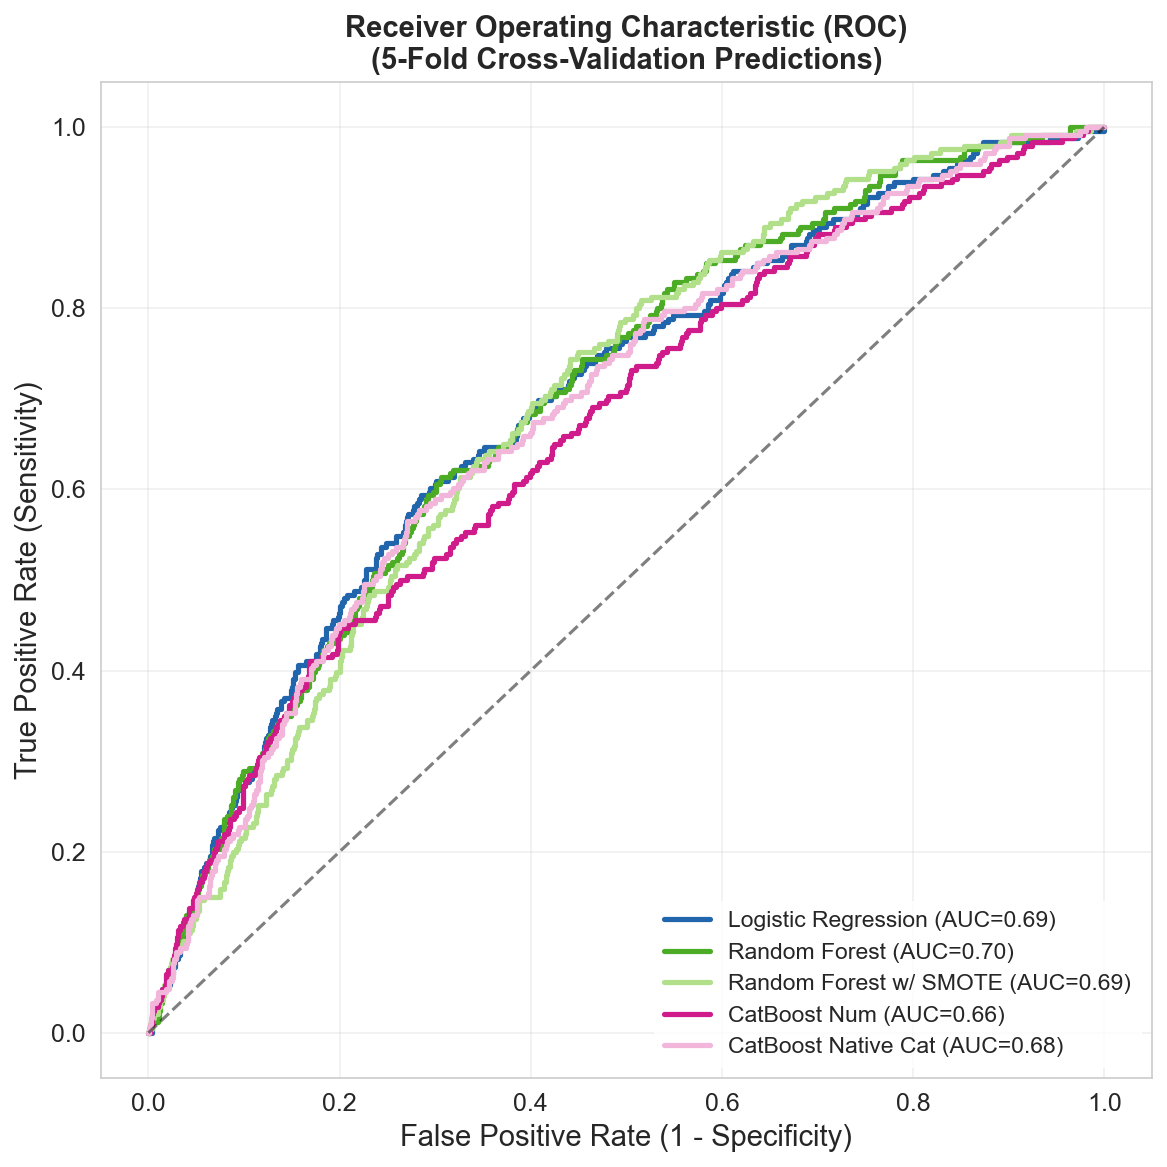

✓ Fig 8 saved


In [8]:
# ── Fig 8: ROC curves — LR vs Random Forest vs CatBoost ───────────────────────
fig, ax = plt.subplots(figsize=(8, 8))

for label, probs, color in [
    (f'Logistic Regression (AUC={lr_auc:.2f})', lr_probs, '#2166ac'),
    (f'Random Forest (AUC={rf_auc:.2f})',       rf_probs, '#4dac26'),
    (f'Random Forest w/ SMOTE (AUC={rf_smote_auc:.2f})', rf_smote_probs, '#b2df8a'),
    (f'CatBoost Num (AUC={cat_auc:.2f})',           cat_probs, '#d01c8b'),
    (f'CatBoost Native Cat (AUC={cat_native_auc:.2f})', cat_native_probs, '#f1b6da'),
]:
    fpr, tpr, _ = roc_curve(y_ml, probs)
    ax.plot(fpr, tpr, label=label, linewidth=2.5, color=color)

ax.plot([0, 1], [0, 1], 'k--', alpha=0.5, linewidth=1.5)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.set_title('Receiver Operating Characteristic (ROC)\n(5-Fold Cross-Validation Predictions)',
             fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=11, frameon=True, edgecolor='white')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/Fig8_ROC_curves.png')
plt.show()
print("✓ Fig 8 saved")

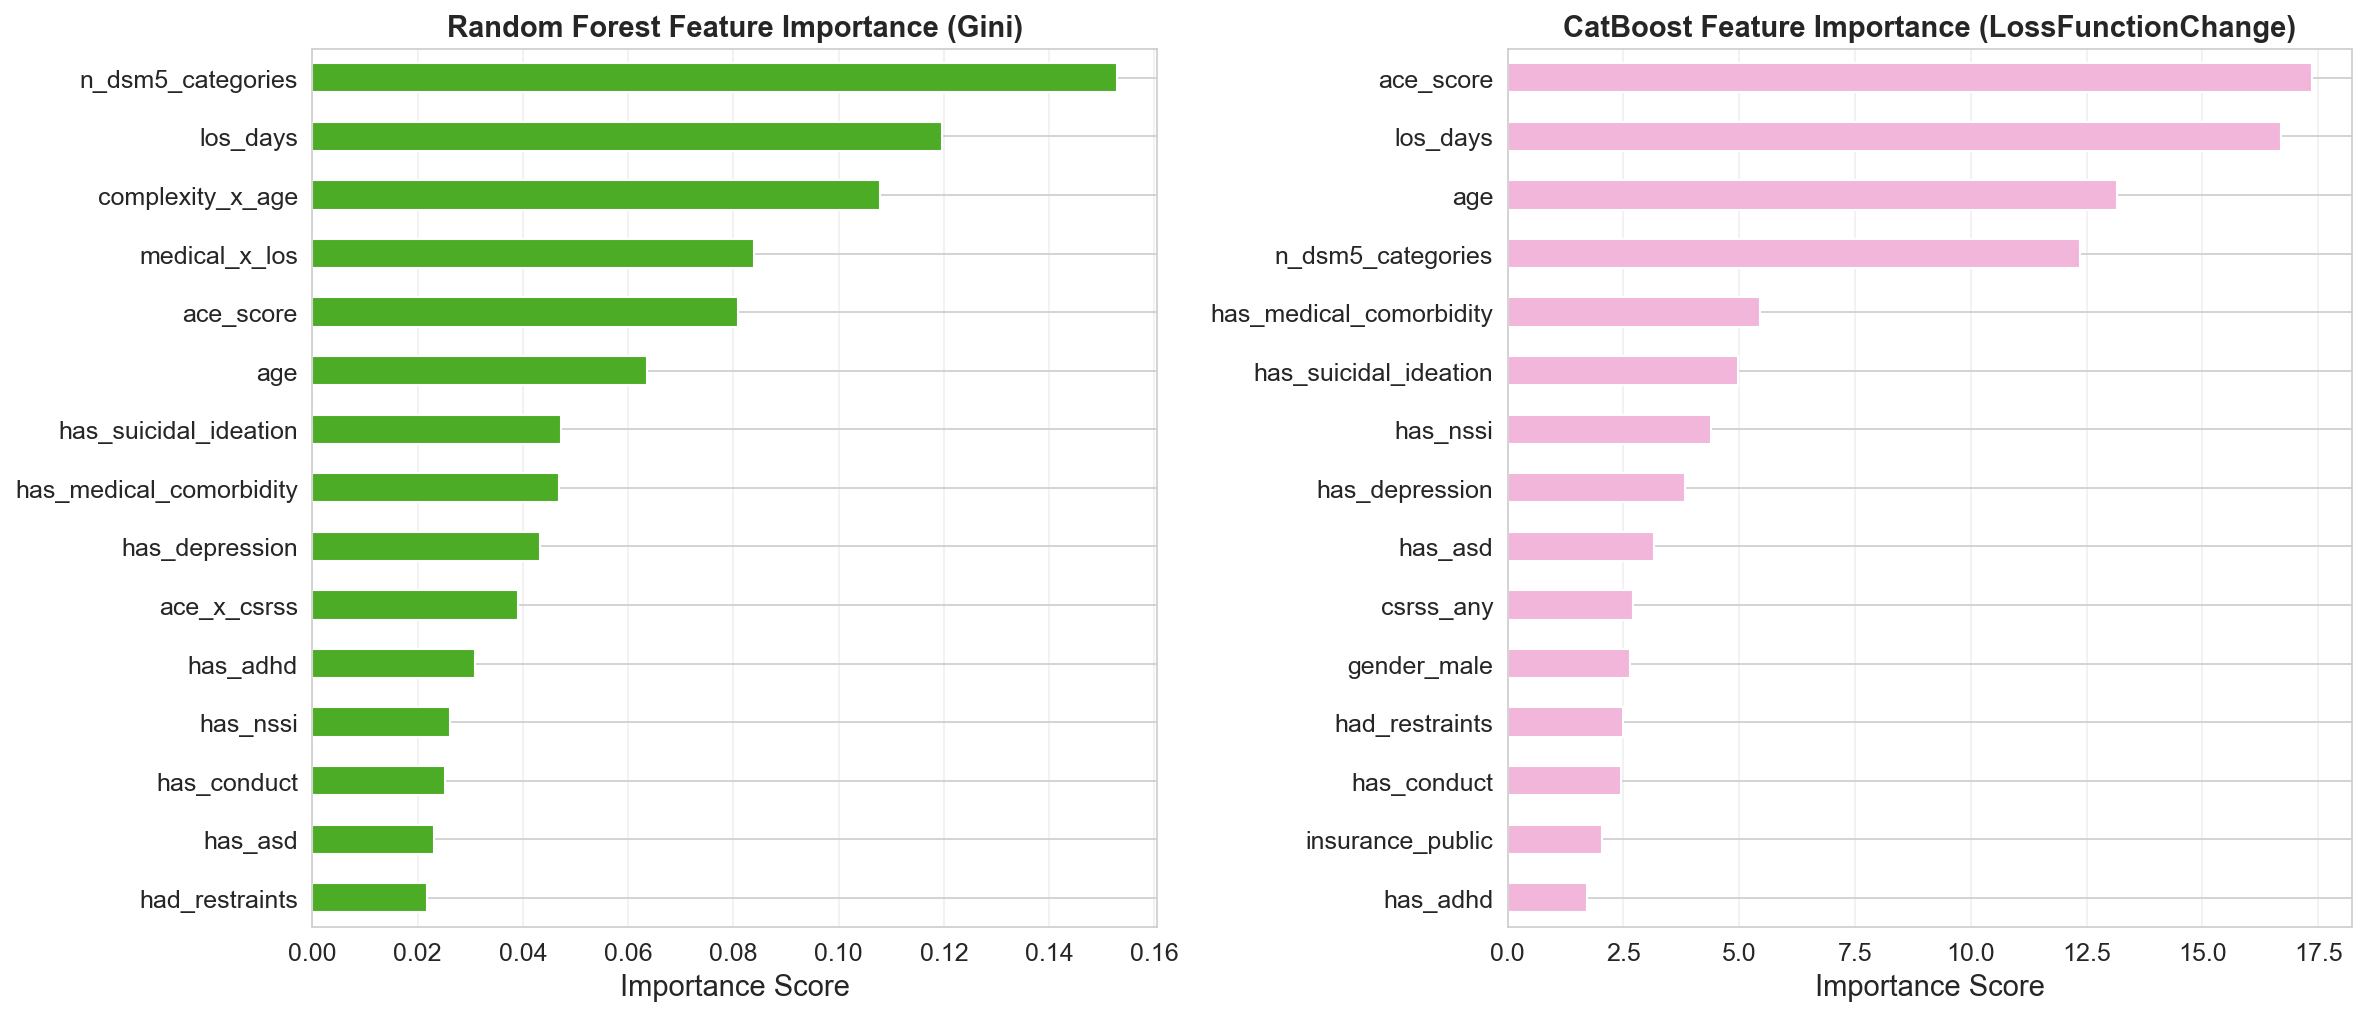

✓ Fig 9 saved


In [9]:
# ── Fig 9: Feature importance — RF vs CatBoost (side-by-side) ────────────────

# Retrain full models for feature importance
rf_full = RandomForestClassifier(
    n_estimators=500, max_depth=6, min_samples_leaf=10,
    class_weight='balanced', random_state=42, n_jobs=-1
)
rf_full.fit(X_ml, y_ml)

cat_full_native = CatBoostClassifier(
    iterations=500, depth=4, learning_rate=0.05,
    auto_class_weights='Balanced', eval_metric='AUC',
    random_seed=42, verbose=0,
    cat_features=cat_features_indices
)
cat_full_native.fit(X_ml_cat, y_ml)

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Random Forest
rf_imp = pd.Series(rf_full.feature_importances_, index=ml_cols).sort_values(ascending=True)
rf_imp.tail(15).plot(kind='barh', ax=axes[0], color='#4dac26', edgecolor='white')
axes[0].set_title('Random Forest Feature Importance (Gini)', fontsize=14, fontweight='bold')
axes[0].set_xlabel('Importance Score')
axes[0].grid(axis='x', alpha=0.3)

# CatBoost
# Ensure we map the feature labels correctly for catboost
cat_imp = pd.Series(cat_full_native.get_feature_importance(), index=feat_cols).sort_values(ascending=True)
cat_imp.tail(15).plot(kind='barh', ax=axes[1], color='#f1b6da', edgecolor='white')
axes[1].set_title('CatBoost Feature Importance (LossFunctionChange)', fontsize=14, fontweight='bold')
axes[1].set_xlabel('Importance Score')
axes[1].grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.savefig('figures/Fig9_Feature_Importance_SideBySide.png')
plt.show()
print("✓ Fig 9 saved")

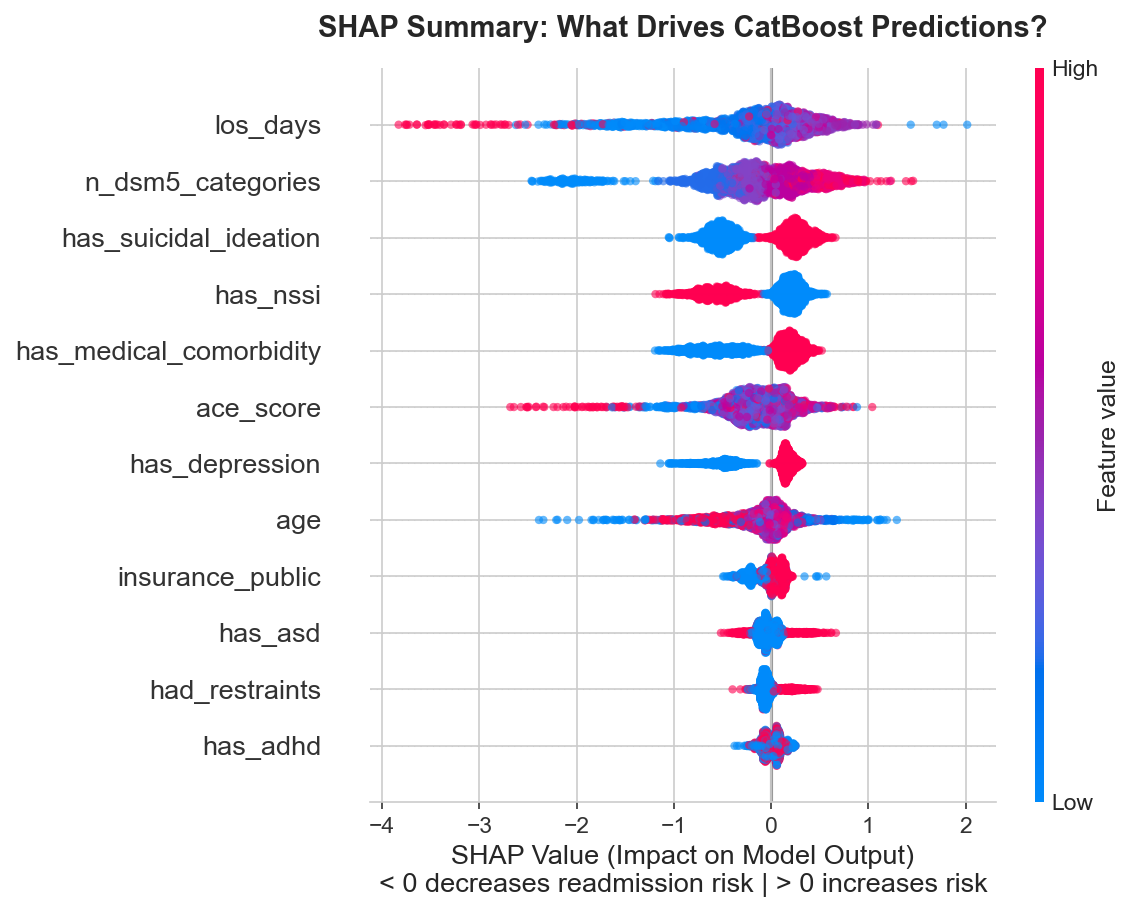

✓ Fig 10 saved


In [10]:
# ── Fig 10: SHAP summary plot (CatBoost trained on full dataset) ───────────────
import shap
explainer = shap.TreeExplainer(cat_full_native)
shap_values = explainer.shap_values(X_ml_cat)

fig = plt.figure(figsize=(10, 8))
shap.summary_plot(shap_values, X_ml_cat, feature_names=feat_cols,
                  show=False, alpha=0.6, max_display=12)

# SHAP plot uses the current figure. Let's tweak its appearance
ax = plt.gca()
ax.set_title('SHAP Summary: What Drives CatBoost Predictions?',
             fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel('SHAP Value (Impact on Model Output)\n< 0 decreases readmission risk | > 0 increases risk')

plt.tight_layout()
plt.savefig('figures/Fig10_SHAP_summary.png')
plt.show()
print("✓ Fig 10 saved")

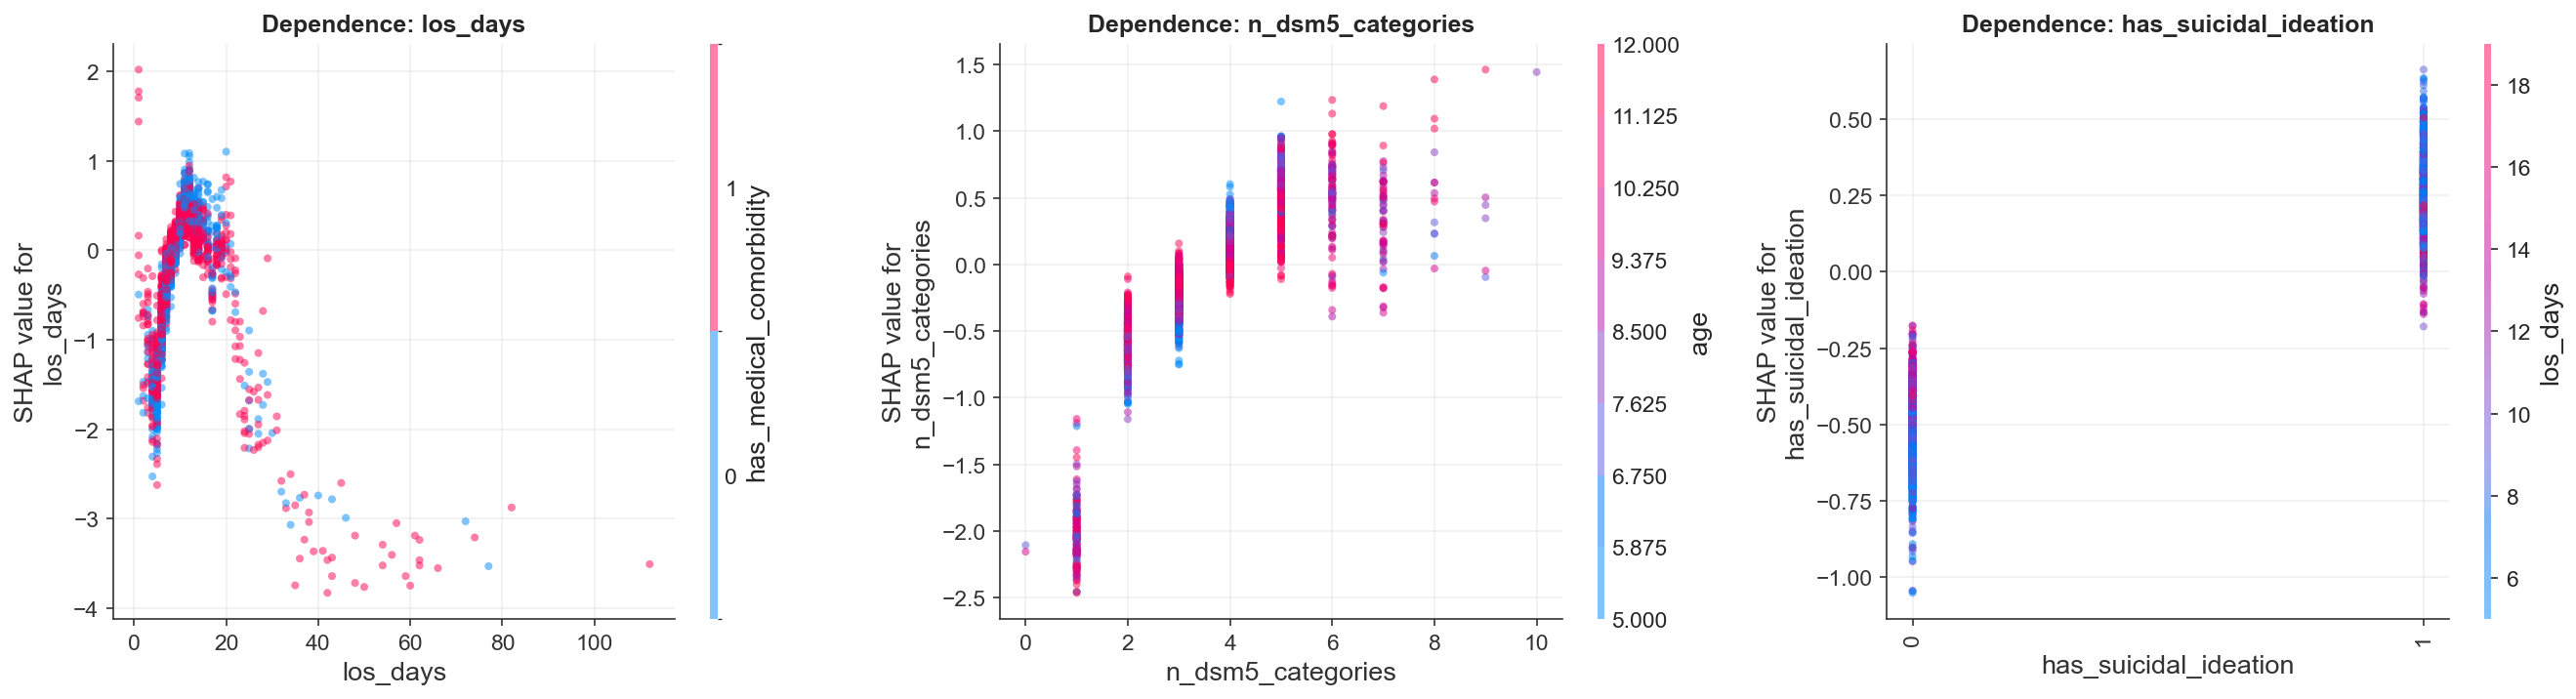

✓ Fig 11 saved


In [11]:
# ── Fig 11: SHAP dependence plots — top 3 CatBoost predictors ──────────────────
# Automatically pick the top 3 features from mean absolute SHAP value
mean_abs_shap = np.abs(shap_values).mean(axis=0)
top3_idx = mean_abs_shap.argsort()[::-1][:3]
top3_feats = [feat_cols[i] for i in top3_idx]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for i, feat in enumerate(top3_feats):
    # Determine what feature to color by (shap tries to do this automatically,
    # but specifying interaction_index=None ensures it just plots the main effect cleanly,
    # or you can let it pick. We let it pick for extra insight.)
    plt.sca(axes[i])
    shap.dependence_plot(feat, shap_values, X_ml_cat, feature_names=feat_cols,
                         ax=axes[i], show=False, alpha=0.5, dot_size=15)
    axes[i].set_title(f'Dependence: {feat}', fontsize=12, fontweight='bold')
    axes[i].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('figures/Fig11_SHAP_dependence.png')
plt.show()
print("✓ Fig 11 saved")

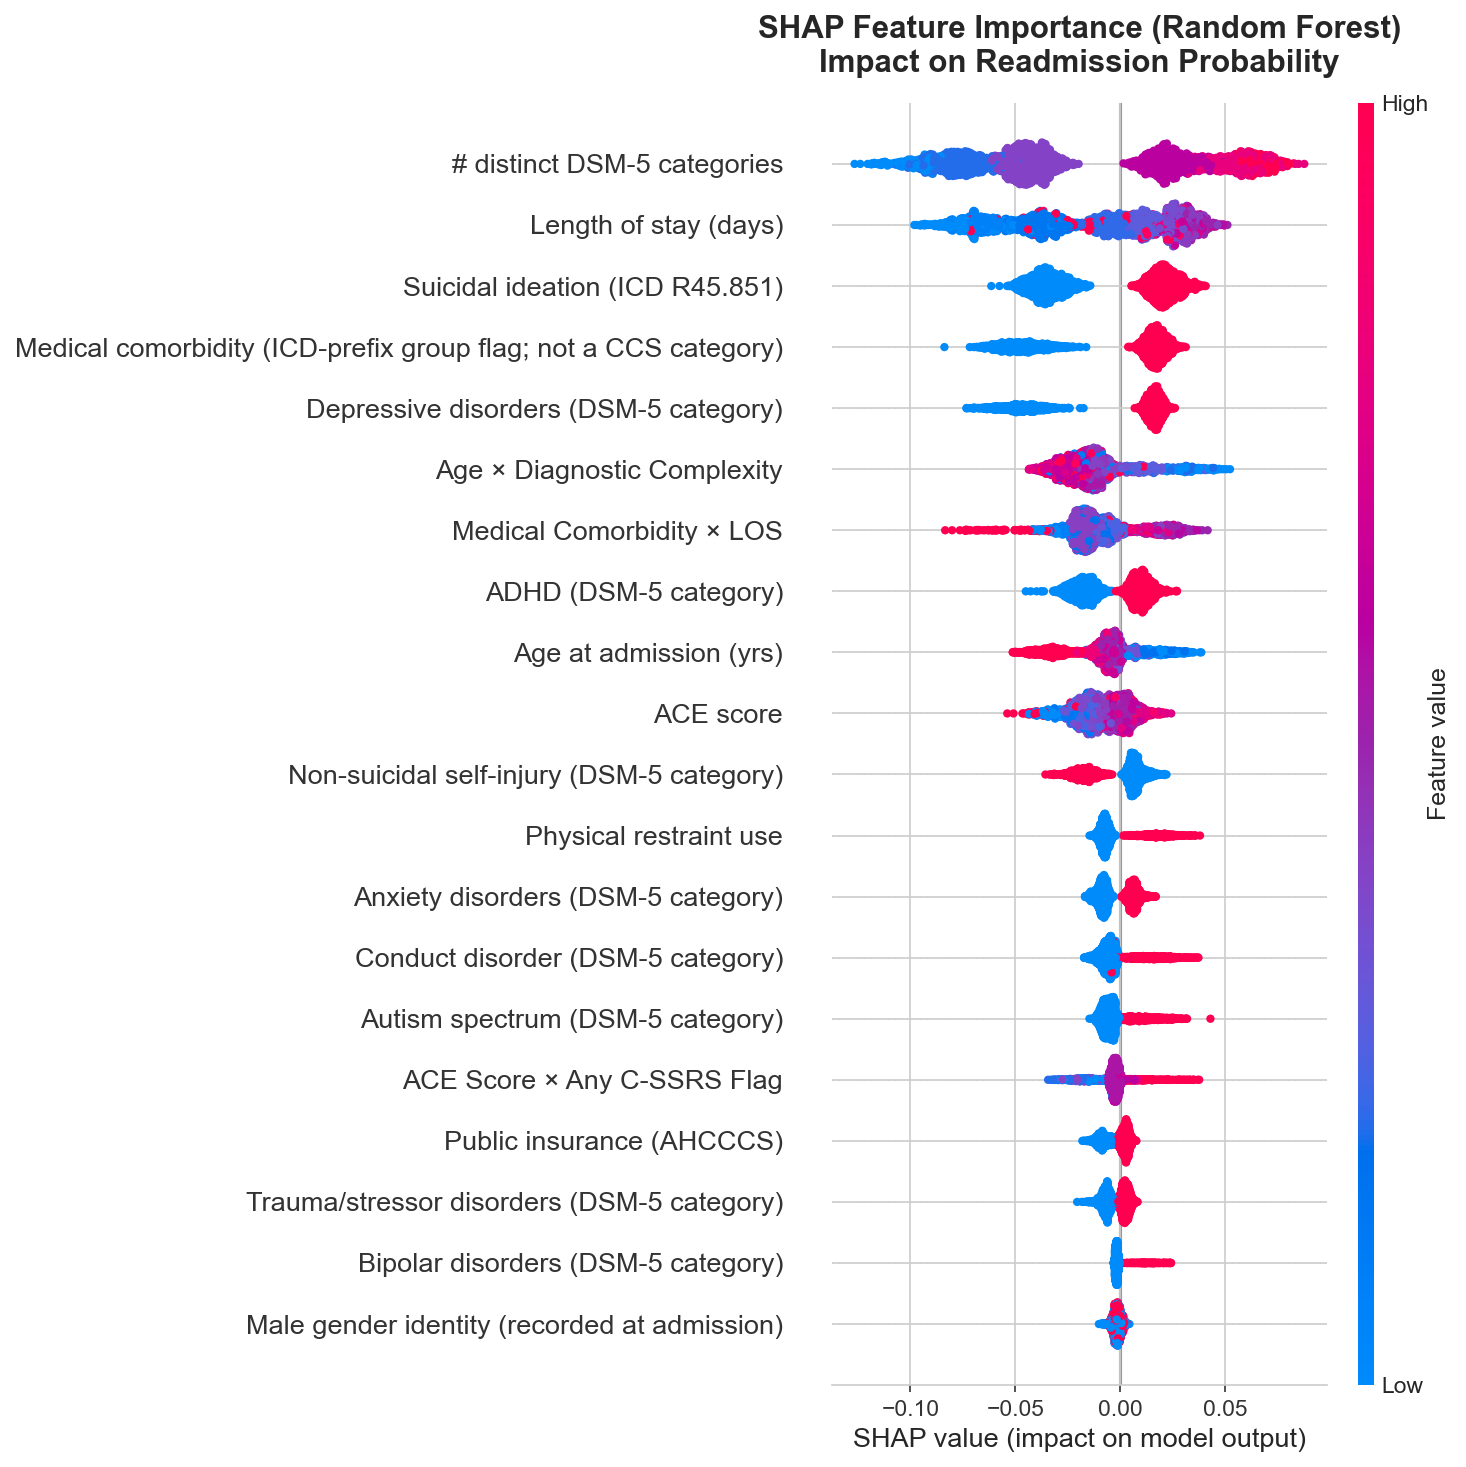

✓ Fig 9b saved


In [12]:
# ── Fig 9b: SHAP summary plot — Random Forest ────────────────────────────────
# rf_full already fitted in the feature importance cell
explainer_rf   = shap.TreeExplainer(rf_full)
shap_values_rf = explainer_rf.shap_values(X_ml)

# Robustly extract class-1 SHAP values across SHAP version formats
if isinstance(shap_values_rf, list):
    shap_rf_pos = shap_values_rf[1]
elif isinstance(shap_values_rf, np.ndarray) and shap_values_rf.ndim == 3:
    shap_rf_pos = shap_values_rf[:, :, 1]
else:
    shap_rf_pos = shap_values_rf

fig, ax = plt.subplots(figsize=(10, 10))
shap.summary_plot(shap_rf_pos, X_ml, feature_names=feature_labels,
                  show=False, plot_size=None, max_display=20)
ax = plt.gca()
ax.set_title('SHAP Feature Importance (Random Forest)\nImpact on Readmission Probability',
             fontsize=15, fontweight='bold', pad=15)
plt.tight_layout()
plt.savefig('figures/Fig9b_SHAP_RF_summary.png')
plt.show()
print("✓ Fig 9b saved")

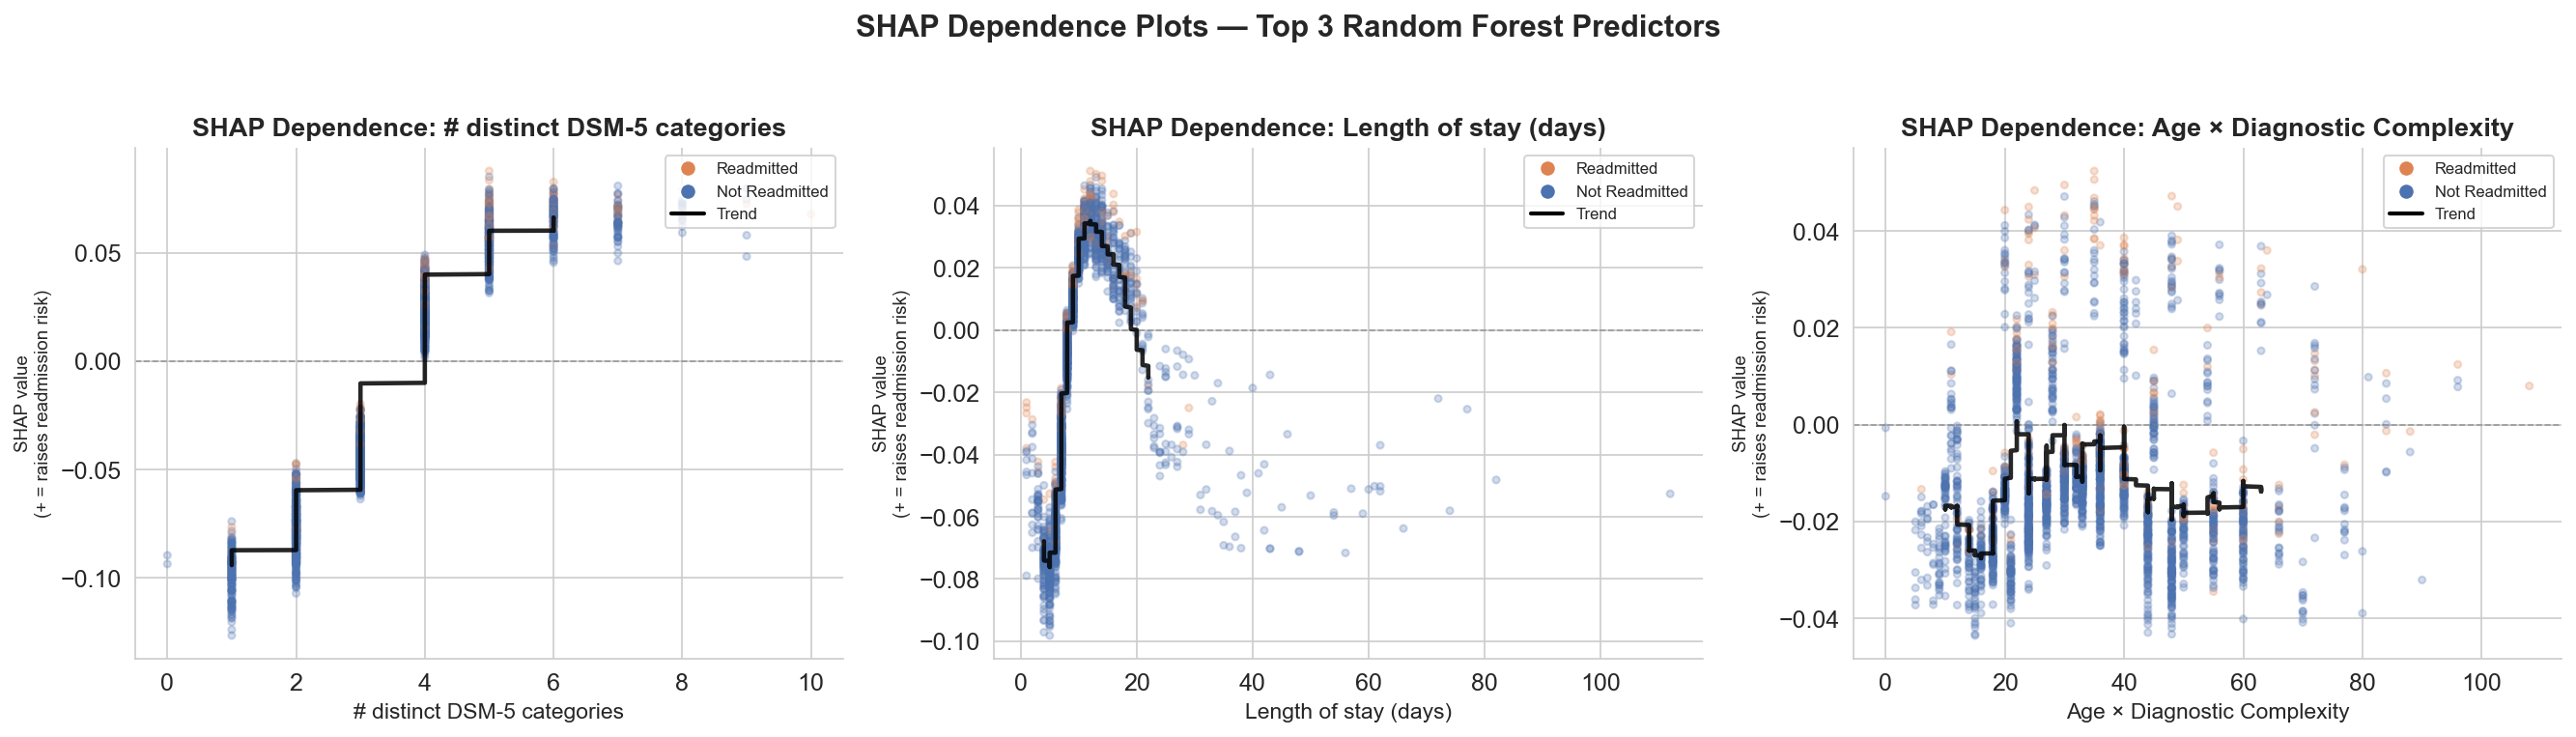

✓ Fig 11b saved


In [13]:
# ── Fig 11b: SHAP dependence plots — top 3 Random Forest predictors ──────────
# Uses manual scatter + running-mean trend (avoids shap.dependence_plot jitter
# that pushes 0-valued binary features into negative x territory).
# Uses unscaled feature values on the x-axis.
rf_imp_top3 = pd.Series(rf_full.feature_importances_, index=ml_cols) \
                .sort_values(ascending=False).head(3).index.tolist()

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat_col in zip(axes, rf_imp_top3):
    feat_idx   = ml_cols.index(feat_col)
    feat_label = all_labels.get(feat_col, feat_col)
    feat_vals  = X_ml_raw[:, feat_idx].copy()
    shap_vals  = shap_rf_pos[:, feat_idx]

    c_vals = [ORANGE if y == 1 else BLUE for y in y_ml]
    ax.scatter(feat_vals, shap_vals, c=c_vals, alpha=0.25, s=12, rasterized=True)
    ax.axhline(0, color='gray', linestyle='--', linewidth=0.8, alpha=0.7)

    sort_idx = np.argsort(feat_vals)
    xs = feat_vals[sort_idx]
    ys = shap_vals[sort_idx]
    win = max(60, len(xs) // 15)
    y_smooth = np.convolve(ys, np.ones(win) / win, mode='valid')
    x_smooth = xs[win // 2: win // 2 + len(y_smooth)]
    ax.plot(x_smooth, y_smooth, 'k-', linewidth=2.2, alpha=0.85, label='Trend')

    ax.set_xlabel(feat_label, fontsize=11)
    ax.set_ylabel('SHAP value\n(+ = raises readmission risk)', fontsize=9)
    ax.set_title(f'SHAP Dependence: {feat_label}', fontsize=13, fontweight='bold')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    from matplotlib.lines import Line2D
    handles = [
        Line2D([0],[0], marker='o', color='w', markerfacecolor=ORANGE, markersize=8, label='Readmitted'),
        Line2D([0],[0], marker='o', color='w', markerfacecolor=BLUE,   markersize=8, label='Not Readmitted'),
        Line2D([0],[0], color='black', linewidth=2, label='Trend'),
    ]
    ax.legend(handles=handles, fontsize=8, loc='upper right')

plt.suptitle('SHAP Dependence Plots — Top 3 Random Forest Predictors',
             fontsize=15, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig11b_SHAP_RF_dependence.png')
plt.show()
print("✓ Fig 11b saved")

In [14]:

# ── Summary: print all saved figures ─────────────────────────────────────────
import glob
figs = sorted(glob.glob('figures/*.png'))
print(f"\n{'='*55}")
print(f"  ANALYSIS COMPLETE — {len(figs)} figures + Table 1 CSV saved")
print(f"{'='*55}")
for f in figs:
    print(f"  {f}")
print(f"\n  Table 1:  figures/Table1_descriptive.csv")
print(f"\n  Model AUC Summary (10-fold out-of-fold):")
print(f"    Logistic Regression      : AUC = {lr_auc:.3f}  |  AP = {lr_ap:.3f}")
print(f"    Random Forest            : AUC = {rf_auc:.3f}  |  AP = {rf_ap:.3f}")
print(f"    Random Forest (SMOTE)    : AUC = {rf_smote_auc:.3f}  |  AP = {rf_smote_ap:.3f}")
print(f"    CatBoost (Numeric)       : AUC = {cat_auc:.3f}  |  AP = {cat_ap:.3f}")
print(f"    CatBoost (Native Cat)    : AUC = {cat_native_auc:.3f}  |  AP = {cat_native_ap:.3f}")



  ANALYSIS COMPLETE — 78 figures + Table 1 CSV saved
  figures/AdvStats_bootstrap_CIs.png
  figures/AdvStats_fairness.png
  figures/AdvStats_optimism_validation.png
  figures/AdvStats_recalibration.png
  figures/Biv_01_distributions.png
  figures/Biv_02_los_by_sex.png
  figures/Biv_03_ace_los.png
  figures/Biv_04_ace_readmit.png
  figures/Biv_04b_suicidality_measures.png
  figures/Biv_05_los_cssrs.png
  figures/Biv_06_restraint_los.png
  figures/Biv_07_ace_insurance.png
  figures/Biv_08_ace_cssrs.png
  figures/Biv_09_restraint_insurance.png
  figures/Biv_10_los_insurance.png
  figures/Biv_12_diagnosis_los.png
  figures/Biv_13_ace_expanded.png
  figures/Biv_14_complexity_measures.png
  figures/Code_subcat3.png
  figures/Code_sweep_readmission.png
  figures/Cohort_Descriptive_Overview.png
  figures/Fig10_SHAP_summary.png
  figures/Fig10_feature_importance.png
  figures/Fig11_SHAP_dependence.png
  figures/Fig11b_SHAP_RF_dependence.png
  figures/Fig12_FAMD_UMAP.png
  figures/Fig12b_UMAP_f

In [15]:
# ── FAMD: Factor Analysis of Mixed Data ───────────────────────────────────────
# We use FAMD to capture linear/global variance across continuous and categorical data
# before projecting it into a nonlinear UMAP manifold.
import prince

famd = prince.FAMD(
    n_components=10,
    n_iter=10,
    copy=True,
    check_input=True,
    engine='sklearn',
    random_state=42
)

# Convert categorical features to category dtype for prince
famd_df = pd.DataFrame(X_ml_raw, columns=ml_cols).copy()
famd_cat_cols = ['gender_male', 'insurance_public', 'had_restraints', 'csrss_any', 'has_medical_comorbidity']
famd_cat_cols += [c for c in FEATURES.keys() if c.startswith('has_') and c != 'has_medical_comorbidity']
famd_cont_cols = [c for c in ml_cols if c not in famd_cat_cols]

for c in famd_cat_cols:
    famd_df[c] = famd_df[c].astype(int).astype('category')

famd = famd.fit(famd_df)
famd_coords = famd.transform(famd_df)

print("FAMD % variance explained by component:")
# Handle different prince versions (explained_inertia_ vs percentage_of_variance_)
# In newer prince versions, it's a series or array inside percentage_of_variance_ or simply not available in the same way.
if hasattr(famd, 'percentage_of_variance_'):
    pov = famd.percentage_of_variance_
elif hasattr(famd, 'explained_inertia_'):
    pov = famd.explained_inertia_ * 100
else:
    # If not accessible, create a dummy for printing purposes
    pov = [0]*10

for i, v in enumerate(pov):
    print(f"  PC{i+1}: {v:.1f}%")
print(f"  Total (10 PCs): {sum(pov):.1f}%")

FAMD % variance explained by component:
  PC1: 13.9%
  PC2: 12.3%
  PC3: 9.1%
  PC4: 7.8%
  PC5: 5.9%
  PC6: 5.2%
  PC7: 4.6%
  PC8: 4.5%
  PC9: 4.4%
  PC10: 4.1%
  Total (10 PCs): 71.7%


In [ ]:

# ── Fig 12: UMAP embedding of FAMD components ─────────────────────────────────
reducer = umap.UMAP(n_components=2, n_neighbors=30, min_dist=0.1,
                    metric='euclidean', random_state=42)
embedding = reducer.fit_transform(famd_coords)

# ── Inline: top Spearman correlate per UMAP axis (for axis labels) ────────────
# UMAP axes are abstract; this identifies the single raw feature most correlated
# with each axis to provide a navigational hint. Cell 18 shows the full ranking.
from scipy.stats import spearmanr as _sr
_u1 = [(_sr(embedding[:, 0], X_ml_raw[:, i])[0], feature_labels[i]) for i in range(len(ml_cols))]
_u2 = [(_sr(embedding[:, 1], X_ml_raw[:, i])[0], feature_labels[i]) for i in range(len(ml_cols))]
_top1 = max(_u1, key=lambda x: abs(x[0]))[1]
_top2 = max(_u2, key=lambda x: abs(x[0]))[1]
_umap1_label = f'UMAP 1  (top correlate: {_top1})'
_umap2_label = f'UMAP 2  (top correlate: {_top2})'

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

mask_nr = y_ml == 0
mask_r  = y_ml == 1
axes[0].scatter(embedding[mask_nr, 0], embedding[mask_nr, 1],
                c=BLUE, alpha=0.25, s=12,
                label=f'Not Readmitted (n={mask_nr.sum()})', rasterized=True)
axes[0].scatter(embedding[mask_r, 0], embedding[mask_r, 1],
                c=ORANGE, alpha=0.75, s=25,
                label=f'Readmitted (n={mask_r.sum()})', rasterized=True)
axes[0].set_xlabel(_umap1_label)
axes[0].set_ylabel(_umap2_label)
axes[0].set_title('UMAP of FAMD Components\nColored by Readmission Status',
                  fontsize=14, fontweight='bold')
axes[0].legend(fontsize=11, markerscale=2)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

sc = axes[1].scatter(embedding[:, 0], embedding[:, 1],
                     c=cat_probs, cmap='RdYlBu_r', alpha=0.5, s=12,
                     vmin=0, vmax=0.6, rasterized=True)
plt.colorbar(sc, ax=axes[1], label='CatBoost Predicted P(Readmission)')
axes[1].set_xlabel(_umap1_label)
axes[1].set_ylabel(_umap2_label)
axes[1].set_title('UMAP of FAMD Components\nContinuous Readmission Risk',
                  fontsize=14, fontweight='bold')
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Unsupervised Pattern Discovery: FAMD + UMAP\n'
             '(n=2,652 psychiatric admissions; axes are abstract embedding coordinates)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig12_FAMD_UMAP.png')
plt.show()
print("✓ Fig 12 saved")


── Top correlates with UMAP 1 ──────────────────────────────────────────
  has_medical_comorbidity              r = -0.451  ***
  csrss_any                            r = -0.408  ***
  has_bipolar                          r = +0.375  ***
  has_psychotic                        r = +0.247  ***
  had_restraints                       r = +0.170  ***
  has_nssi                             r = -0.113  ***
  gender_male                          r = +0.112  ***
  los_days                             r = +0.112  ***
  has_depression                       r = -0.106  ***
  has_adhd                             r = +0.097  ***
  has_suicidal_ideation                r = -0.084  ***
  has_conduct                          r = +0.075  ***

── Top correlates with UMAP 2 ──────────────────────────────────────────
  has_medical_comorbidity              r = -0.774  ***
  has_psychotic                        r = -0.245  ***
  csrss_any                            r = +0.202  ***
  n_dsm5_categories         

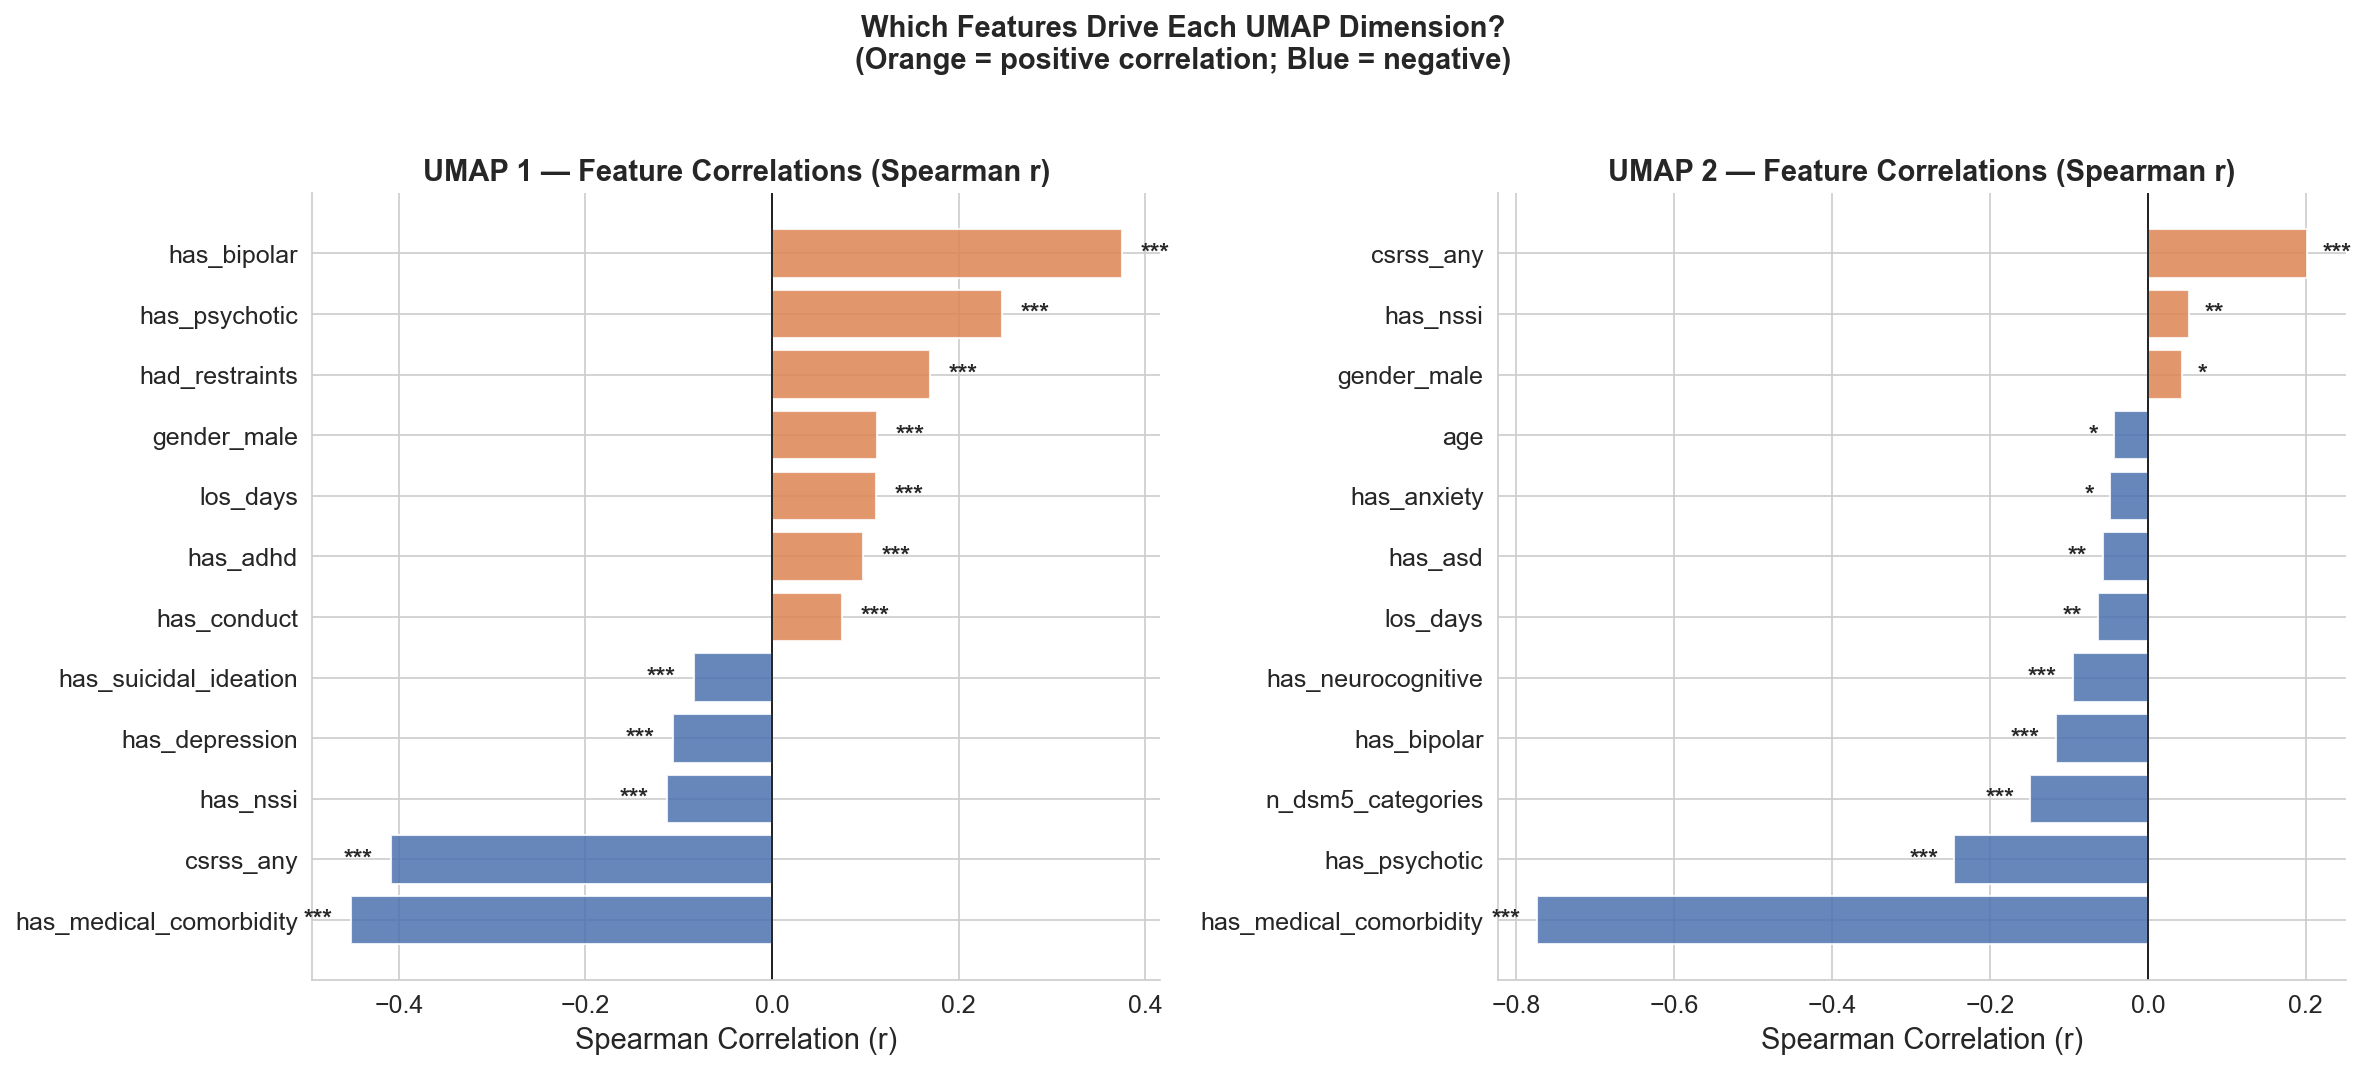

✓ Fig 12b saved


In [17]:
# ── UMAP Axis Interpretation: Spearman correlations with all features ──────────
from scipy.stats import spearmanr

corr_records = []
for i, feat in enumerate(feat_cols):
    r1, p1 = spearmanr(embedding[:, 0], X_ml_raw[:, i])
    r2, p2 = spearmanr(embedding[:, 1], X_ml_raw[:, i])
    corr_records.append({'feature': feat, 'r_umap1': r1, 'p_umap1': p1,
                         'r_umap2': r2, 'p_umap2': p2})

corr_df = pd.DataFrame(corr_records)
top_u1  = corr_df.reindex(corr_df['r_umap1'].abs().sort_values(ascending=False).index).head(12)
top_u2  = corr_df.reindex(corr_df['r_umap2'].abs().sort_values(ascending=False).index).head(12)

print("── Top correlates with UMAP 1 ──────────────────────────────────────────")
for _, row in top_u1.iterrows():
    sig = '***' if row['p_umap1'] < 0.001 else ('**' if row['p_umap1'] < 0.01 else '*' if row['p_umap1'] < 0.05 else '')
    print(f"  {row['feature']:<35}  r = {row['r_umap1']:+.3f}  {sig}")

print("\n── Top correlates with UMAP 2 ──────────────────────────────────────────")
for _, row in top_u2.iterrows():
    sig = '***' if row['p_umap2'] < 0.001 else ('**' if row['p_umap2'] < 0.01 else '*' if row['p_umap2'] < 0.05 else '')
    print(f"  {row['feature']:<35}  r = {row['r_umap2']:+.3f}  {sig}")

# ── Ranked bar charts ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

for ax, top_df, rcol, pcol, title in [
    (axes[0], top_u1, 'r_umap1', 'p_umap1', 'UMAP 1 — Feature Correlations (Spearman r)'),
    (axes[1], top_u2, 'r_umap2', 'p_umap2', 'UMAP 2 — Feature Correlations (Spearman r)'),
]:
    top_df = top_df.sort_values(rcol)
    colors = [ORANGE if r > 0 else BLUE for r in top_df[rcol]]
    bars = ax.barh(top_df['feature'], top_df[rcol], color=colors, alpha=0.85, edgecolor='white')
    ax.axvline(0, color='black', linewidth=0.8)
    # Star annotations
    for bar, (_, row) in zip(bars, top_df.iterrows()):
        p = row[pcol]
        sig = '***' if p < 0.001 else ('**' if p < 0.01 else '*' if p < 0.05 else '')
        x = row[rcol]
        align = 'left' if x > 0 else 'right'
        offset = 0.02 if x > 0 else -0.02
        ax.text(x + offset, bar.get_y() + bar.get_height()/2, sig,
                va='center', ha=align, fontsize=12, fontweight='bold')
        
    ax.set_title(title, fontsize=14, fontweight='bold')
    ax.set_xlabel('Spearman Correlation (r)')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('Which Features Drive Each UMAP Dimension?\n'
             '(Orange = positive correlation; Blue = negative)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig12b_UMAP_feature_correlations.png')
plt.show()
print("✓ Fig 12b saved")

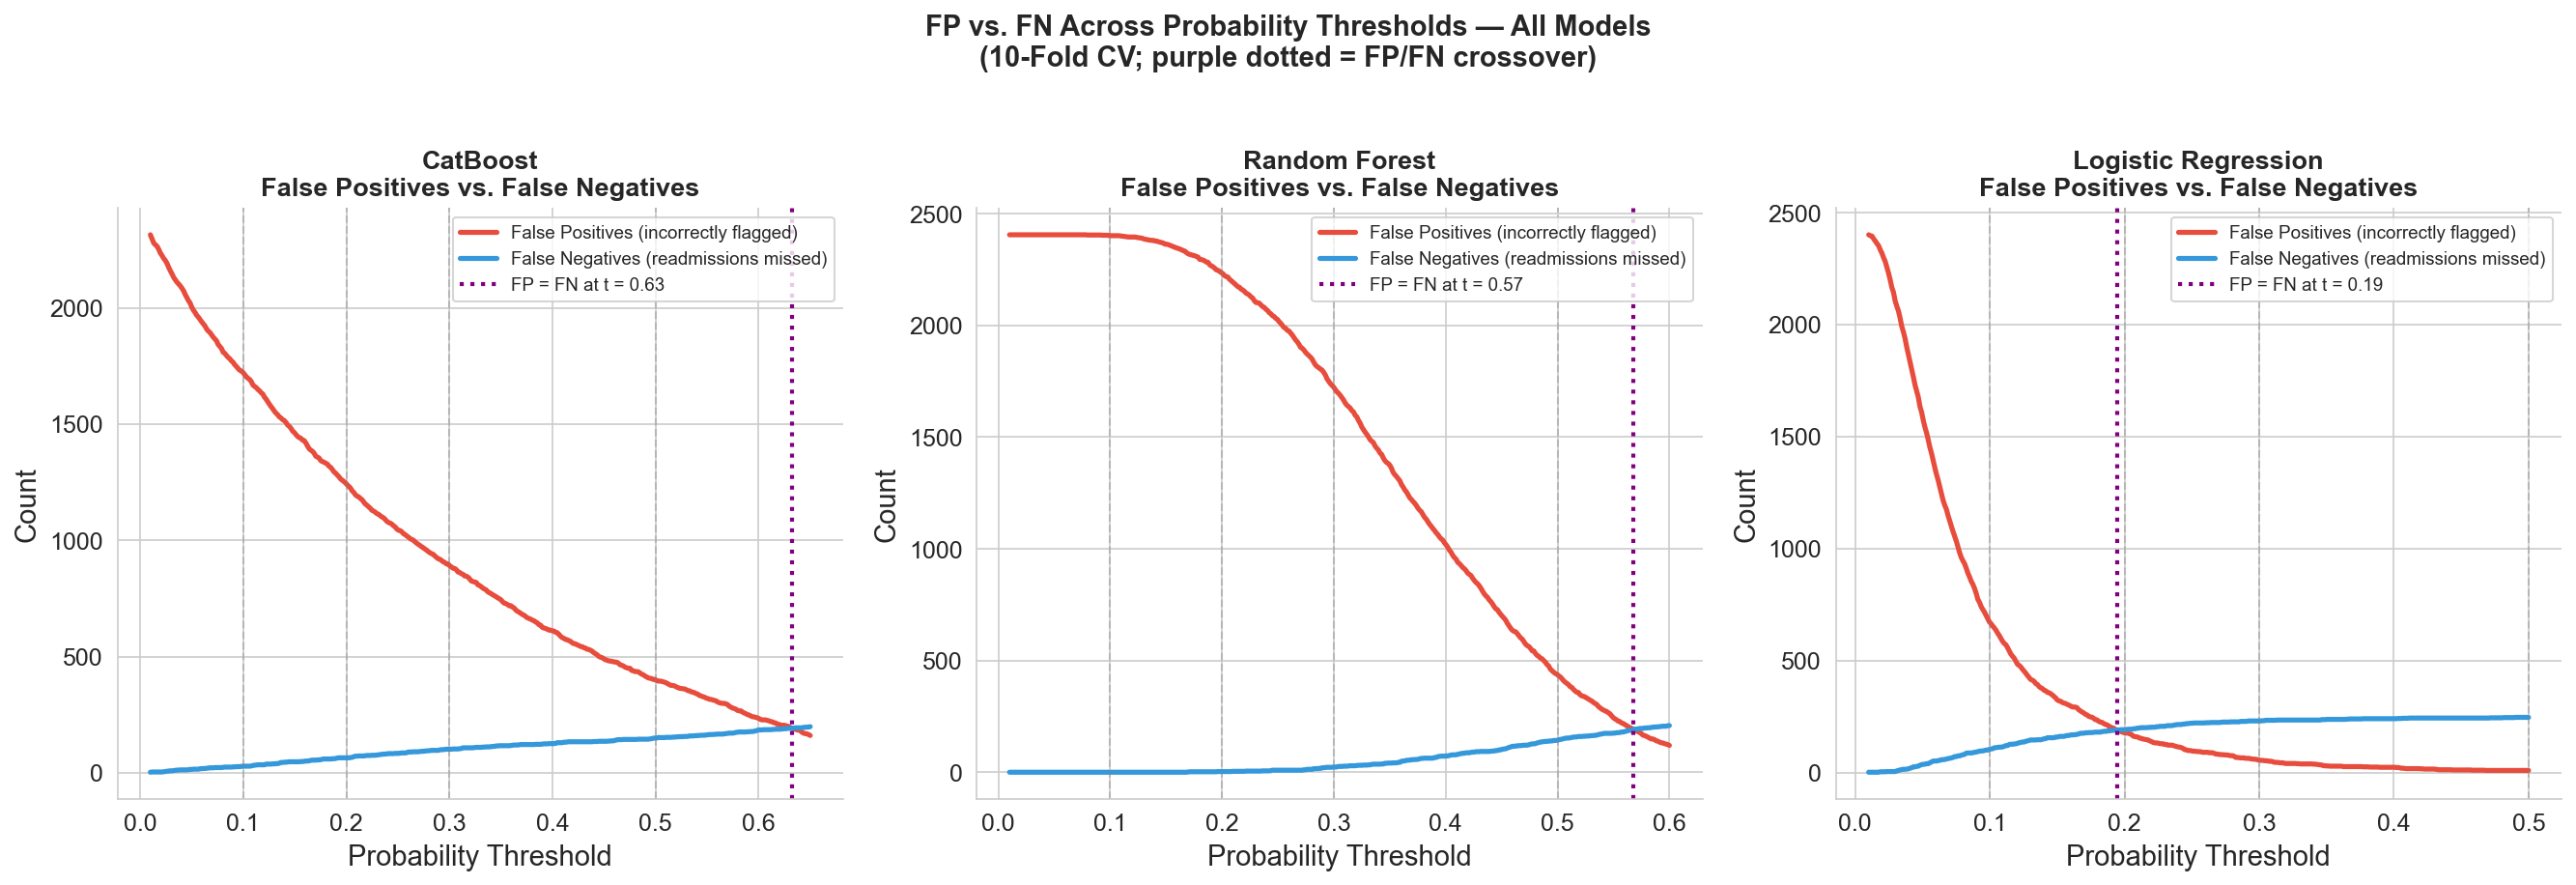

✓ Fig 13 saved


In [18]:

# ── Fig 13: FP vs FN across thresholds — all three models ─────────────────────
model_configs = [
    ('CatBoost',            cat_probs, '#d01c8b', 0.65),
    ('Random Forest',       rf_probs,  '#4dac26', 0.60),
    ('Logistic Regression', lr_probs,  '#2166ac', 0.50),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 6))

for ax, (name, probs, color, max_thresh) in zip(axes, model_configs):
    thresh_range = np.linspace(0.01, max_thresh, 400)
    fp_list, fn_list = [], []
    for t in thresh_range:
        preds = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()
        fp_list.append(fp)
        fn_list.append(fn)

    crossover_idx = np.argmin(np.abs(np.array(fp_list) - np.array(fn_list)))
    crossover_t   = thresh_range[crossover_idx]

    ax.plot(thresh_range, fp_list, color='#e74c3c', linewidth=2.5,
            label='False Positives (incorrectly flagged)')
    ax.plot(thresh_range, fn_list, color='#3498db', linewidth=2.5,
            label='False Negatives (readmissions missed)')
    ax.axvline(crossover_t, color='purple', linestyle=':', linewidth=2,
               label=f'FP = FN at t = {crossover_t:.2f}')

    # Ref lines
    for t_ref in [0.10, 0.20, 0.30, 0.50]:
        if t_ref <= max_thresh:
            ax.axvline(t_ref, color='gray', linestyle='--', alpha=0.35, linewidth=1)

    ax.set_xlabel('Probability Threshold')
    ax.set_ylabel('Count')
    ax.set_title(f'{name}\nFalse Positives vs. False Negatives', fontsize=13, fontweight='bold')
    ax.legend(fontsize=9)
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

plt.suptitle('FP vs. FN Across Probability Thresholds — All Models\n'
             '(10-Fold CV; purple dotted = FP/FN crossover)',
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.savefig('figures/Fig13_FP_vs_FN.png')
plt.show()
print("✓ Fig 13 saved")


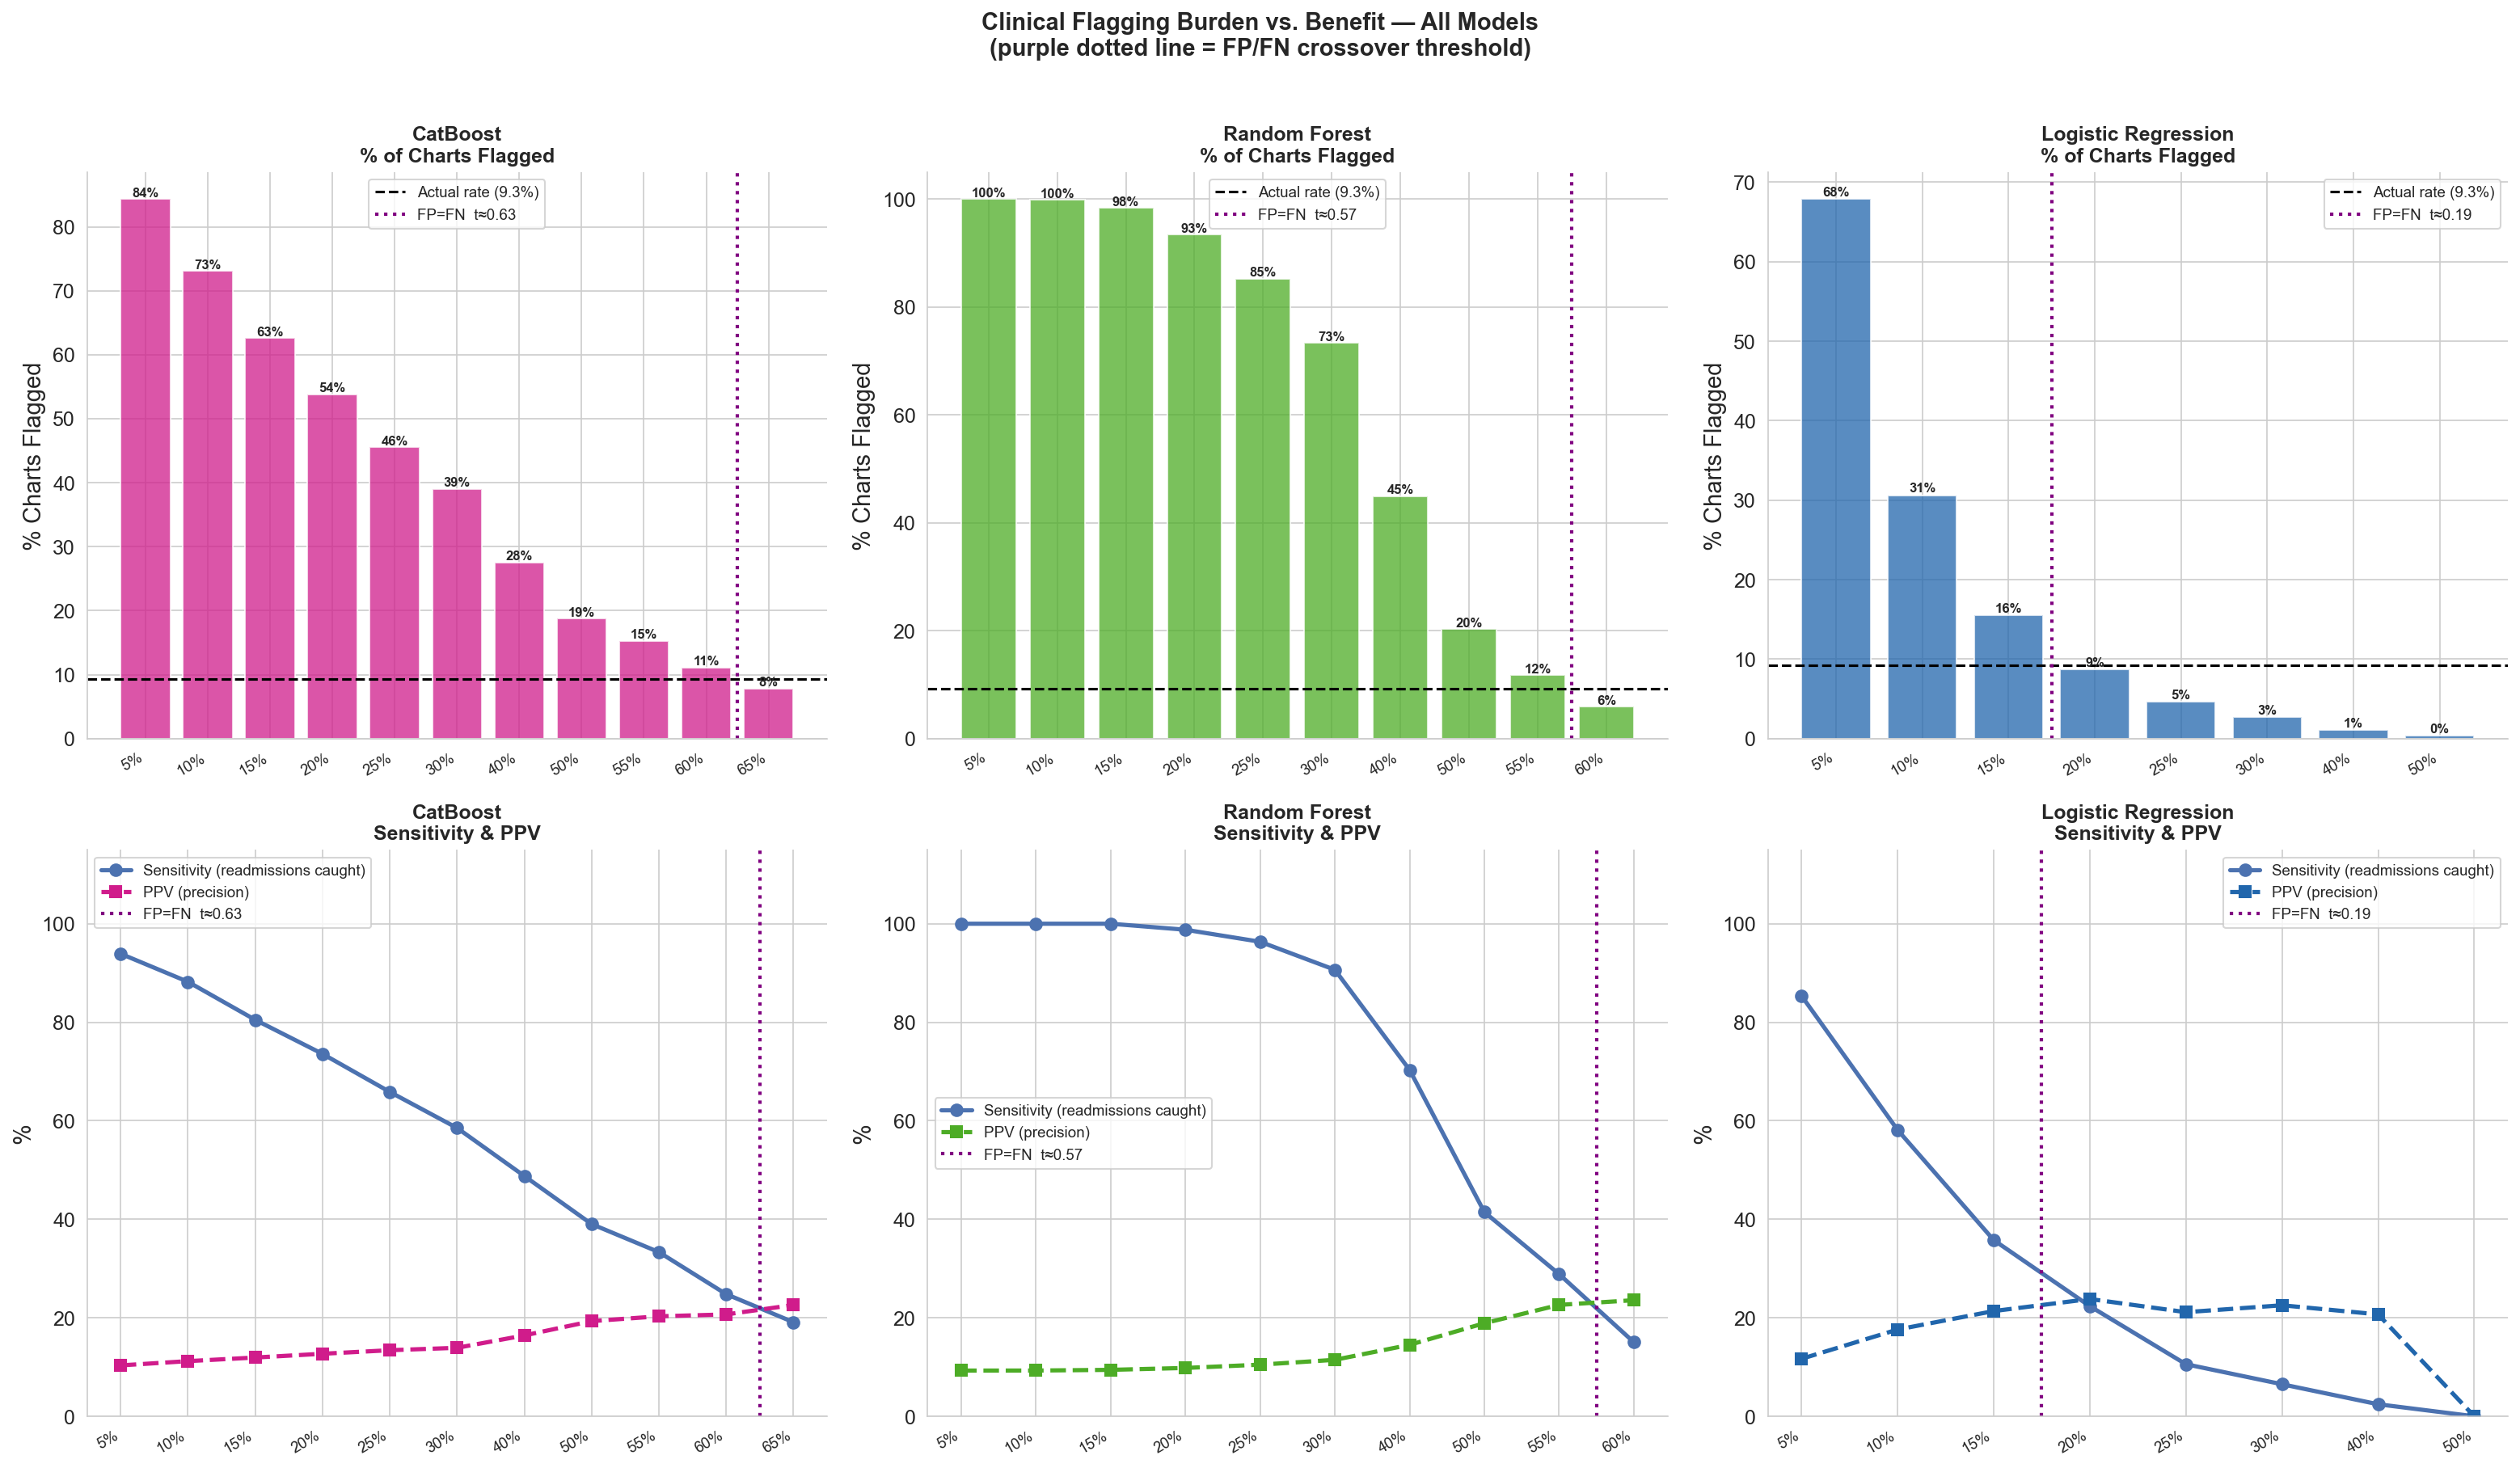

✓ Fig 14 saved


In [19]:
# ── Fig 14: Burden vs Benefit — all models, extended thresholds ───────────────
model_configs = [
    ('CatBoost',            cat_probs, '#d01c8b', 0.65),
    ('Random Forest',       rf_probs,  '#4dac26', 0.60),
    ('Logistic Regression', lr_probs,  '#2166ac', 0.50),
]

n_total = len(y_ml)
n_pos   = y_ml.sum()

fig, axes = plt.subplots(2, 3, figsize=(21, 12))

for col, (name, probs, color, max_thresh) in enumerate(model_configs):
    thresh_full = np.linspace(0.01, max_thresh, 400)
    fp_full, fn_full = [], []
    for t in thresh_full:
        preds = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()
        fp_full.append(fp)
        fn_full.append(fn)
    crossover_t = thresh_full[np.argmin(np.abs(np.array(fp_full) - np.array(fn_full)))]

    base_ts = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30, 0.40, 0.50]
    extra   = [t for t in [0.55, 0.60, 0.65] if t <= max_thresh]
    key_ts  = base_ts + extra

    flag_pcts, sensitivities, ppvs = [], [], []
    for t in key_ts:
        preds  = (probs >= t).astype(int)
        tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()
        flag_pcts.append(100 * preds.sum() / n_total)
        sensitivities.append(100 * tp / (tp + fn) if (tp + fn) > 0 else 0)
        ppvs.append(100 * tp / (tp + fp) if (tp + fp) > 0 else 0)

    xlabels = [f'{int(t*100)}%' for t in key_ts]
    x_pos   = np.arange(len(key_ts))
    crossover_x = next((xi - 0.5 for xi, t in enumerate(key_ts) if t >= crossover_t), None)

    ax0 = axes[0, col]
    bars = ax0.bar(x_pos, flag_pcts, color=color, alpha=0.75, edgecolor='white')
    ax0.axhline(100 * n_pos / n_total, color='black', linestyle='--', linewidth=1.5,
                label=f'Actual rate ({100*n_pos/n_total:.1f}%)')
    if crossover_x is not None:
        ax0.axvline(crossover_x, color='purple', linestyle=':', linewidth=2,
                    label=f'FP=FN  t≈{crossover_t:.2f}')
    ax0.set_xticks(x_pos)
    ax0.set_xticklabels(xlabels, rotation=30, ha='right', fontsize=9)
    for bar, pct in zip(bars, flag_pcts):
        ax0.text(bar.get_x() + bar.get_width()/2, pct + 0.4,
                 f'{pct:.0f}%', ha='center', fontsize=8, fontweight='bold')
    ax0.set_ylabel('% Charts Flagged')
    ax0.set_title(f'{name}\n% of Charts Flagged', fontsize=12, fontweight='bold')
    ax0.legend(fontsize=9)
    ax0.spines['top'].set_visible(False)
    ax0.spines['right'].set_visible(False)

    ax1 = axes[1, col]
    ax1.plot(x_pos, sensitivities, 'o-', color=BLUE,  linewidth=2.5, markersize=7,
             label='Sensitivity (readmissions caught)')
    ax1.plot(x_pos, ppvs,          's--', color=color, linewidth=2.5, markersize=7,
             label='PPV (precision)')
    if crossover_x is not None:
        ax1.axvline(crossover_x, color='purple', linestyle=':', linewidth=2,
                    label=f'FP=FN  t≈{crossover_t:.2f}')
    ax1.set_xticks(x_pos)
    ax1.set_xticklabels(xlabels, rotation=30, ha='right', fontsize=9)
    ax1.set_ylabel('%')
    ax1.set_ylim(0, 115)
    ax1.set_title(f'{name}\nSensitivity & PPV', fontsize=12, fontweight='bold')
    ax1.legend(fontsize=9)
    ax1.spines['top'].set_visible(False)
    ax1.spines['right'].set_visible(False)

plt.suptitle('Clinical Flagging Burden vs. Benefit — All Models\n'
             '(purple dotted line = FP/FN crossover threshold)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/Fig14_flagging_thresholds.png')
plt.show()
print("✓ Fig 14 saved")

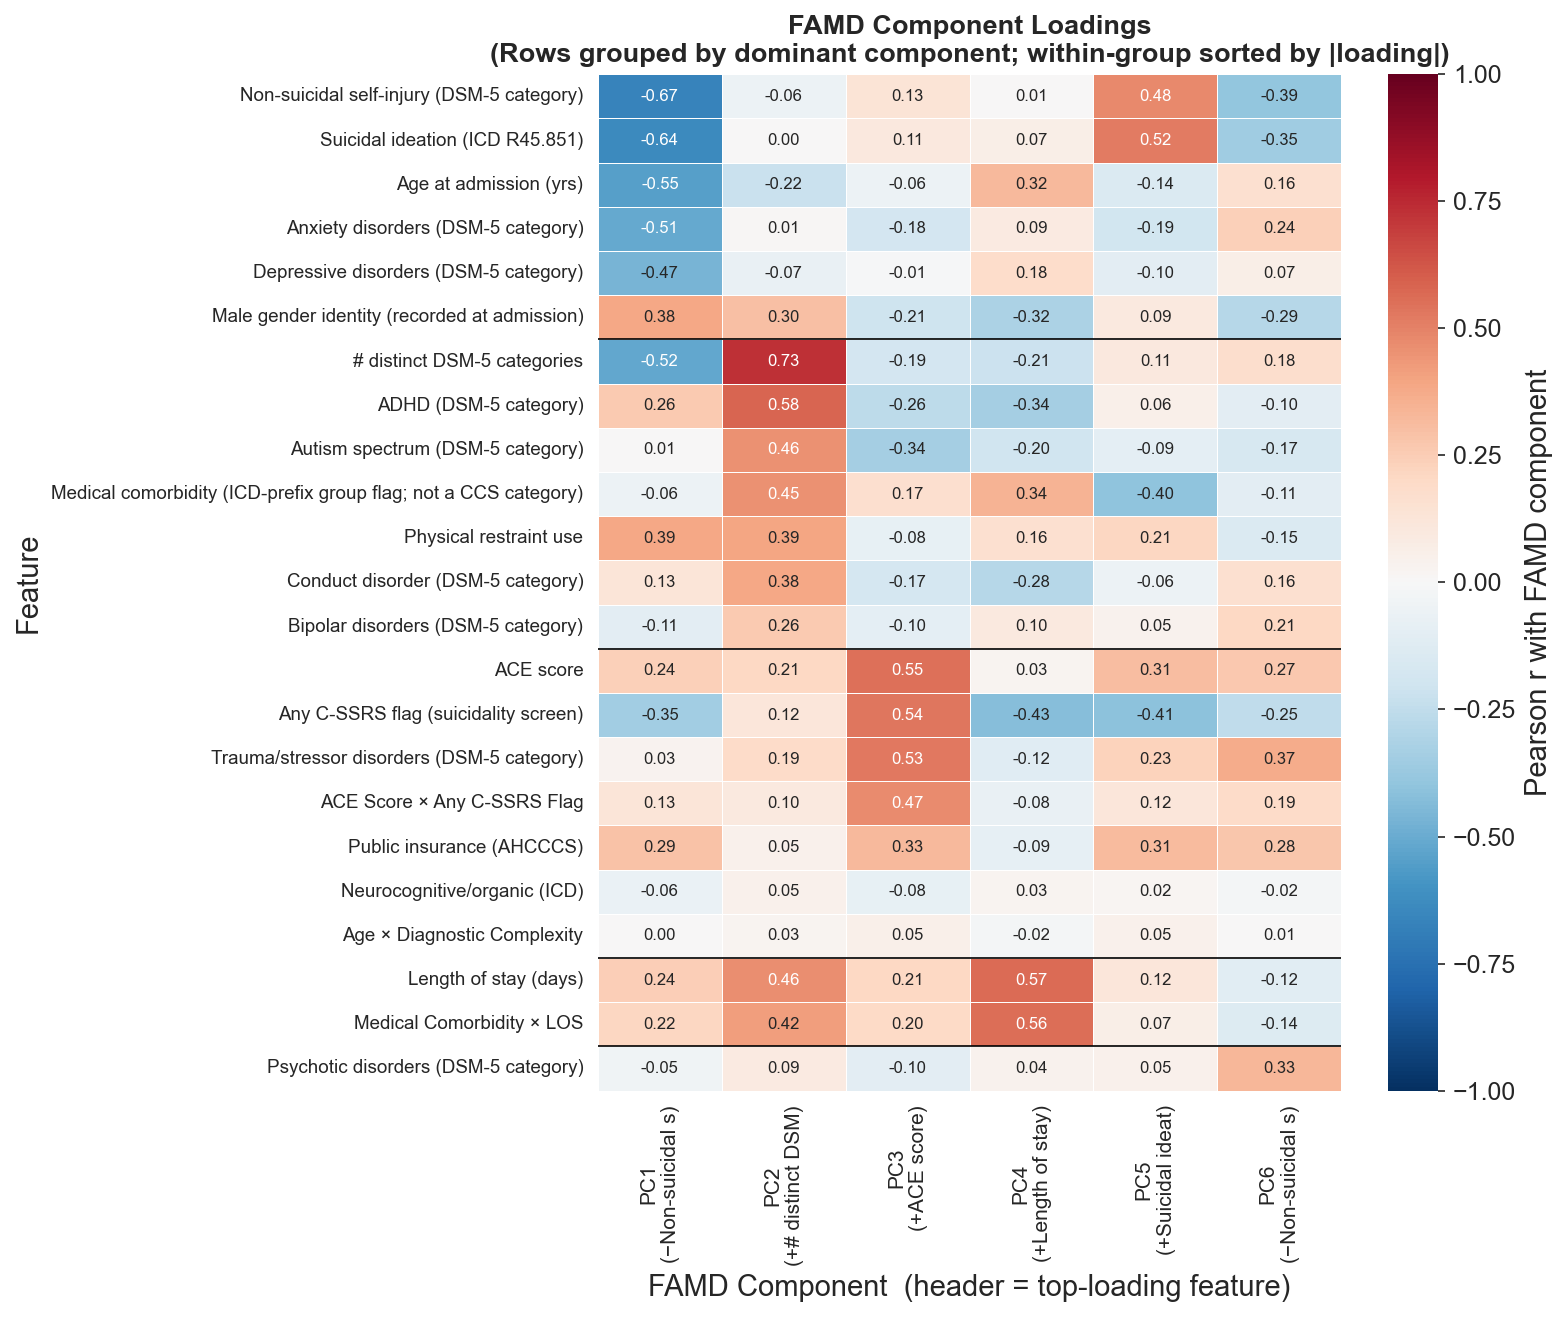

✓ FAMD loadings saved

PC dominant features:
  PC1  top feature: Non-suicidal self-injury (DSM-5 category)  (r=-0.669)
  PC2  top feature: # distinct DSM-5 categories  (r=+0.729)
  PC3  top feature: ACE score  (r=+0.550)
  PC4  top feature: Length of stay (days)  (r=+0.567)
  PC5  top feature: Suicidal ideation (ICD R45.851)  (r=+0.516)
  PC6  top feature: Non-suicidal self-injury (DSM-5 category)  (r=-0.392)


In [20]:

# ── Post-hoc: FAMD Component Loadings Heatmap ────────────────────────────────
feature_labels = [all_labels.get(c, c) for c in ml_cols]
from scipy.stats import pearsonr

fc = np.array(famd_coords)
n_comp_show = min(6, fc.shape[1])

corr_matrix = np.zeros((len(feature_labels), n_comp_show))
for i in range(len(feature_labels)):
    for j in range(n_comp_show):
        r, _ = pearsonr(fc[:, j], X_ml[:, i])
        corr_matrix[i, j] = r

loadings_df = pd.DataFrame(
    corr_matrix,
    index=feature_labels,
    columns=[f'PC{j+1}' for j in range(n_comp_show)]
)


# ── Build descriptive column labels from top-loading feature per PC ───────────
_short = {
    '# DSM-5 Categories':           '#DSM5-Cats',
    'Length of Stay (days)':         'LOS',
    'Physical Restraints':           'Restraints',
    'Medical Comorbidity':           'Med.Comorb.',
    'Diagnostic Complexity × Age':   'Complexity×Age',
    'Public Insurance (AHCCCS)':     'PublicIns.',
    'Age at Admission':              'Age',
    'ACE Score':                     'ACE',
    'Any C-SSRS Flag':               'C-SSRS',
    'Trauma/PTSD':                   'Trauma',
    'NSSI Diagnosis':                'NSSI',
}

def pc_label(col):
    s = loadings_df[col]
    top_feat = s.abs().idxmax()
    short = _short.get(top_feat, top_feat.split('(')[0].strip()[:14])
    sign  = '+' if s[top_feat] > 0 else '−'
    return f'{col}\n({sign}{short})'

pc_col_labels = [pc_label(c) for c in loadings_df.columns]

# ── Plot ──────────────────────────────────────────────────────────────────────
abs_argmax = loadings_df.abs().values.argmax(axis=1)
dominant_pc = loadings_df.columns[abs_argmax]
dominant_val = loadings_df.to_numpy()[np.arange(len(loadings_df)), abs_argmax]
pc_order = {pc: i for i, pc in enumerate(loadings_df.columns)}

sort_df = loadings_df.copy()
sort_df['__dom_pc'] = dominant_pc
sort_df['__dom_abs'] = np.abs(dominant_val)
sort_df['__dom_order'] = [pc_order[pc] for pc in dominant_pc]
sort_df = sort_df.sort_values(['__dom_order', '__dom_abs'], ascending=[True, False])
plot_df = sort_df[loadings_df.columns]

fig, ax = plt.subplots(figsize=(10.5, max(9, len(plot_df) * 0.35)))
sns.heatmap(plot_df, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, vmin=-1, vmax=1, linewidths=0.4, ax=ax,
            xticklabels=pc_col_labels,
            cbar_kws={'label': 'Pearson r with FAMD component'},
            annot_kws={'size': 8})

# Draw separators between dominant-PC groups
group_breaks = np.where(np.diff(sort_df['__dom_order'].values))[0]
for b in group_breaks:
    ax.hlines(b + 1, *ax.get_xlim(), colors='black', linewidth=0.8)

ax.set_title('FAMD Component Loadings\n'
             '(Rows grouped by dominant component; within-group sorted by |loading|)',
             fontsize=13, fontweight='bold')
ax.set_xlabel('FAMD Component  (header = top-loading feature)')
ax.set_ylabel('Feature')
ax.tick_params(axis='y', labelsize=9)
ax.tick_params(axis='x', labelsize=10)
plt.tight_layout()
plt.savefig('figures/Fig_FAMD_loadings.png')
plt.show()
print("✓ FAMD loadings saved")

print("\nPC dominant features:")
for col, lbl in zip(loadings_df.columns, pc_col_labels):
    top = loadings_df[col].abs().idxmax()
    r   = loadings_df.loc[top, col]
    print(f"  {lbl.split(chr(10))[0]}  top feature: {top}  (r={r:+.3f})")


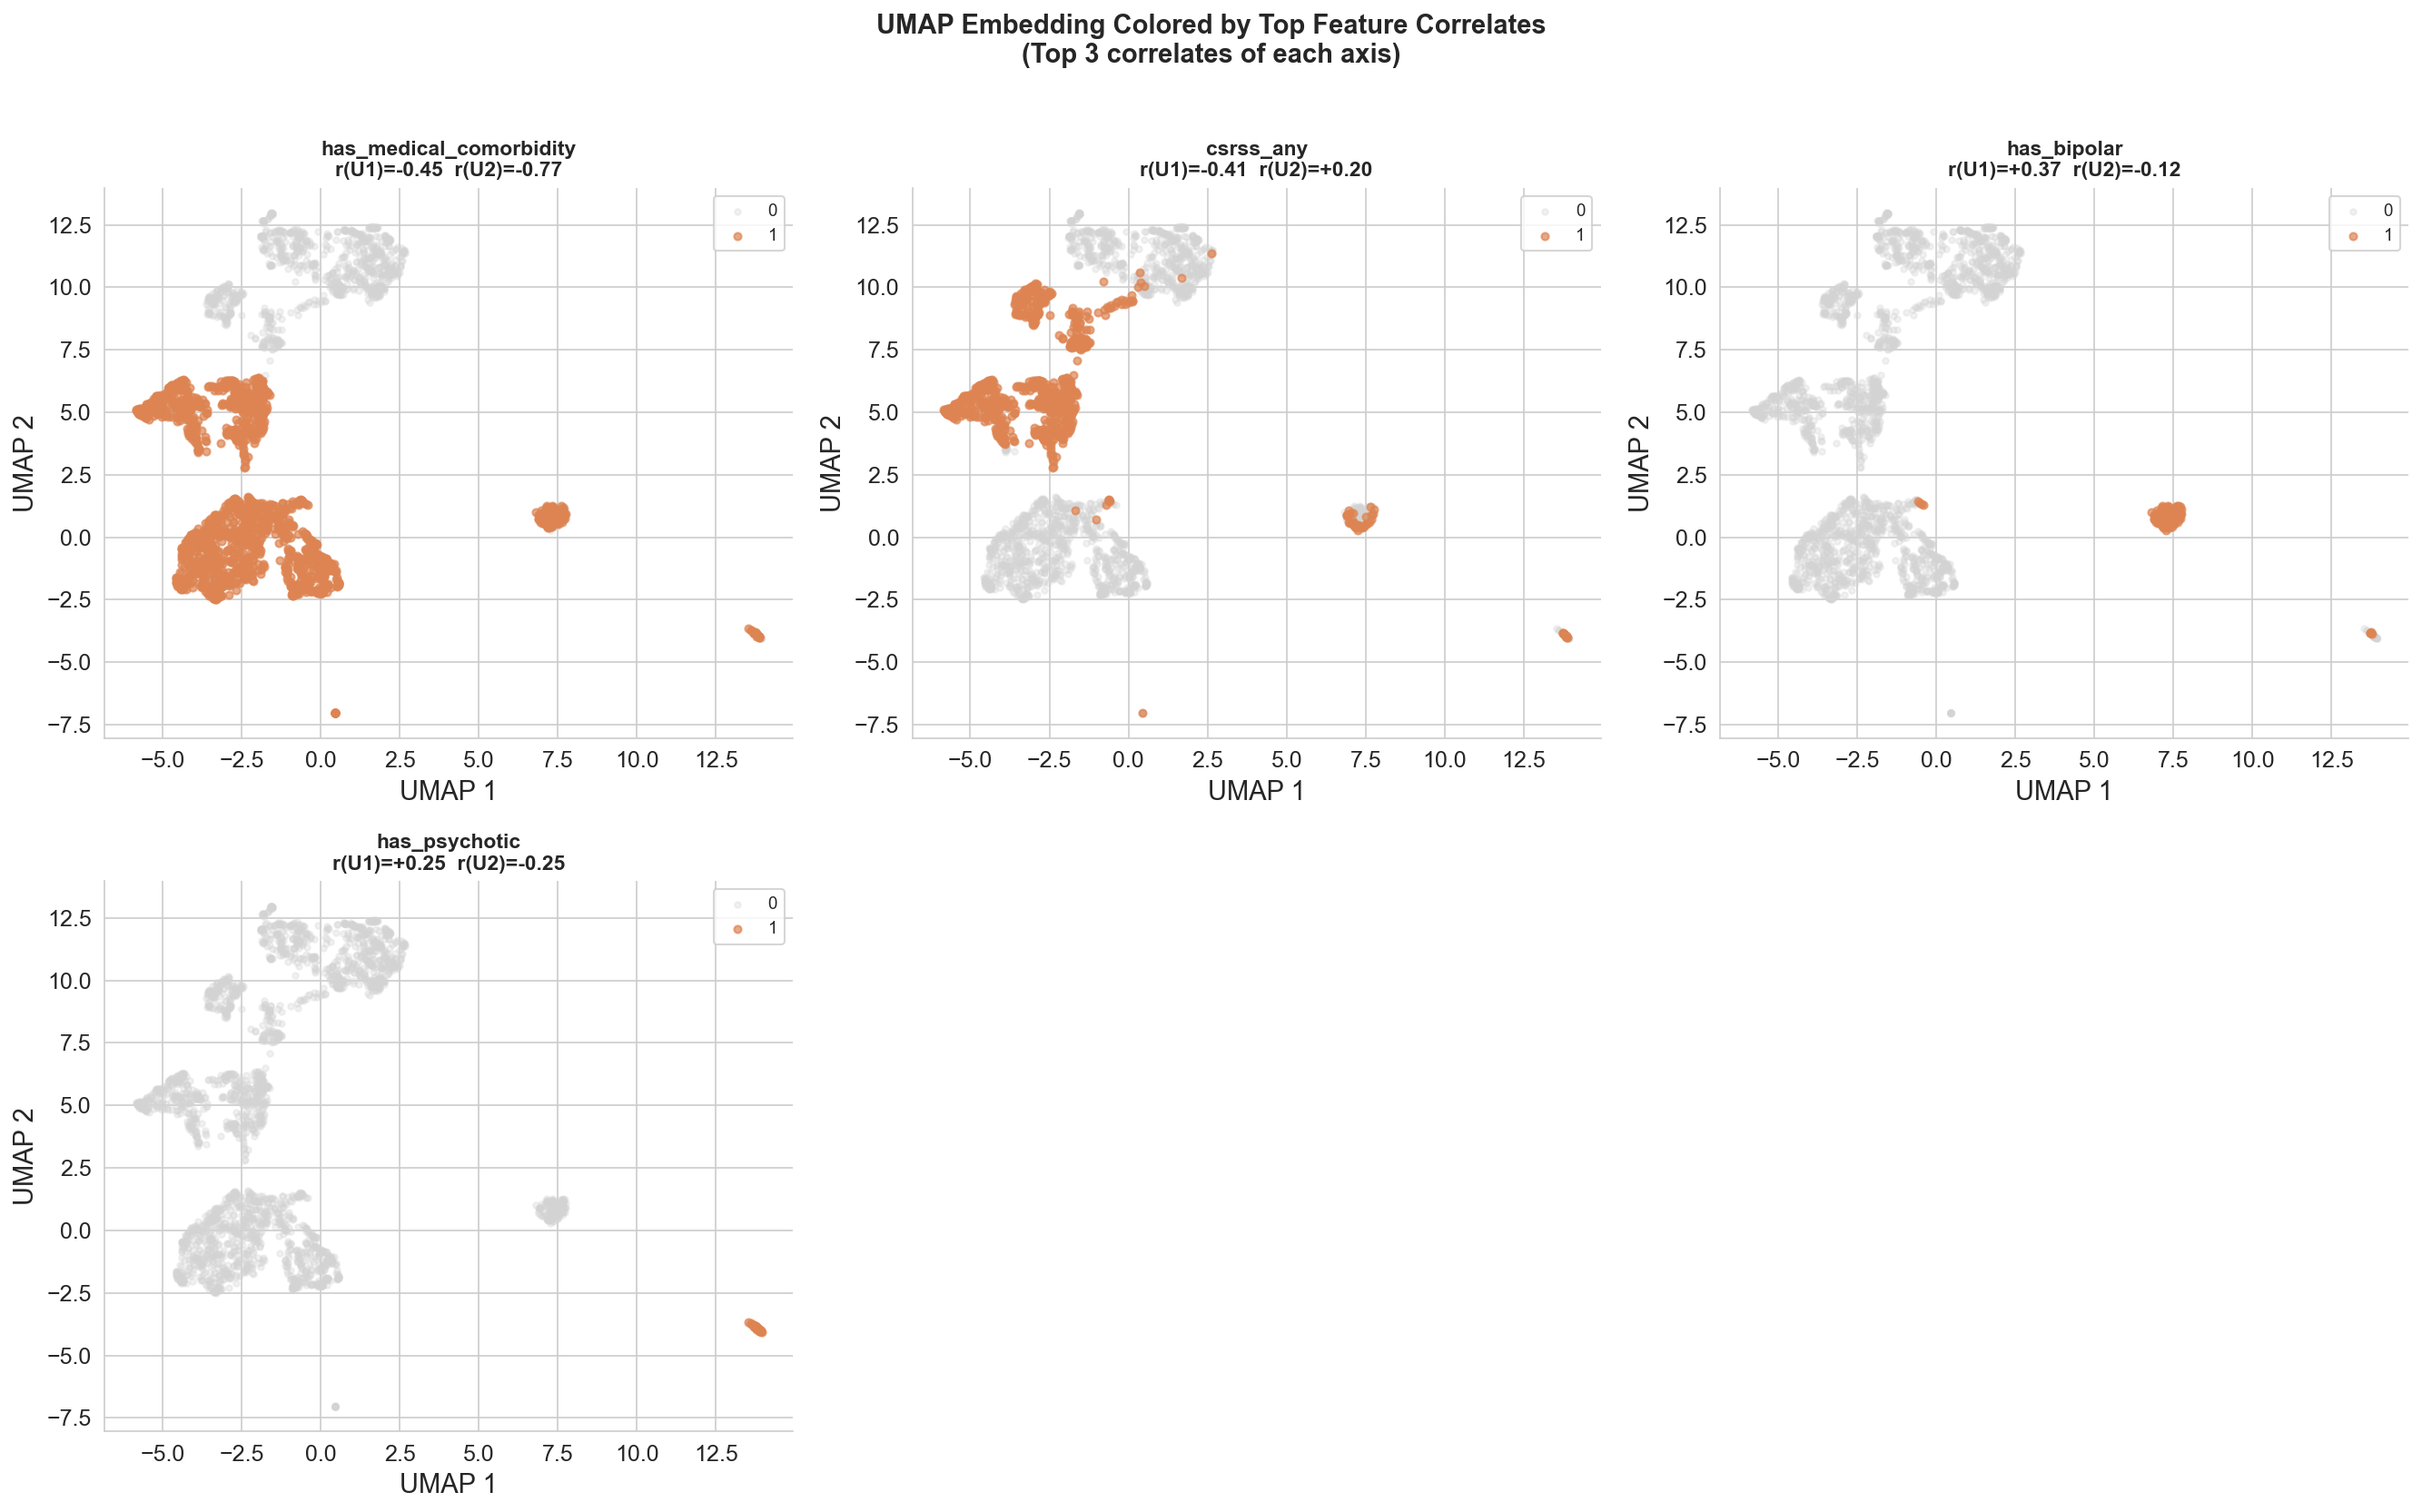

✓ Fig 12c saved


In [21]:
# ── Fig 12c: UMAP overlaid with top correlated features ───────────────────────
# Pick top 3 |r| for each axis (union, deduplicated)
top3_u1 = corr_df.reindex(corr_df['r_umap1'].abs().sort_values(ascending=False).index).head(3)['feature'].tolist()
top3_u2 = corr_df.reindex(corr_df['r_umap2'].abs().sort_values(ascending=False).index).head(3)['feature'].tolist()
overlay_feats = list(dict.fromkeys(top3_u1 + top3_u2))  # preserve order, deduplicate

n_panels = len(overlay_feats)
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
axes = axes.flatten()

for ax, feat in zip(axes[:n_panels], overlay_feats):
    feat_idx = feat_cols.index(feat)
    vals     = X_ml_raw[:, feat_idx]
    
    if len(np.unique(vals)) <= 2:  # Binary feature
        mask1 = vals == 1
        mask0 = vals == 0
        ax.scatter(embedding[mask0, 0], embedding[mask0, 1], c='lightgray', s=10, alpha=0.3, rasterized=True)
        ax.scatter(embedding[mask1, 0], embedding[mask1, 1], c=ORANGE,      s=15, alpha=0.7, rasterized=True)
        ax.legend(['0', '1'], loc='upper right', fontsize=9)
    else:  # Continuous feature
        sc = ax.scatter(embedding[:, 0], embedding[:, 1], c=vals,
                        cmap='viridis', alpha=0.6, s=12,
                        vmin=np.percentile(vals, 5), vmax=np.percentile(vals, 95),
                        rasterized=True)
        plt.colorbar(sc, ax=ax, label=feat, shrink=0.8)
    
    r1 = corr_df.loc[corr_df['feature'] == feat, 'r_umap1'].values[0]
    r2 = corr_df.loc[corr_df['feature'] == feat, 'r_umap2'].values[0]
    ax.set_title(f'{feat}\nr(U1)={r1:+.2f}  r(U2)={r2:+.2f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('UMAP 1')
    ax.set_ylabel('UMAP 2')
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

# Hide unused panels if < 6 features
for ax in axes[n_panels:]:
    ax.set_visible(False)

plt.suptitle('UMAP Embedding Colored by Top Feature Correlates\n'
             '(Top 3 correlates of each axis)',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/Fig12c_UMAP_feature_overlay.png')
plt.show()
print("✓ Fig 12c saved")

HDBSCAN found 8 clusters  |  noise points: 122


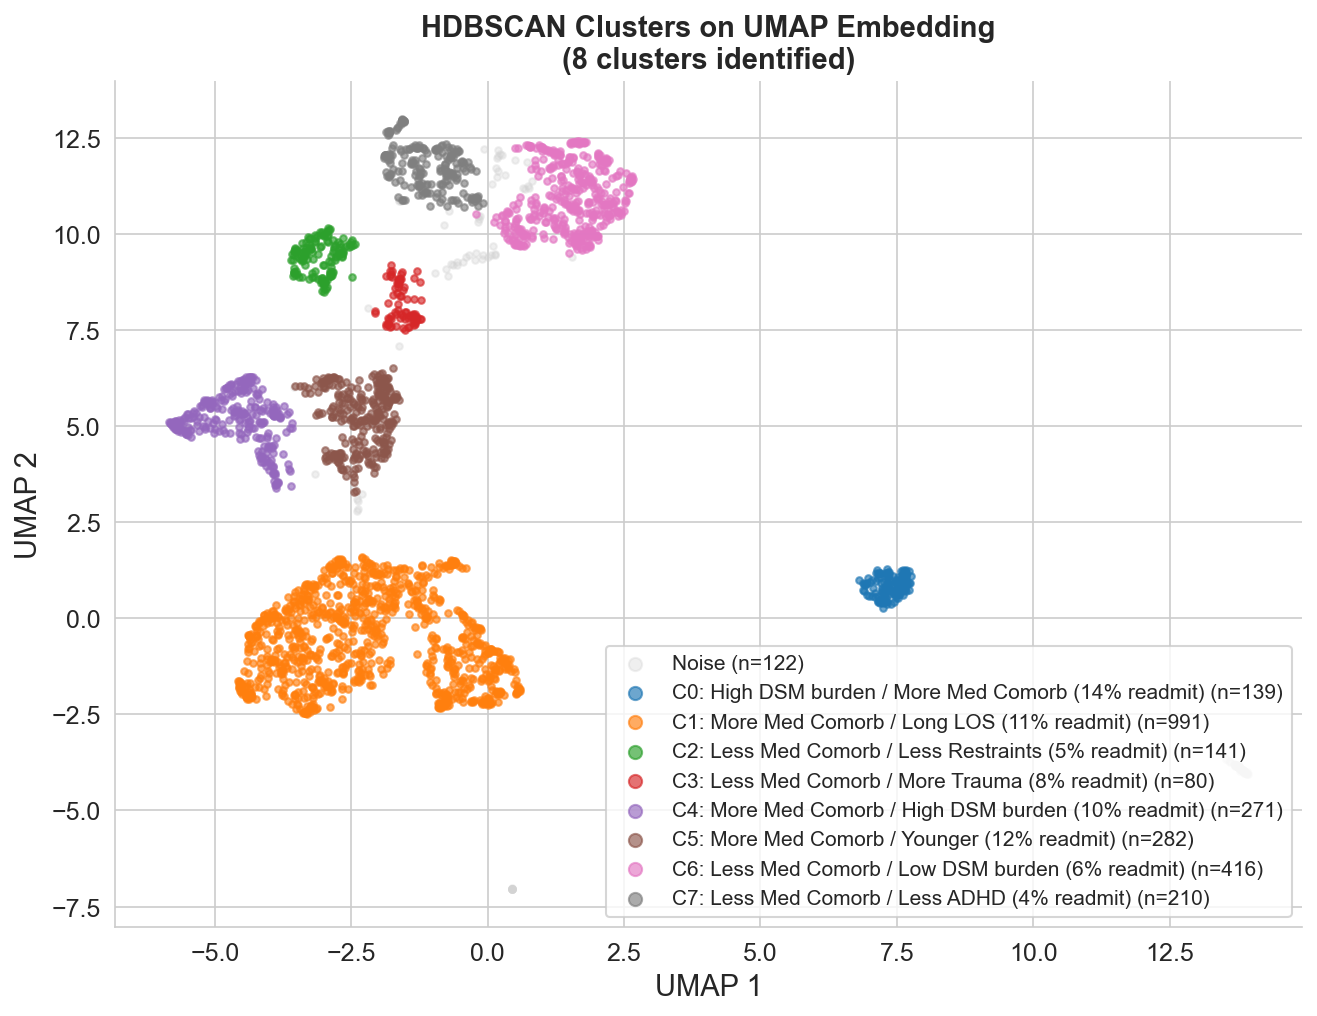


Cluster Profiles:
                                          Cluster name Readmission rate Age (mean) ACE score (mean) LOS days (mean) # DSM-5 categories Medical comorbidity (%) ADHD (%) Trauma/PTSD (%) ASD (%) Restraints (%)
Noise                                            Noise            11.5%        9.8              3.1            10.0                4.2                   42.6%    59.8%           45.9%   32.0%          17.2%
C0     High DSM burden / More Med Comorb (14% readmit)            14.4%       10.0              3.8            11.1                4.6                   79.1%    61.9%           47.5%   29.5%          25.9%
C1            More Med Comorb / Long LOS (11% readmit)            10.6%        9.6              4.0            11.1                3.3                   99.9%    55.7%           51.8%   20.5%          24.4%
C2      Less Med Comorb / Less Restraints (5% readmit)             5.0%       10.4              3.0             8.3                3.6                   

In [22]:

# ── Post-hoc: HDBSCAN Cluster Profiling on UMAP Embedding ────────────────────
import hdbscan

clusterer    = hdbscan.HDBSCAN(min_cluster_size=60, min_samples=10, prediction_data=True)
cluster_labels = clusterer.fit_predict(embedding)   # -1 = noise/unclustered

n_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
print(f"HDBSCAN found {n_clusters} clusters  |  noise points: {(cluster_labels == -1).sum()}")

# ── Derive human-readable cluster names ───────────────────────────────────────
base_df = model_df_unscaled if 'model_df_unscaled' in globals() else model_df
mdf_r = base_df.reset_index(drop=True)
mdf_r['cluster'] = cluster_labels

cont_vars = ['age', 'ace_score', 'los_days', 'n_dsm5_categories']
bin_vars  = ['has_medical_comorbidity', 'has_adhd', 'has_trauma', 'has_asd', 'had_restraints']
overall_mean = {v: mdf_r[v].mean() for v in cont_vars + bin_vars}
overall_sd   = {v: mdf_r[v].std(ddof=0) for v in cont_vars}
overall_bin_sd = {v: np.sqrt(overall_mean[v] * (1 - overall_mean[v])) for v in bin_vars}

_name_map = {
    'age': ('Older', 'Younger'),
    'ace_score': ('High ACE', 'Low ACE'),
    'los_days': ('Long LOS', 'Short LOS'),
    'n_dsm5_categories': ('High DSM burden', 'Low DSM burden'),
    'has_medical_comorbidity': ('More Med Comorb', 'Less Med Comorb'),
    'has_adhd': ('More ADHD', 'Less ADHD'),
    'has_trauma': ('More Trauma', 'Less Trauma'),
    'has_asd': ('More ASD', 'Less ASD'),
    'had_restraints': ('More Restraints', 'Less Restraints'),
}

cluster_names = {}
for cl in sorted(set(cluster_labels)):
    if cl == -1:
        cluster_names[cl] = 'Noise'
        continue
    sub = mdf_r[mdf_r['cluster'] == cl]
    z_scores = {}  # z-score deviations from cohort mean (renamed from 'scores' to avoid
                   # collision with the 'scores' risk-score array used in later cells)
    for v in cont_vars:
        sd = overall_sd.get(v, 0)
        z_scores[v] = (sub[v].mean() - overall_mean[v]) / sd if sd and not np.isnan(sd) else 0
    for v in bin_vars:
        sd = overall_bin_sd.get(v, 0)
        z_scores[v] = (sub[v].mean() - overall_mean[v]) / sd if sd and not np.isnan(sd) else 0
    top = sorted(z_scores.items(), key=lambda kv: abs(kv[1]), reverse=True)[:2]
    labels = []
    for v, z in top:
        hi, lo = _name_map[v]
        labels.append(hi if z >= 0 else lo)
    cluster_names[cl] = " / ".join(labels)

# Make phenotype labels unambiguous: two clusters can share the same top-2 features in a
# different order (e.g. 'High DSM burden / More Med Comorb' vs the reverse). Append each
# cluster's readmission rate so every label is distinct and clinically informative.
for _cl in sorted(set(cluster_labels)):
    if _cl == -1: continue
    _rr = mdf_r[mdf_r['cluster']==_cl]['readmitted'].mean()*100
    cluster_names[_cl] = f"{cluster_names[_cl]} ({_rr:.0f}% readmit)"

# ── UMAP colored by cluster ───────────────────────────────────────────────────
palette_c = plt.cm.tab10.colors
fig, ax = plt.subplots(figsize=(9, 7))
for cl in sorted(set(cluster_labels)):
    mask = cluster_labels == cl
    name = cluster_names.get(cl, f'Cluster {cl}')
    lbl  = f'Noise (n={mask.sum()})' if cl == -1 else f'C{cl}: {name} (n={mask.sum()})'
    col  = 'lightgray' if cl == -1 else palette_c[cl % 10]
    ax.scatter(embedding[mask, 0], embedding[mask, 1],
               c=[col], alpha=0.35 if cl == -1 else 0.65, s=10, label=lbl, rasterized=True)
ax.legend(fontsize=10, markerscale=2)
ax.set_xlabel('UMAP 1')
ax.set_ylabel('UMAP 2')
ax.set_title(f'HDBSCAN Clusters on UMAP Embedding\n({n_clusters} clusters identified)',
             fontsize=14, fontweight='bold')
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig_HDBSCAN_clusters.png')
plt.show()

# ── Cluster profile table ─────────────────────────────────────────────────────

profile_vars = {
    'Readmission rate':        'readmitted',
    'Age (mean)':              'age',
    'ACE score (mean)':        'ace_score',
    'LOS days (mean)':         'los_days',
    '# DSM-5 categories':      'n_dsm5_categories',
    'Medical comorbidity (%)': 'has_medical_comorbidity',
    'ADHD (%)':                'has_adhd',
    'Trauma/PTSD (%)':         'has_trauma',
    'ASD (%)':                 'has_asd',
    'Restraints (%)':          'had_restraints',
}

rows = {}
for cl in sorted(set(cluster_labels)):
    sub = mdf_r[mdf_r['cluster'] == cl]
    row_key = f'C{cl}' if cl != -1 else 'Noise'
    rows[row_key] = {
        'Cluster name': cluster_names.get(cl, row_key)
    }
    for k, v in profile_vars.items():
        if v in ('readmitted','has_medical_comorbidity','has_adhd','has_trauma','has_asd','had_restraints'):
            rows[row_key][k] = f'{sub[v].mean()*100:.1f}%'
        else:
            rows[row_key][k] = f'{sub[v].mean():.1f}'

profile_df = pd.DataFrame(rows).T
print("\nCluster Profiles:")
print(profile_df.to_string())
profile_df.to_csv('figures/HDBSCAN_cluster_profiles.csv')
print("\n✓ Cluster profiles saved to figures/HDBSCAN_cluster_profiles.csv")


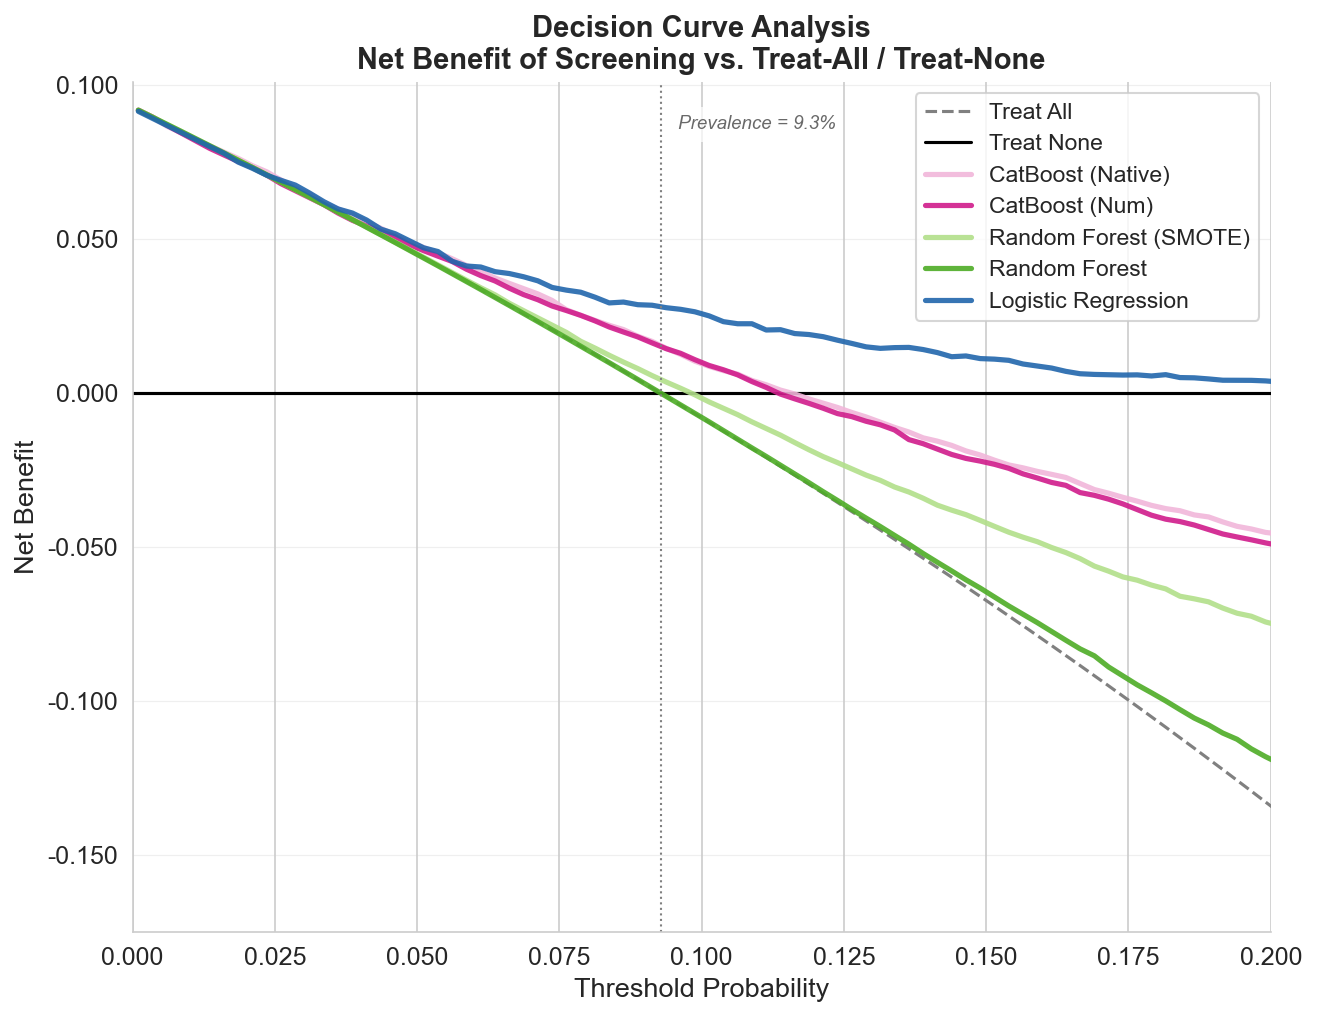

✓ DCA saved

Net benefit at clinical thresholds  [model  (model - treat-all)]:
  Model                              t= 0.05           t= 0.10           t= 0.15           t= 0.20
  Logistic Regression       0.0476 (+0.0026)  0.0259 (+0.0339)  0.0116 (+0.0790)  0.0041 (+0.1382)
  Random Forest             0.0450 (+0.0000) -0.0079 (+0.0001) -0.0645 (+0.0028) -0.1190 (+0.0151)
  CatBoost (Num)            0.0473 (+0.0023)  0.0097 (+0.0178) -0.0226 (+0.0447) -0.0491 (+0.0849)
(A positive model-minus-treat-all value means the model adds benefit over treating everyone.)


In [23]:
# ── Post-hoc: Decision Curve Analysis ────────────────────────────────────────
def net_benefit(y_true, probs, threshold):
    if threshold <= 0 or threshold >= 1:
        return np.nan
    preds = (probs >= threshold).astype(int)
    tp = ((preds == 1) & (y_true == 1)).sum()
    fp = ((preds == 1) & (y_true == 0)).sum()
    n  = len(y_true)
    return tp / n - fp / n * (threshold / (1 - threshold))

thresholds = np.linspace(0.001, 0.50, 200)

model_nbs = {
    'CatBoost (Native)':   [net_benefit(y_ml, cat_native_probs, t) for t in thresholds],
    'CatBoost (Num)':      [net_benefit(y_ml, cat_probs, t) for t in thresholds],
    'Random Forest (SMOTE)': [net_benefit(y_ml, rf_smote_probs,  t) for t in thresholds],
    'Random Forest':       [net_benefit(y_ml, rf_probs,  t) for t in thresholds],
    'Logistic Regression': [net_benefit(y_ml, lr_probs,  t) for t in thresholds],
}
treat_all_nb = [net_benefit(y_ml, np.ones(len(y_ml)), t) for t in thresholds]

# y-axis range from data
max_nb = max(max(v for v in nb if not np.isnan(v)) for nb in model_nbs.values())

fig, ax = plt.subplots(figsize=(9, 7))

# Baselines
ax.plot(thresholds, treat_all_nb, color='gray', linestyle='--', linewidth=1.5, label='Treat All')
ax.axhline(0, color='black', linewidth=1.5, label='Treat None')

# Models
colors = ['#f1b6da', '#d01c8b', '#b2df8a', '#4dac26', '#2166ac']
for (name, nb_vals), color in zip(model_nbs.items(), colors):
    ax.plot(thresholds, nb_vals, color=color, linewidth=2.5, alpha=0.9, label=name)

# Annotate prevalence
base_rate = y_ml.mean()
ax.axvline(base_rate, color='gray', linestyle=':', linewidth=1)
ax.text(base_rate + 0.003, max_nb * 0.95, f'Prevalence = {base_rate:.1%}', 
        fontsize=9, color='dimgray', style='italic',
        va='center', bbox=dict(facecolor='white', alpha=0.7, edgecolor='none'))

ax.set_xlabel('Threshold Probability', fontsize=13)
ax.set_ylabel('Net Benefit', fontsize=13)
ax.set_title('Decision Curve Analysis\n'
             'Net Benefit of Screening vs. Treat-All / Treat-None',
             fontsize=14, fontweight='bold')
ax.legend(fontsize=11)
ax.set_xlim(0.00, 0.20)
ax.set_ylim(-0.175, max_nb * 1.1)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f'{v:.3f}'))
ax.grid(axis='y', alpha=0.3, linewidth=0.6)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig_DCA.png')
plt.show()
print("✓ DCA saved")
# NB at low thresholds collapses to the treat-all baseline (~prevalence); compare models at
# clinically relevant thresholds and as net benefit ABOVE treat-all.
print("\nNet benefit at clinical thresholds  [model  (model - treat-all)]:")
_clin = [0.05, 0.10, 0.15, 0.20]
print("  " + "Model".ljust(24) + "".join(f"t={t:>5.2f}".rjust(18) for t in _clin))
for _nm, _pr in [("Logistic Regression", lr_probs), ("Random Forest", rf_probs), ("CatBoost (Num)", cat_probs)]:
    _row = ""
    for _t in _clin:
        _m = net_benefit(y_ml, _pr, _t); _a = net_benefit(y_ml, np.ones(len(y_ml)), _t)
        _row += f"{_m:.4f} ({_m-_a:+.4f})".rjust(18)
    print("  " + _nm.ljust(24) + _row)
print("(A positive model-minus-treat-all value means the model adds benefit over treating everyone.)")

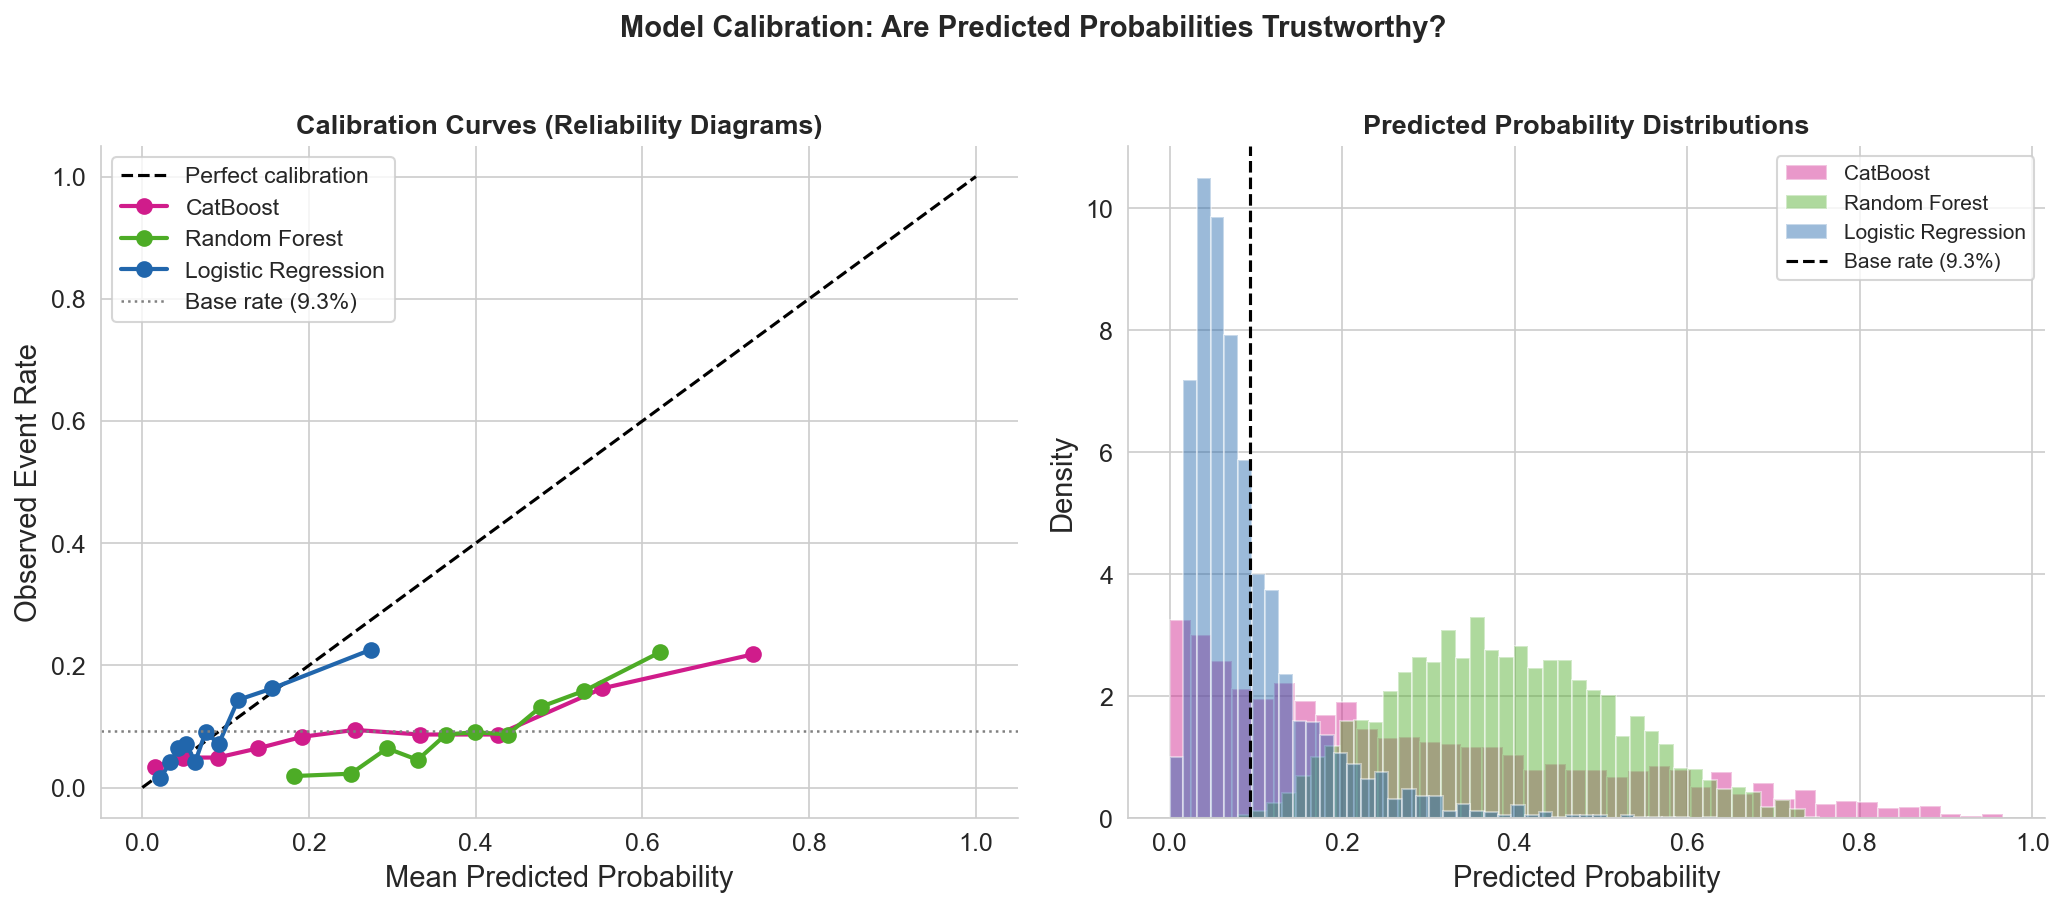

✓ Calibration curves saved


In [24]:
# ── Post-hoc: Model Calibration Curves ───────────────────────────────────────
from sklearn.calibration import calibration_curve

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
colors = {'CatBoost': '#d01c8b', 'Random Forest': '#4dac26', 'Logistic Regression': '#2166ac'}

axes[0].plot([0, 1], [0, 1], 'k--', linewidth=1.5, label='Perfect calibration')
for name, probs in [('CatBoost', cat_probs), ('Random Forest', rf_probs),
                    ('Logistic Regression', lr_probs)]:
    frac_pos, mean_pred = calibration_curve(y_ml, probs, n_bins=10, strategy='quantile')
    axes[0].plot(mean_pred, frac_pos, 'o-', linewidth=2, markersize=7,
                 label=name, color=colors[name])
axes[0].axhline(y_ml.mean(), color='gray', linestyle=':', linewidth=1.2,
                label=f'Base rate ({y_ml.mean():.1%})')
axes[0].set_xlabel('Mean Predicted Probability')
axes[0].set_ylabel('Observed Event Rate')
axes[0].set_title('Calibration Curves (Reliability Diagrams)', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=11)
axes[0].spines['top'].set_visible(False)
axes[0].spines['right'].set_visible(False)

for name, probs in [('CatBoost', cat_probs), ('Random Forest', rf_probs),
                    ('Logistic Regression', lr_probs)]:
    axes[1].hist(probs, bins=40, alpha=0.45, color=colors[name], label=name, density=True)
axes[1].axvline(y_ml.mean(), color='black', linestyle='--', linewidth=1.5,
                label=f'Base rate ({y_ml.mean():.1%})')
axes[1].set_xlabel('Predicted Probability')
axes[1].set_ylabel('Density')
axes[1].set_title('Predicted Probability Distributions', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].spines['top'].set_visible(False)
axes[1].spines['right'].set_visible(False)

plt.suptitle('Model Calibration: Are Predicted Probabilities Trustworthy?',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('figures/Fig_Calibration.png')
plt.show()
print("✓ Calibration curves saved")

In [25]:

# ── Post-hoc: DeLong AUC Test (Bootstrap, n=2000) ────────────────────────────
np.random.seed(42)
N = len(y_ml)

def bootstrap_auc_comparison(probs1, probs2, n_boot=2000):
    diffs = []
    for _ in range(n_boot):
        idx = np.random.choice(N, N, replace=True)
        if y_ml[idx].sum() < 2 or (y_ml[idx] == 0).sum() < 2:
            continue
        try:
            d = roc_auc_score(y_ml[idx], probs1[idx]) - roc_auc_score(y_ml[idx], probs2[idx])
            diffs.append(d)
        except Exception:
            continue
    diffs   = np.array(diffs)
    obs_diff = roc_auc_score(y_ml, probs1) - roc_auc_score(y_ml, probs2)
    p        = 2 * min(np.mean(diffs >= obs_diff), np.mean(diffs <= obs_diff))
    ci       = np.percentile(diffs, [2.5, 97.5])
    return obs_diff, p, ci

pairs = [
    ('CatBoost',            'Random Forest',       cat_probs, rf_probs),
    ('CatBoost',            'Logistic Regression', cat_probs, lr_probs),
    ('Random Forest',       'Logistic Regression', rf_probs,  lr_probs),
]

print("DeLong AUC Comparison (Bootstrap, n=2,000 resamples)")
print(f"\n{'Comparison':<42}  {'ΔAUC':>7}  {'95% CI':>22}  {'p-value':>10}  Sig")
print("-" * 95)
for name1, name2, p1, p2 in pairs:
    diff, p, ci = bootstrap_auc_comparison(p1, p2)
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else 'ns'))
    print(f"  {name1} vs {name2:<28}  {diff:>+7.4f}  [{ci[0]:+.4f}, {ci[1]:+.4f}]   {p:>8.4f}  {sig}")

print(f"\n  Model AUCs: CatBoost={roc_auc_score(y_ml,cat_probs):.4f}  "
      f"RF={roc_auc_score(y_ml,rf_probs):.4f}  "
      f"LR={roc_auc_score(y_ml,lr_probs):.4f}")


DeLong AUC Comparison (Bootstrap, n=2,000 resamples)

Comparison                                     ΔAUC                  95% CI     p-value  Sig
-----------------------------------------------------------------------------------------------
  CatBoost vs Random Forest                 -0.0322  [-0.0582, -0.0086]     0.9960  ns
  CatBoost vs Logistic Regression           -0.0282  [-0.0640, +0.0077]     0.9470  ns
  Random Forest vs Logistic Regression           +0.0040  [-0.0211, +0.0308]     0.9550  ns

  Model AUCs: CatBoost=0.6646  RF=0.6968  LR=0.6928


Subgroup AUC Performance:
                        N Readmission rate AUC (CatBoost) AUC (Random Forest) AUC (Logistic Regression)
Subgroup                                                                                               
Age ≤9               1089            10.8%          0.699               0.720                     0.699
Age ≥10              1563             8.2%          0.625               0.665                     0.685
Male                 1369             9.8%          0.675               0.715                     0.710
Female               1283             8.7%          0.652               0.674                     0.673
Public Insurance     1589             9.8%          0.669               0.696                     0.713
Private Insurance    1063             8.6%          0.657               0.697                     0.660
High ACE (expanded)  1509             9.6%          0.668               0.685                     0.690
Not high ACE         1143             

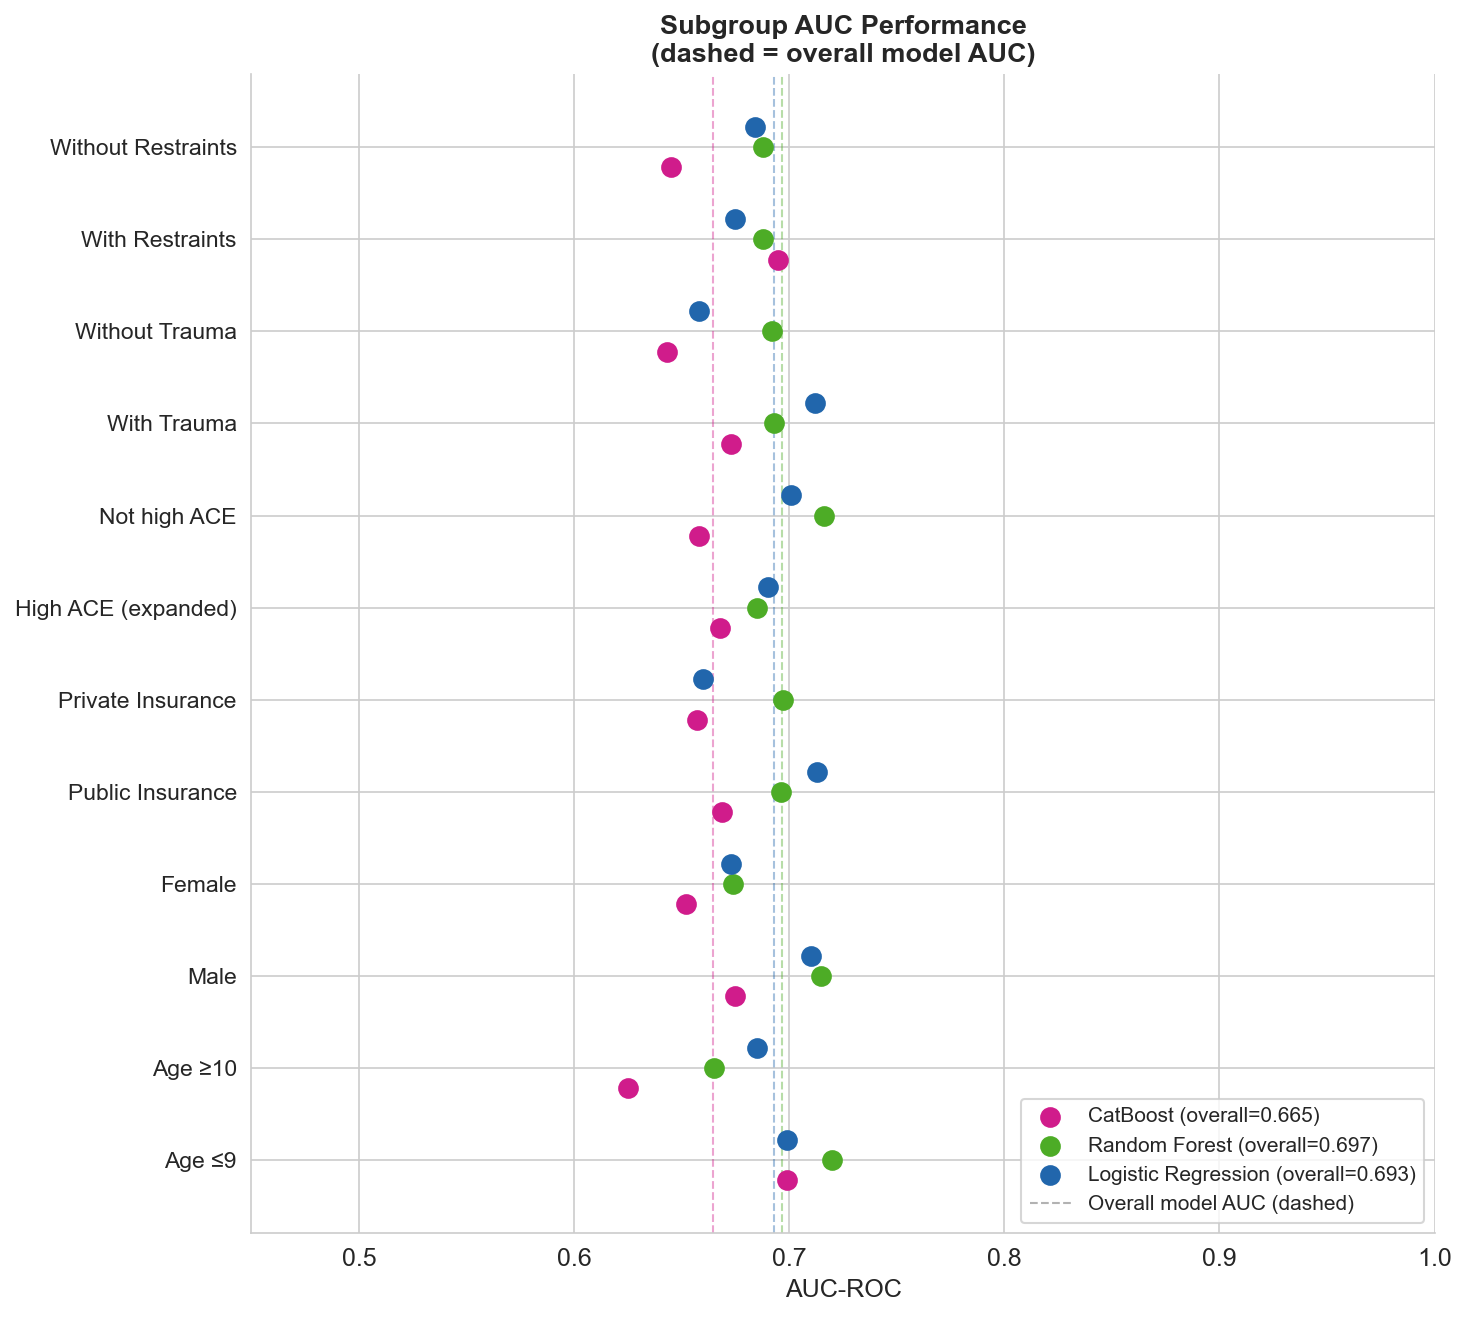

✓ Subgroup analysis saved


In [26]:

# ── Post-hoc: Subgroup Performance (Equity Analysis) ─────────────────────────
mdf_r = model_df_unscaled.reset_index(drop=True)

_hiace = ((mdf_r['ace_score']>=4) | (mdf_r['ace_score'].between(1,3) & (mdf_r['has_ace_condition']==1))).values
subgroup_defs = {
    'Age ≤9':              mdf_r['age'].values <= 9,
    'Age ≥10':             mdf_r['age'].values >= 10,
    'Male':                mdf_r['gender_male'].values == 1,
    'Female':              mdf_r['gender_male'].values == 0,
    'Public Insurance':    mdf_r['insurance_public'].values == 1,
    'Private Insurance':   mdf_r['insurance_public'].values == 0,
    'High ACE (expanded)':              _hiace,
    'Not high ACE':              ~_hiace,
    'With Trauma':         mdf_r['has_trauma'].values == 1,
    'Without Trauma':      mdf_r['has_trauma'].values == 0,
    'With Restraints':     mdf_r['had_restraints'].values == 1,
    'Without Restraints':  mdf_r['had_restraints'].values == 0,
}

model_probes = [('CatBoost', cat_probs, '#d01c8b'),
                ('Random Forest', rf_probs, '#4dac26'),
                ('Logistic Regression', lr_probs, '#2166ac')]

results = []
for sg_name, mask in subgroup_defs.items():
    row = {'Subgroup': sg_name, 'N': mask.sum(), 'Readmission rate': f"{y_ml[mask].mean():.1%}"}
    for model_name, probs, _ in model_probes:
        try:
            if y_ml[mask].sum() >= 5 and (y_ml[mask] == 0).sum() >= 5:
                auc = roc_auc_score(y_ml[mask], probs[mask])
                row[f'AUC ({model_name})'] = f'{auc:.3f}'
            else:
                row[f'AUC ({model_name})'] = 'n/a'
        except Exception:
            row[f'AUC ({model_name})'] = 'error'
    results.append(row)

sg_df = pd.DataFrame(results).set_index('Subgroup')
print("Subgroup AUC Performance:")
print(sg_df.to_string())
sg_df.to_csv('figures/Subgroup_AUC.csv')

# Visualize as dot plot
fig, ax = plt.subplots(figsize=(10, 9))
sg_names = sg_df.index.tolist()
y_pos    = np.arange(len(sg_names))

overall_aucs = {name: roc_auc_score(y_ml, probs) for name, probs, _ in model_probes}

for i, (model_name, probs, color) in enumerate(model_probes):
    col = f'AUC ({model_name})'
    aucs_plot = [float(v) if v not in ('n/a', 'error') else np.nan for v in sg_df[col]]
    offset = (i - 1) * 0.22
    ax.scatter(aucs_plot, y_pos + offset, color=color, s=80, zorder=3,
               label=f'{model_name} (overall={overall_aucs[model_name]:.3f})')
    ax.axvline(overall_aucs[model_name], color=color, linewidth=1, linestyle='--', alpha=0.4)

ax.set_yticks(y_pos)
ax.set_yticklabels(sg_names, fontsize=11)
ax.set_xlabel('AUC-ROC', fontsize=12)
ax.set_title('Subgroup AUC Performance\n(dashed = overall model AUC)', fontsize=13, fontweight='bold')
from matplotlib.lines import Line2D
handles, labels = ax.get_legend_handles_labels()
handles.append(Line2D([0], [0], color='gray', linestyle='--', alpha=0.6, linewidth=1))
labels.append('Overall model AUC (dashed)')
ax.legend(handles, labels, fontsize=10, loc='lower right')
ax.set_xlim(0.45, 1.0)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('figures/Fig_Subgroup_AUC.png')
plt.show()
print("✓ Subgroup analysis saved")


Top 10 Feature Interactions (CatBoost SHAP):
                  feat1                 feat2  interaction_strength
              ace_score      complexity_x_age              0.080324
            gender_male      complexity_x_age              0.056766
has_medical_comorbidity              has_nssi              0.055439
               has_nssi has_suicidal_ideation              0.055280
      n_dsm5_categories              has_adhd              0.053373
has_medical_comorbidity           has_conduct              0.050759
                    age               has_asd              0.050589
               los_days has_suicidal_ideation              0.046381
            gender_male           has_anxiety              0.041552
         has_depression           ace_x_csrss              0.040495


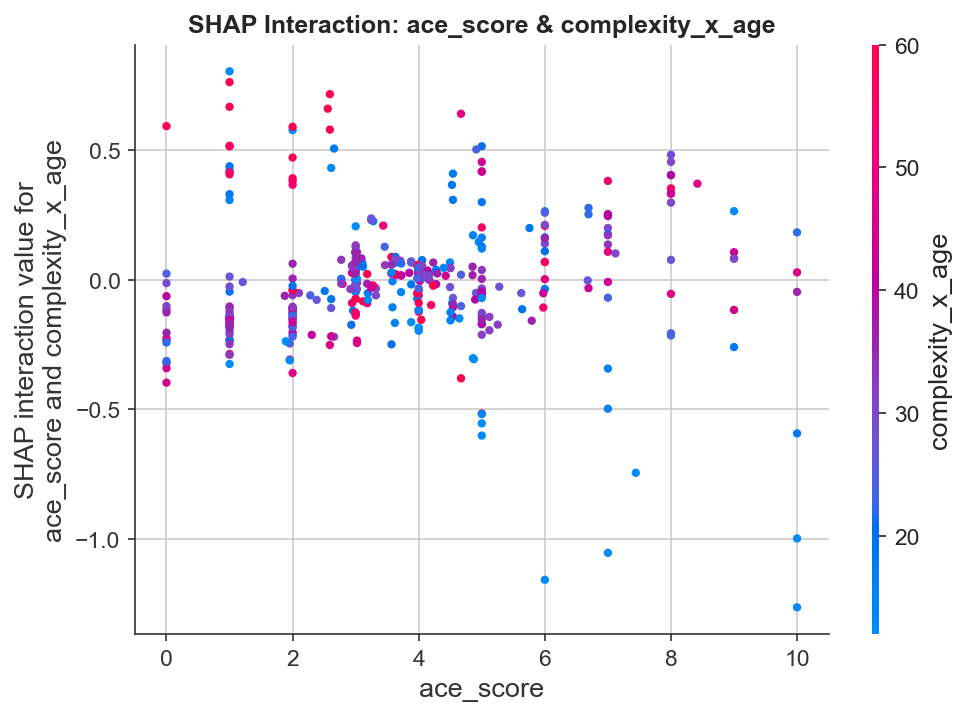

In [27]:
# ── Post-hoc: SHAP Interaction Values (CatBoost, n=400 sample) ────────────────
# SHAP interaction values are computationally expensive. O(N * F^2)
# We sample 400 random patients to approximate the interactions.

sample_idx = np.random.choice(X_ml_cat.shape[0], size=min(400, X_ml_cat.shape[0]), replace=False)
X_sample = X_ml_cat[sample_idx]

# CatBoost's native interaction values currently don't always behave perfectly with native categorical features in SHAP.
# To safely generate the interaction matrix we can use the numerical tree.
explainer_int = shap.TreeExplainer(cat_num)
shap_interaction_values = explainer_int.shap_interaction_values(X_ml[sample_idx])

# Calculate mean absolute interaction across the sample
# diagonal = main effects; off-diagonal = interaction effects
mean_abs_interactions = np.abs(shap_interaction_values).mean(axis=0)

# Zero out the diagonal to focus only on interactions
np.fill_diagonal(mean_abs_interactions, 0)

# Unravel the matrix into a ranked list
interaction_pairs = []
for i in range(len(ml_cols)):
    for j in range(i + 1, len(ml_cols)):
        interaction_pairs.append({
            'feat1': ml_cols[i],
            'feat2': ml_cols[j],
            'interaction_strength': mean_abs_interactions[i, j]
        })

int_df = pd.DataFrame(interaction_pairs).sort_values('interaction_strength', ascending=False)
print("Top 10 Feature Interactions (CatBoost SHAP):")
print(int_df.head(10).to_string(index=False))

# Plot top interaction
top_feat1, top_feat2 = int_df.iloc[0]['feat1'], int_df.iloc[0]['feat2']
f1_idx = ml_cols.index(top_feat1)
f2_idx = ml_cols.index(top_feat2)

fig, ax = plt.subplots(figsize=(7, 5))
shap.dependence_plot(
    (top_feat1, top_feat2),
    shap_interaction_values,
    X_ml_raw[sample_idx],          # unscaled values → interpretable x-axis (no negative ace_score)
    feature_names=ml_cols,
    ax=ax,
    show=False
)
ax.set_title(f'SHAP Interaction: {top_feat1} & {top_feat2}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Fig_SHAP_interaction_top1.png')
plt.show()

Top 10 Feature Interactions (Random Forest SHAP):
                  feat1                   feat2  interaction_strength
      n_dsm5_categories   has_suicidal_ideation              0.004031
      n_dsm5_categories                has_adhd              0.002947
               has_nssi   has_suicidal_ideation              0.002662
               los_days       n_dsm5_categories              0.002354
      n_dsm5_categories        complexity_x_age              0.002344
has_medical_comorbidity   has_suicidal_ideation              0.002230
                    age        complexity_x_age              0.002112
               los_days has_medical_comorbidity              0.002101
has_medical_comorbidity                has_adhd              0.001870
has_medical_comorbidity             has_conduct              0.001802


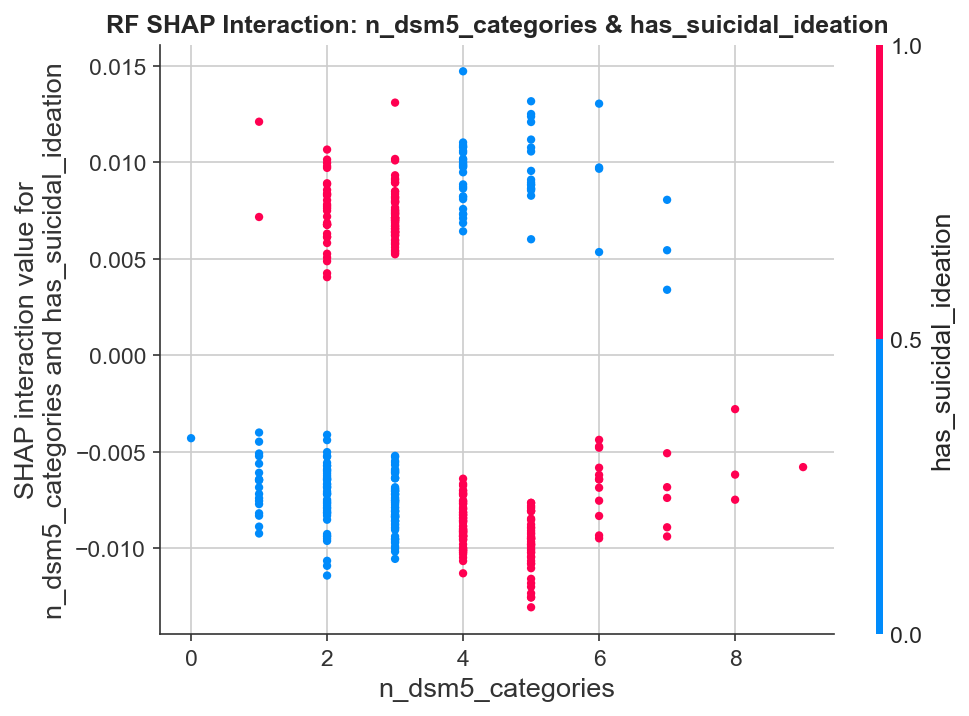

In [28]:
# ── Post-hoc: SHAP Interaction Values — Random Forest (n=400 sample) ────────────
# Random Forest provides a good robustness check for the CatBoost interactions

explainer_rf = shap.TreeExplainer(rf_full)
# rf_full was trained on the numeric matrix X_ml — use that, NOT X_ml_cat (native categoricals)
X_int_rf = X_ml[sample_idx]
# shap_interaction_values may return a list (per class), a 4D array (n, f, f, n_classes),
# or a 3D array (n, f, f) depending on the SHAP version — handle all three robustly.
_raw_int_rf = explainer_rf.shap_interaction_values(X_int_rf)
if isinstance(_raw_int_rf, list):
    shap_interaction_rf = _raw_int_rf[1] if len(_raw_int_rf) > 1 else _raw_int_rf[0]
elif np.ndim(_raw_int_rf) == 4:
    shap_interaction_rf = _raw_int_rf[:, :, :, 1]
else:
    shap_interaction_rf = _raw_int_rf

mean_abs_interactions_rf = np.abs(shap_interaction_rf).mean(axis=0)
np.fill_diagonal(mean_abs_interactions_rf, 0)

interaction_pairs_rf = []
for i in range(len(ml_cols)):
    for j in range(i + 1, len(ml_cols)):
        interaction_pairs_rf.append({
            'feat1': ml_cols[i],
            'feat2': ml_cols[j],
            'interaction_strength': mean_abs_interactions_rf[i, j]
        })

int_df_rf = pd.DataFrame(interaction_pairs_rf).sort_values('interaction_strength', ascending=False)
print("Top 10 Feature Interactions (Random Forest SHAP):")
print(int_df_rf.head(10).to_string(index=False))

# Plot top interaction for RF
top_feat1_rf, top_feat2_rf = int_df_rf.iloc[0]['feat1'], int_df_rf.iloc[0]['feat2']

fig, ax = plt.subplots(figsize=(7, 5))
shap.dependence_plot(
    (top_feat1_rf, top_feat2_rf),
    shap_interaction_rf,
    X_ml_raw[sample_idx],          # unscaled values → interpretable x-axis
    feature_names=ml_cols,
    ax=ax,
    show=False
)
ax.set_title(f'RF SHAP Interaction: {top_feat1_rf} & {top_feat2_rf}', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Fig_SHAP_interaction_RF_top1.png')
plt.show()

### ── Refinement: Outlier Removal & Interaction Decomposition ──
Based on the SHAP and HDBSCAN results, we observed some noise from extreme outliers and strong interaction effects. We will now:
1. Filter out physically impossible values (e.g., negative LOS).
2. Visualize the 'Complexity × Age' interaction to see where risk peaks.

In [ ]:
# ── Post-hoc: Outlier Filtering ──────────────────────────────────────────────
# Remove records with impossible Length of Stay (should already be filtered, but be safe)
mask_valid_los = model_df_unscaled['los_days'] >= 0
removed = (~mask_valid_los).sum()
model_df_unscaled = model_df_unscaled[mask_valid_los].reset_index(drop=True)
print(f"Removed {removed} records with negative Length of Stay.")

# ── Post-hoc: Complexity × Age Interaction Visualization ───────────────────────
# The strongest SHAP interaction was ace_score × complexity_x_age.
# Visualize how risk varies across this interaction surface.

from matplotlib.colors import LinearSegmentedColormap

fig, ax = plt.subplots(figsize=(8, 6))

# Create interaction surface data
x_age = model_df_unscaled['age'].values
y_complexity = model_df_unscaled['n_dsm5_categories'].values
z_readmit = model_df_unscaled['readmitted'].values

# Binned heatmap for interpretability
age_bins = pd.cut(x_age, bins=5)
comp_bins = pd.cut(y_complexity, bins=5)
heatmap_data = pd.crosstab(comp_bins, age_bins, z_readmit, aggfunc='mean')
cell_counts  = pd.crosstab(comp_bins, age_bins)  # parallel count table
sparse_mask  = cell_counts < 5                   # blank cells with <5 patients

# Annotation: show rate + cell count; leave sparse cells blank
annot_arr = heatmap_data.copy().astype(object)
for r in heatmap_data.index:
    for c in heatmap_data.columns:
        n = cell_counts.loc[r, c]
        v = heatmap_data.loc[r, c]
        annot_arr.loc[r, c] = '' if n < 5 else f'{v:.2f}\n(n={n})'

# Custom colormap: blue → white → orange
cmap = LinearSegmentedColormap.from_list('custom', [BLUE, '#f7f7f7', ORANGE], N=256)

sns.heatmap(heatmap_data, cmap=cmap, annot=annot_arr, fmt='',
            mask=sparse_mask, linewidths=0.5,
            cbar_kws={'label': 'Readmission Rate'}, ax=ax)
ax.invert_yaxis()  # lowest complexity at bottom, highest at top
ax.set_xlabel('Age (binned)')
ax.set_ylabel('Diagnostic Complexity (binned DSM-5 categories)')
ax.set_title('Readmission Risk: Age × Complexity Interaction\n'
             '(SHAP-identified strongest interaction; cells with n<5 masked)',
             fontsize=12, fontweight='bold')
plt.tight_layout()
plt.savefig('figures/Fig_interaction_age_x_complexity.png')
plt.show()
print("✓ Interaction decomposition saved")


### ── Final Refinement: Imbalance Handling & Risk Score Calculator ──
To improve clinical utility, we now:
1. Re-train models using **SMOTE** to handle the 9% class imbalance.
2. Construct a **Risk Score** formula based on the standardized coefficients of the Logistic Regression model.

In [30]:
# ── WARNING: IN-SAMPLE RISK SCORING ─────────────────────────────────────────────
# The rf_res model below is trained on SMOTE-resampled X_train and then scored on
# the entire X_ml (training + test). The resulting 'scores' array is used by the
# threshold analysis and staffing simulation cells further below.
#
# These are IN-SAMPLE predictions for the training portion and should be treated
# as illustrative only — sensitivity/specificity at any quoted threshold will be
# optimistically biased relative to a held-out cohort. The honest discriminative
# performance is the 10-fold out-of-fold AUC reported in Cell 15 above.
# ─────────────────────────────────────────────────────────────────────────────────
# ── Final Refinement: Imbalance Handling & Risk Score Calculator ─────────────
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, roc_auc_score

# 1. SMOTE Oversampling for training
smote_resampler = SMOTE(random_state=42)
X_train, X_test, y_train, y_test = train_test_split(
    X_ml, y_ml, test_size=0.2, stratify=y_ml, random_state=42)
X_res, y_res = smote_resampler.fit_resample(X_train, y_train)

print(f"Original training size: {len(y_train)} ({y_train.sum()} readmissions)")
print(f"Resampled training size: {len(y_res)} ({y_res.sum()} readmissions)")

# 2. LR-coefficient point weights (for clinical interpretability table)
risk_coeffs = logit_model.params.drop('const')
risk_points  = (risk_coeffs / risk_coeffs.abs().min() * 1).round(1)

print("\n--- Simplified Risk Point System (Top Predictors) ---")
print(risk_points.sort_values(ascending=False).head(10))

# 3. Random Forest trained on SMOTE data (used for final patient risk scores)
rf_res = RandomForestClassifier(n_estimators=500, max_depth=6, random_state=42)
rf_res.fit(X_res, y_res)
rf_res_preds = rf_res.predict(X_test)
rf_res_probs = rf_res.predict_proba(X_test)[:, 1]

print("\n--- Random Forest Performance (Post-SMOTE, Single Holdout) ---")
print(classification_report(y_test, rf_res_preds))
print(f"Test AUC: {roc_auc_score(y_test, rf_res_probs):.3f}")

# 4. Finalize clinical risk point table (LR weights normalized to sum to 100)
final_points = (risk_points / risk_points.sum() * 100).round(1)
risk_table = pd.DataFrame({
    'Predictor': [all_labels.get(c, c) for c in final_points.index],
    'Points':    final_points.values
}).sort_values('Points', ascending=False)

risk_table.to_csv('figures/Clinical_Risk_Score_Points.csv', index=False)
print("\n--- Finalized Clinical Risk Points (0-100 Scale) ---")
print(risk_table.head(15))


Original training size: 2121 (197 readmissions)
Resampled training size: 3848 (1924 readmissions)

--- Simplified Risk Point System (Top Predictors) ---
has_suicidal_ideation      40.7
has_depression             27.9
has_medical_comorbidity    20.7
has_psychotic              20.2
had_restraints             19.3
has_conduct                15.3
has_bipolar                12.6
n_dsm5_categories          11.5
has_anxiety                10.6
has_asd                     8.6
dtype: float64

--- Random Forest Performance (Post-SMOTE, Single Holdout) ---
              precision    recall  f1-score   support

           0       0.93      0.87      0.90       482
           1       0.22      0.35      0.27        49

    accuracy                           0.82       531
   macro avg       0.57      0.61      0.58       531
weighted avg       0.86      0.82      0.84       531

Test AUC: 0.694

--- Finalized Clinical Risk Points (0-100 Scale) ---
                                            Predict

In [31]:
# 1. Apply the scoring logic to the full dataset
# Risk scores = Random Forest predicted probability x 100 (0-100 integer scale)

risk_probs  = rf_res.predict_proba(X_ml)[:, 1]
rf_res_auc  = roc_auc_score(y_ml, risk_probs)
print(f"Random Forest (SMOTE-trained) AUC on full dataset: {rf_res_auc:.3f}")

# Map back to original dataframe
df_scored = model_df_unscaled.copy()
df_scored['predicted_risk']  = risk_probs
df_scored['predicted_score'] = (risk_probs * 100).astype(int)
df_scored['risk_tier'] = pd.qcut(
    df_scored['predicted_score'],
    q=[0, 0.5, 0.85, 1.0],
    labels=['Low (<50th %ile)', 'Moderate (50-85th)', 'High (>85th)']
)

# scores array used by all downstream threshold and subset cells
scores = df_scored['predicted_score'].values

print("\n--- Risk Tier Distribution ---")
print(df_scored.groupby('risk_tier')['readmitted'].agg(['mean', 'count']).reset_index())


Random Forest (SMOTE-trained) AUC on full dataset: 0.823

--- Risk Tier Distribution ---
            risk_tier      mean  count
0    Low (<50th %ile)  0.019217   1353
1  Moderate (50-85th)  0.107259    923
2        High (>85th)  0.321809    376


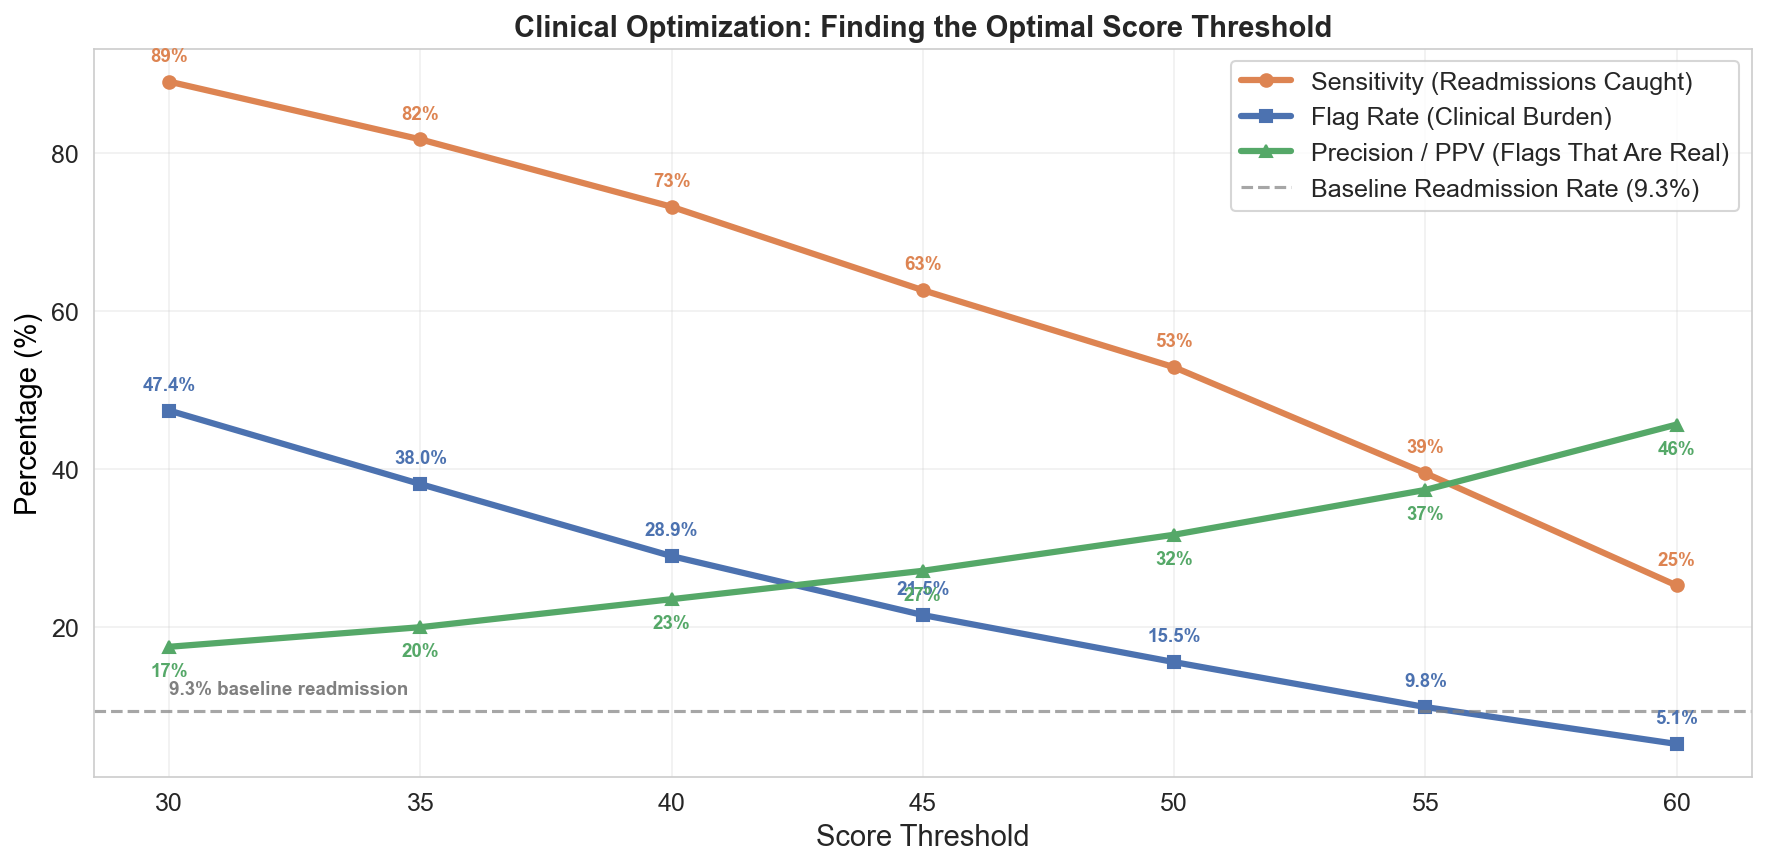

,Threshold,Sensitivity (%),Specificity (%),Precision (%),Flag Rate (%),Total Flagged
0,30,89.0,56.9,17.4,47.4,1256
1,35,81.7,66.4,19.9,38.0,1009
2,40,73.2,75.6,23.5,28.9,767
3,45,62.6,82.8,27.1,21.5,569
4,50,52.8,88.3,31.6,15.5,411
5,55,39.4,93.2,37.3,9.8,260
6,60,25.2,96.9,45.6,5.1,136


In [32]:
# Define a range of potential clinical thresholds
threshold_options = [30, 35, 40, 45, 50, 55, 60]
results_list = []

for t in threshold_options:
    preds = (scores >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_ml, preds).ravel()

    results_list.append({
        'Threshold': t,
        'Sensitivity (%)': (tp / (tp + fn)) * 100,
        'Specificity (%)': (tn / (tn + fp)) * 100,
        'Precision (%)': (tp / (tp + fp)) * 100 if (tp + fp) > 0 else 0,
        'Flag Rate (%)': (preds.mean()) * 100,
        'Total Flagged': preds.sum()
    })

threshold_df = pd.DataFrame(results_list)

# Visualization of the Trade-offs
fig, ax1 = plt.subplots(figsize=(12, 6))

# Plot Sensitivity and Flag Rate
ax1.set_xlabel('Score Threshold')
ax1.set_ylabel('Percentage (%)', color='black')
line1 = ax1.plot(threshold_df['Threshold'], threshold_df['Sensitivity (%)'], marker='o', label='Sensitivity (Readmissions Caught)', color='#DD8452', linewidth=3)
line2 = ax1.plot(threshold_df['Threshold'], threshold_df['Flag Rate (%)'], marker='s', label='Flag Rate (Clinical Burden)', color='#4C72B0', linewidth=3)
line3 = ax1.plot(threshold_df['Threshold'], threshold_df['Precision (%)'], marker='^', label='Precision / PPV (Flags That Are Real)', color='#55A868', linewidth=3)
ax1.tick_params(axis='y')

# Add a horizontal line for the 9.3% base rate for context
ax1.axhline(9.3, color='gray', linestyle='--', alpha=0.7, label='Baseline Readmission Rate (9.3%)')
ax1.text(threshold_df['Threshold'].min(), 11.0, '9.3% baseline readmission', va='bottom', ha='left',
         fontsize=9, color='gray', fontweight='bold')

plt.title('Clinical Optimization: Finding the Optimal Score Threshold', fontsize=14, fontweight='bold')
ax1.legend(loc='upper right')
ax1.grid(True, alpha=0.3)

# Annotate the Flag Rate percentages
for i, txt in enumerate(threshold_df['Flag Rate (%)']):
    ax1.annotate(f"{txt:.1f}%", (threshold_df['Threshold'][i], threshold_df['Flag Rate (%)'][i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold', color='#4C72B0')

# Annotate the Sensitivity percentages
for i, txt in enumerate(threshold_df['Sensitivity (%)']):
    ax1.annotate(f"{txt:.0f}%", (threshold_df['Threshold'][i], threshold_df['Sensitivity (%)'][i]),
                 textcoords="offset points", xytext=(0,10), ha='center', fontsize=9, fontweight='bold', color='#DD8452')

# Annotate the Precision / PPV percentages
for i, txt in enumerate(threshold_df['Precision (%)']):
    ax1.annotate(f"{txt:.0f}%", (threshold_df['Threshold'][i], threshold_df['Precision (%)'][i]),
                 textcoords="offset points", xytext=(0,-14), ha='center', fontsize=9, fontweight='bold', color='#55A868')

plt.tight_layout()
plt.show()

display(threshold_df.round(1))

In [33]:
# 1. Targeted trade-off analysis (40 to 55 in 5-unit increments)

test_thresholds = [40, 45, 50, 55]

for thresh in test_thresholds:
    preds = (df_scored['predicted_score'] >= thresh).astype(int)
    cm = confusion_matrix(df_scored['readmitted'], preds)
    tn, fp, fn, tp = cm.ravel()
    
    sens = tp / (tp + fn)
    spec = tn / (tn + fp)
    flagged_pct = (tp + fp) / len(df_scored) * 100
    
    print(f"Threshold: {thresh} points")
    print(f"  Sensitivity: {sens:.1%} | Specificity: {spec:.1%}")
    print(f"  Flagged for intervention: {flagged_pct:.1f}% of patients")
    print(f"  True Positives (Caught): {tp} | False Negatives (Missed): {fn}")
    print(f"  False Positives (Wasted resources): {fp}")
    print("-" * 50)

Threshold: 40 points
  Sensitivity: 73.2% | Specificity: 75.6%
  Flagged for intervention: 28.9% of patients
  True Positives (Caught): 180 | False Negatives (Missed): 66
  False Positives (Wasted resources): 587
--------------------------------------------------
Threshold: 45 points
  Sensitivity: 62.6% | Specificity: 82.8%
  Flagged for intervention: 21.5% of patients
  True Positives (Caught): 154 | False Negatives (Missed): 92
  False Positives (Wasted resources): 415
--------------------------------------------------
Threshold: 50 points
  Sensitivity: 52.8% | Specificity: 88.3%
  Flagged for intervention: 15.5% of patients
  True Positives (Caught): 130 | False Negatives (Missed): 116
  False Positives (Wasted resources): 281
--------------------------------------------------
Threshold: 55 points
  Sensitivity: 39.4% | Specificity: 93.2%
  Flagged for intervention: 9.8% of patients
  True Positives (Caught): 97 | False Negatives (Missed): 149
  False Positives (Wasted resources):

### **Clinical Tool Implementation Report**
This section summarizes the finalized weightings for the 0–100 risk score and the performance metrics for different staffing capacity levels.

--- Finalized Clinical Risk Weights ---


,Predictor Variable,Points Contribution
18,Suicidal ideation (ICD R45.851),26.700000
14,Depressive disorders (DSM-5 category),18.300000
8,Medical comorbidity (ICD-prefix group flag; not a CCS category),13.600000
17,Psychotic disorders (DSM-5 category),13.300000
4,Physical restraint use,12.700000
13,Conduct disorder (DSM-5 category),10.000000
16,Bipolar disorders (DSM-5 category),8.300000
7,# distinct DSM-5 categories,7.600000
15,Anxiety disorders (DSM-5 category),7.000000
12,Autism spectrum (DSM-5 category),5.600000



--- Threshold Implementation Guide ---


,Score Cutoff,Catch Rate (Sensitivity),Workload (Flag Rate),Expected Alerts (N)
0,30,89.0,47.4,1256
1,35,81.7,38.0,1009
2,40,73.2,28.9,767
3,45,62.6,21.5,569
4,50,52.8,15.5,411
5,55,39.4,9.8,260
6,60,25.2,5.1,136


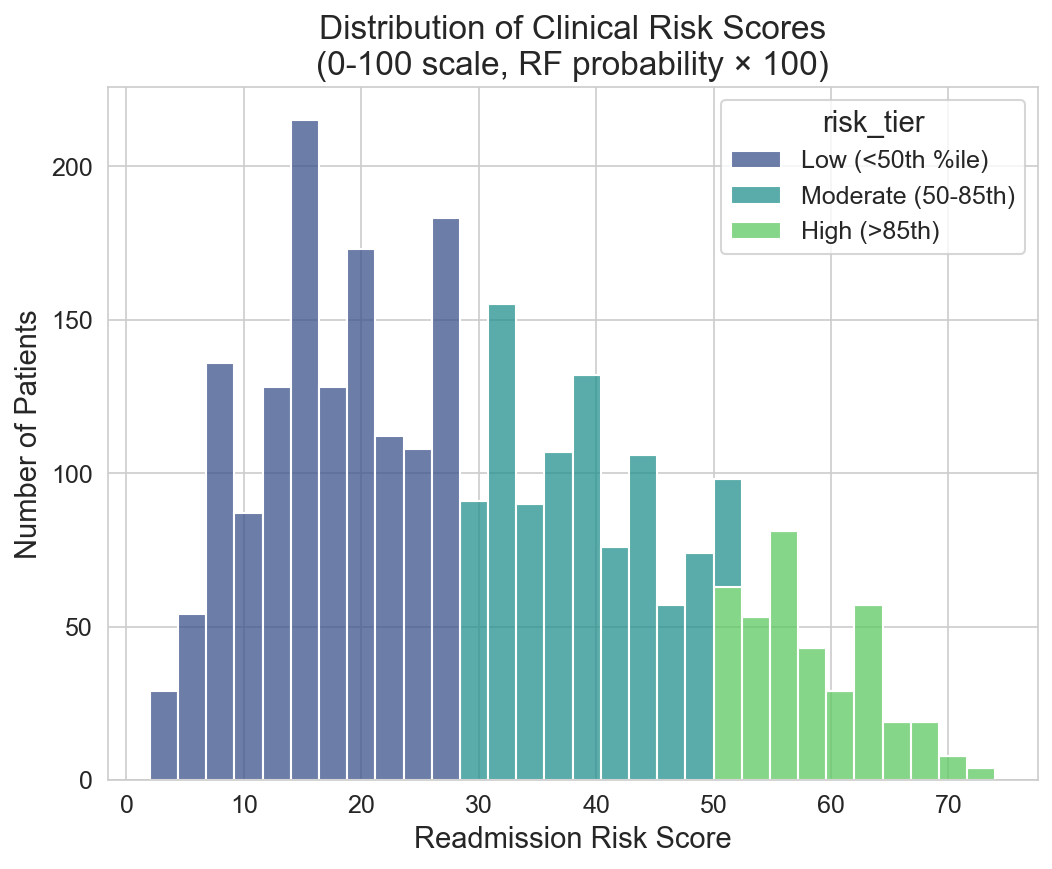

In [34]:
# 1. Clinical risk weight table (LR coefficient-based point system)
weights_report = risk_table.copy()
weights_report.columns = ['Predictor Variable', 'Points Contribution']
print("--- Finalized Clinical Risk Weights ---")
display(weights_report.style.background_gradient(cmap='YlOrRd', subset=['Points Contribution']))

# 2. Threshold implementation guide
threshold_guide = threshold_df[
    ['Threshold', 'Sensitivity (%)', 'Flag Rate (%)', 'Total Flagged']
].copy()
threshold_guide.columns = [
    'Score Cutoff', 'Catch Rate (Sensitivity)', 'Workload (Flag Rate)', 'Expected Alerts (N)'
]
print("\n--- Threshold Implementation Guide ---")
display(threshold_guide.round(1))

# Save
weights_report.to_csv('figures/Clinical_Tool_Weights.csv', index=False)
threshold_guide.to_csv('figures/Threshold_Implementation_Guide.csv', index=False)

# 3. Score distribution by tier
fig, ax = plt.subplots(figsize=(8, 6))
sns.histplot(df_scored, x='predicted_score', hue='risk_tier',
             multiple='stack', bins=30, palette='viridis', ax=ax)
ax.set_title('Distribution of Clinical Risk Scores\n(0-100 scale, RF probability × 100)')
ax.set_xlabel('Readmission Risk Score')
ax.set_ylabel('Number of Patients')
plt.savefig('figures/Fig_Risk_Score_Distribution.png')
plt.show()


In [35]:
# ── Comparison: Regex DSM-5 flags vs PyHealth medical coding ─────────────────
print("\n── Comparing Diagnostic Feature Extraction Methods ──")

# Medical comorbidity: broad regex (any non-F chronic dx) vs narrow PyHealth
# body-system categorization. The main regression uses the broad regex flag.
print("\nMedical Comorbidity (broad regex vs PyHealth body-system mapping):")
regex_med   = df['has_medical_comorbidity'].sum()
ccs_med     = df['has_medical_comorbidity_pyhealth'].sum()
overlap_med = ((df['has_medical_comorbidity'] == 1) & (df['has_medical_comorbidity_pyhealth'] == 1)).sum()
print(f"Broad regex (n_medical_chronic > 0):  {regex_med} patients")
print(f"PyHealth body-system categories:      {ccs_med} patients")
print(f"Overlap:                              {overlap_med} patients")

# Mental-health diagnosis flags now use the complete regex DSM-5 category labels
# (curated *_DSM5Categories text), which the primary logistic regression consumes.
print("\nMental Health Category Flags (regex DSM-5 prevalence used by the model):")
for flag, kw in CATEGORY_FLAGS.items():
    print(f"{flag:>18}: {int(df[flag].sum()):>4} patients")

print("\nNote: a standardized ICD-10→CCS comparison via the genuine PyHealth CrossMap "
      "is provided in the 'PyHealth CCS' supplement section below.")



── Comparing Diagnostic Feature Extraction Methods ──

Medical Comorbidity (broad regex vs PyHealth body-system mapping):
Broad regex (n_medical_chronic > 0):  1703 patients
PyHealth body-system categories:      756 patients
Overlap:                              756 patients

Mental Health Category Flags (regex DSM-5 prevalence used by the model):
          has_nssi:  966 patients
        has_trauma: 1424 patients
          has_adhd: 1399 patients
           has_asd:  513 patients
       has_conduct:  484 patients
    has_depression: 1779 patients
       has_anxiety: 1154 patients
       has_bipolar:  147 patients
     has_psychotic:   55 patients
  has_intellectual:   57 patients
           has_ocd:  114 patients

Note: a standardized ICD-10→CCS comparison via the genuine PyHealth CrossMap is provided in the 'PyHealth CCS' supplement section below.


NameError: name 'Unknown' is not defined

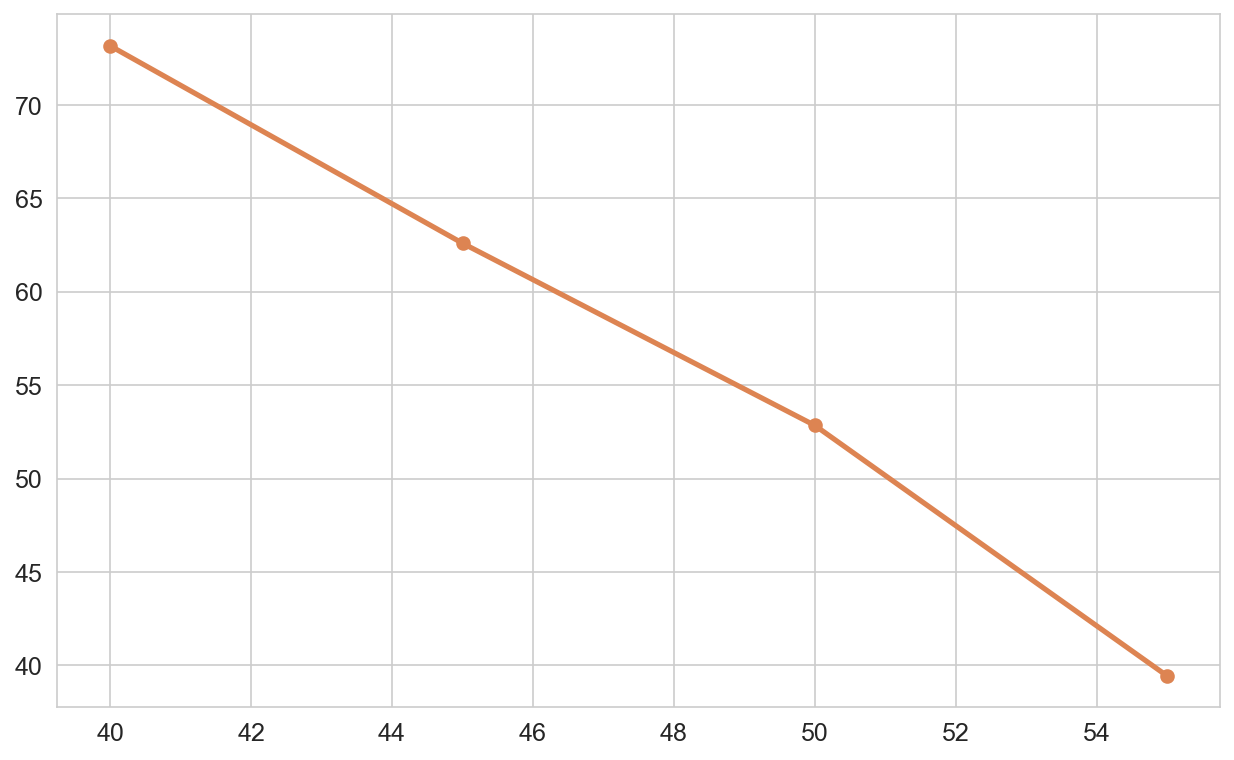

In [53]:
# Filter performance data for the specific range of interest
plot_df = threshold_df[threshold_df['Threshold'].between(40, 55)].copy()
AX2_MAX = 34  # headroom so the ~31% flag bar at threshold 40 (and its label) is fully visible

fig, ax1 = plt.subplots(figsize=(10, 6))

# Sensitivity & Specificity on the primary (0-100) axis
ax1.plot(plot_df['Threshold'], plot_df['Sensitivity (%)'], 'o-', color=ORANGE, label='Sensitivity (Catch Rate)', linewidth=2.5)
for x, y in zip(plot_df['Threshold'], plot_df['Sensitivity (%)']):
    above: Unknown = (x == 40)  # place below here to avoid overlap with specificity label at threshold 40
    ax1.annotate(f'{y:.0f}%', (x, y), textcoords='offset points', xytext=(0, 8 if above else -4),
                 ha='center', fontsize=9, fontweight='bold', color=ORANGE)
ax1.plot(plot_df['Threshold'], plot_df['Specificity (%)'], 's-', color='green', label='Specificity', linewidth=2.5)
# Specificity labels below the points, except threshold 45 placed above (clears the flag-rate label)
for x, y in zip(plot_df['Threshold'], plot_df['Specificity (%)']):
    above = (x == 40)
    ax1.annotate(f'{y:.0f}%', (x, y), textcoords='offset points', xytext=(0, 10 if above else -14),
                 ha='center', fontsize=9, fontweight='bold', color='green', va='bottom' if above else 'top')
ax1.set_xlabel('Score Threshold')
ax1.set_ylabel('Percentage (%)')
ax1.set_ylim(0, 100)

# Flag rate (workload) on the secondary axis — SAME cohort-% scale as the readmission line
ax2 = ax1.twinx()
ax2.bar(plot_df['Threshold'], plot_df['Flag Rate (%)'], alpha=0.2, color=BLUE, width=2, label='Flag Rate (Burden)')
# Flag-rate labels above the bar, but dropped inside for thresholds 50 & 55 where the bar
# top sits at nearly the same pixel height as the sensitivity label.
for x, y in zip(plot_df['Threshold'], plot_df['Flag Rate (%)']):
    below = x in (45, 50, 55)
    ax2.annotate(f'{y:.1f}%', (x, y), textcoords='offset points', xytext=(0, -13 if below else 3),
                 ha='center', fontsize=9, fontweight='bold', color=BLUE, va='top' if below else 'bottom')
# Actual cohort readmission rate — comparable to flag rate (both % of cohort)
ax2.axhline(9.3, color='gray', linestyle='--', alpha=0.8, linewidth=1.5, label='Actual Readmission Rate (9.3%)')
ax2.set_ylabel('Cohort Flag Rate (%)', color=BLUE)
ax2.tick_params(axis='y', labelcolor=BLUE)
ax2.set_ylim(0, AX2_MAX)

ax1.set_title('Clinical Deployment Trade-offs (Thresholds 40-55)')
# One combined legend, parked in the empty wedge between the diverging lines (clear of the tall left bar)
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc='center left', bbox_to_anchor=(0.20, 0.4), framealpha=0.9, fontsize=10)
ax1.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('figures/Fig_clinical_deployment_tradeoffs.png')
plt.show()

### **Subgroup Performance Simulation**
To validate the tool's real-world utility, we simulate the average risk scores for key clinical phenotypes found in the cohort.

In [37]:
# Map the scores back to the original dataframe for subset analysis
df['calculated_risk_score'] = scores

# Clinical subsets, grouped by expected risk direction. Higher-risk markers are drawn
# from the significant positive predictors (medical comorbidity, depression, restraints,
# diagnostic complexity); protective/lower-risk markers from the negative ones (older age).
subsets = {
    'Overall Cohort': df,
    # ── Higher-risk phenotypes ───────────────────────────────────────────────
    'High Complexity (Q4)':        df[df['complexity_q'] == 'Q4 (4+)'],
    'Physical Restraints':         df[df['had_restraints'] == 1],
    'Medical Comorbidity':         df[df['has_medical_comorbidity'] == 1],
    'Depression Dx':               df[df['has_depression'] == 1],
    'Conduct Disorder Present':    df[df['has_conduct'] == 1],
    'Younger (Age <= 9)':          df[df['age'] <= 9],
    'Public Insurance (AHCCCS)':   df[df['insurance_public'] == 1],
    # ── Lower-risk / protective phenotypes ───────────────────────────────────
    'Older (Age >= 11)':           df[df['age'] >= 11],   # cohort is 5-12yo; oldest band is protective
    'Private Ins + No Conduct':    df[(df['insurance_public'] == 0) & (df['has_conduct'] == 0)],
}

sim_results = []
for name, sub_df in subsets.items():
    sim_results.append({
        'Subset': name,
        'N': len(sub_df),
        'Avg Risk Score': sub_df['calculated_risk_score'].mean(),
        '% Above Threshold 40': (sub_df['calculated_risk_score'] >= 40).mean() * 100,
        'Observed Readmission Rate': sub_df['readmitted'].mean() * 100
    })

sim_df = pd.DataFrame(sim_results)
print("--- Patient Subset Risk Simulation (sorted by average risk score) ---")
display(sim_df.sort_values('Avg Risk Score', ascending=False).round(1).reset_index(drop=True))

--- Patient Subset Risk Simulation (sorted by average risk score) ---


,Subset,N,Avg Risk Score,% Above Threshold 40,Observed Readmission Rate
0,High Complexity (Q4),533,45.8,67.0,17.6
1,Conduct Disorder Present,484,37.4,44.8,13.6
2,Physical Restraints,510,36.1,42.0,13.5
3,Depression Dx,1779,35.0,38.2,10.7
4,Medical Comorbidity,1703,34.9,38.7,11.2
5,Younger (Age <= 9),1089,32.5,34.1,10.8
6,Public Insurance (AHCCCS),1589,30.9,29.6,9.8
7,Overall Cohort,2652,30.4,28.9,9.3
8,Private Ins + No Conduct,875,28.1,24.5,7.8
9,Older (Age >= 11),1075,27.7,22.5,7.8


### **Validating Risk Scores against Unsupervised Clusters**
This visualization profiles the clinical risk scores across the data-driven clusters identified by HDBSCAN. This ensures the 0–100 scale remains sensitive to the complex clinical phenotypes (like the ASD/High DSM burden groups) discovered during pattern discovery.

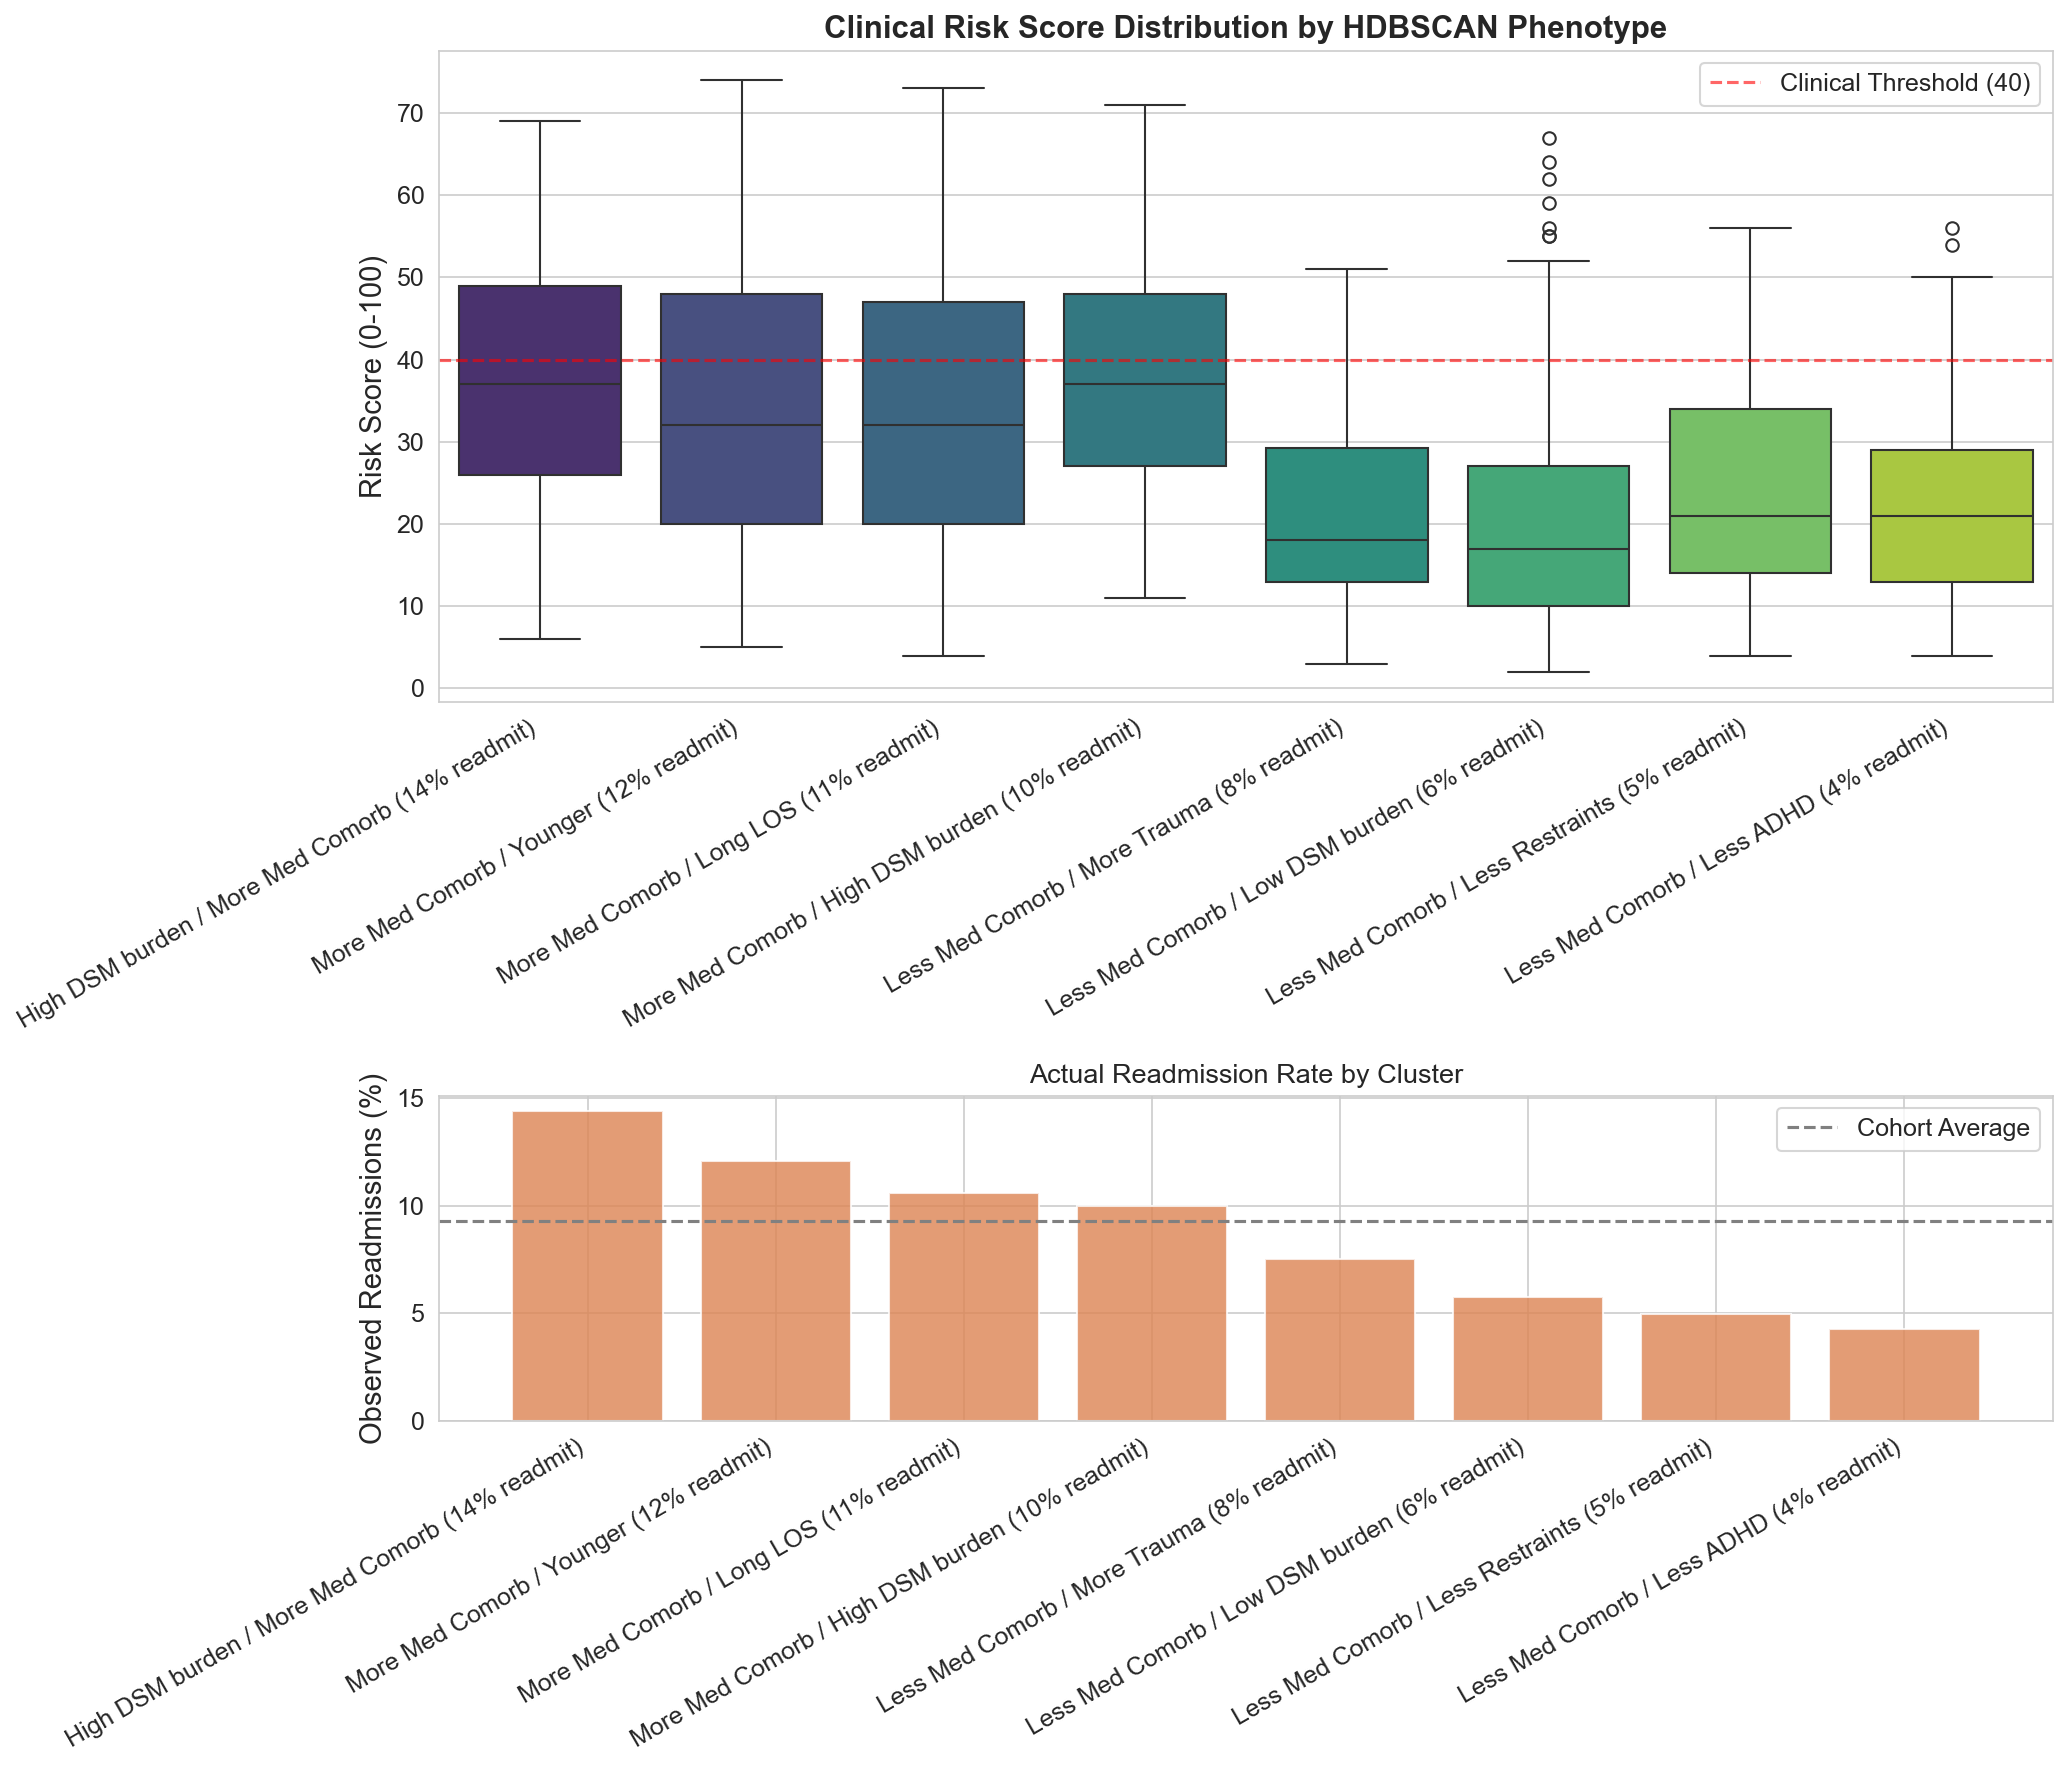

Summary of Top Risk Clusters:


,calculated_risk_score,readmitted
cluster_name,,
High DSM burden / More Med Comorb (14% readmit),37.482,0.144
More Med Comorb / Younger (12% readmit),33.897,0.121
More Med Comorb / Long LOS (11% readmit),33.697,0.106
More Med Comorb / High DSM burden (10% readmit),37.959,0.100
Less Med Comorb / More Trauma (8% readmit),21.725,0.075
Less Med Comorb / Low DSM burden (6% readmit),19.945,0.058
Less Med Comorb / Less Restraints (5% readmit),23.894,0.050
Less Med Comorb / Less ADHD (4% readmit),22.095,0.043


In [38]:
# Ensure cluster and score information is present in the dataframe
mdf_r = model_df_unscaled.copy().reset_index(drop=True)
mdf_r['cluster'] = cluster_labels
mdf_r['calculated_risk_score'] = scores
mdf_r['cluster_name'] = mdf_r['cluster'].map(cluster_names)

# Filter out noise for a cleaner visualization of distinct phenotypes
plot_clusters = mdf_r[mdf_r['cluster'] != -1].copy()

# Sort clusters by their observed readmission rate to see the trend
cluster_order = plot_clusters.groupby('cluster_name')['readmitted'].mean().sort_values(ascending=False).index

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 12), gridspec_kw={'height_ratios': [2, 1]})

# 1. Distribution of Risk Scores by Cluster
sns.boxplot(data=plot_clusters, x='cluster_name', y='calculated_risk_score',
            order=cluster_order, palette='viridis', ax=ax1)
ax1.axhline(40, color='red', linestyle='--', alpha=0.6, label='Clinical Threshold (40)')
ax1.set_title('Clinical Risk Score Distribution by HDBSCAN Phenotype', fontsize=15, fontweight='bold')
ax1.set_xticklabels(ax1.get_xticklabels(), rotation=30, ha='right')
ax1.set_ylabel('Risk Score (0-100)')
ax1.set_xlabel('')
ax1.legend()

# 2. Observed Readmission Rate by Cluster
cluster_stats = plot_clusters.groupby('cluster_name')['readmitted'].mean() * 100
cluster_stats = cluster_stats.reindex(cluster_order)

ax2.bar(cluster_stats.index, cluster_stats.values, color='#DD8452', alpha=0.8)
ax2.axhline(df['readmitted'].mean() * 100, color='gray', linestyle='--', label='Cohort Average')
ax2.set_ylabel('Observed Readmissions (%)')
ax2.set_title('Actual Readmission Rate by Cluster', fontsize=13)
ax2.set_xticklabels(cluster_stats.index, rotation=30, ha='right')
ax2.legend()

plt.tight_layout()
plt.savefig('figures/Fig_Cluster_Risk_Validation.png')
plt.show()

print("Summary of Top Risk Clusters:")
display(plot_clusters.groupby('cluster_name').agg({
    'calculated_risk_score': 'mean',
    'readmitted': 'mean'
}).sort_values('readmitted', ascending=False).round(3))

In [39]:
# ── Staffing Requirement Simulation ──────────────────────────────────────────

# Assumptions based on typical inpatient psychiatric unit workflow:
# 1. Total annual admissions in this simulation context: 2,652
# 2. A 'full' review and intensive follow-up for a high-risk patient takes ~4 hours of clinical time per admission.
# 3. An FTE (Full Time Equivalent) works ~1,800 hours/year.

admissions_per_year = 2652
hours_per_review = 4
hours_per_fte = 1800

results = []
for t in [40, 50, 55]:
    flag_rate = threshold_df.loc[threshold_df['Threshold'] == t, 'Flag Rate (%)'].values[0] / 100
    catch_rate = threshold_df.loc[threshold_df['Threshold'] == t, 'Sensitivity (%)'].values[0]

    n_flagged = admissions_per_year * flag_rate
    total_hours_needed = n_flagged * hours_per_review
    fte_required = total_hours_needed / hours_per_fte

    results.append({
        'Threshold': t,
        'Readmissions Caught (%)': f'{catch_rate:.1f}%',
        'Annual Flagged Patients': int(n_flagged),
        'Clinical Hours Needed': int(total_hours_needed),
        'FTEs Required': round(fte_required, 2)
    })

staffing_df = pd.DataFrame(results)
print("--- Staffing Requirements: Transition-of-Care Simulation ---")
display(staffing_df)

--- Staffing Requirements: Transition-of-Care Simulation ---


,Threshold,Readmissions Caught (%),Annual Flagged Patients,Clinical Hours Needed,FTEs Required
0,40,73.2%,767,3068,1.70
1,50,52.8%,411,1644,0.91
2,55,39.4%,260,1040,0.58


### **Threshold Analysis Summary**

The bullet summary below is generated directly from `threshold_df` (the risk-score sweep
above), so it always reflects the current model rather than transcribed values.

In [40]:
# ── Threshold analysis summary — generated from threshold_df (never hard-coded) ─
baseline = df_scored['readmitted'].mean() * 100
print("Threshold Analysis Summary  (derived from the risk-score sweep above)")
print(f"Cohort baseline readmission rate: {baseline:.1f}%\n")

for t in (40, 50):
    row = threshold_df.loc[threshold_df['Threshold'] == t]
    if row.empty:
        print(f"\u2022 Threshold {t}: not present in threshold_df.")
        continue
    r = row.iloc[0]
    print(
        f"\u2022 Threshold {t}: flags {r['Flag Rate (%)']:.0f}% of admissions "
        f"({int(r['Total Flagged'])} charts) and captures {r['Sensitivity (%)']:.0f}% of "
        f"readmissions (sensitivity), at {r['Precision (%)']:.0f}% precision and "
        f"{r['Specificity (%)']:.0f}% specificity."
    )

print("\nWhich flagging volume best matches your transition-of-care team's capacity?")

Threshold Analysis Summary  (derived from the risk-score sweep above)
Cohort baseline readmission rate: 9.3%

• Threshold 40: flags 29% of admissions (767 charts) and captures 73% of readmissions (sensitivity), at 23% precision and 76% specificity.
• Threshold 50: flags 15% of admissions (411 charts) and captures 53% of readmissions (sensitivity), at 32% precision and 88% specificity.

Which flagging volume best matches your transition-of-care team's capacity?


## Supplement — Genuine PyHealth CCS coding (ICD-10-CM → CCSCM)

The primary regression uses the curated regex DSM-5 category flags. As a standardized-coding
robustness check, this section maps the cohort's raw ICD-10-CM codes to **CCS** categories using
the genuine `pyhealth.medcode.CrossMap` (with a local description fallback), then compares the
hand-built DSM-5 flags against the standardized CCS encoding. Ported from
`Readmission_PyHealth_Advanced.ipynb` (B1–B4). The whole section self-skips if PyHealth is
unavailable, so the rest of the notebook is unaffected.

In [41]:
# ── B1: Collect cohort ICD-10 codes & validate against PyHealth ICD-10-CM ──────
DIAG_COLS = ['VisitDiags', 'ChronicDiags', 'NonSuicidialDiags']

def parse_codes(s):
    """Split a comma-separated ICD code cell into cleaned tokens."""
    if pd.isna(s) or str(s).strip() == '':
        return []
    return [c.strip().upper() for c in str(s).split(',') if c.strip()]

# Per-patient code sets (union across the diagnosis columns; .get guards missing cols)
patient_codes = df.apply(lambda r: sorted({c for col in DIAG_COLS for c in parse_codes(r.get(col))}), axis=1)
all_codes = sorted({c for codes in patient_codes for c in codes})
print(f"Distinct ICD-10 codes in cohort: {len(all_codes):,}")

# ── Load PyHealth ICD-10-CM InnerMap (with local fallback) ────────────────────
USE_PYHEALTH = True
icd = None
try:
    from pyhealth.medcode import InnerMap, CrossMap
    icd = InnerMap.load('ICD10CM')
    print('✓ PyHealth ICD10CM InnerMap loaded.')
except Exception as e:
    USE_PYHEALTH = False
    print(f'⚠ PyHealth unavailable ({e}); falling back to local reference files.')

local_desc = {}
try:
    with open('icd_descriptions_full.json') as fh:
        local_desc = {k.strip().upper(): v for k, v in json.load(fh).items()}
except Exception:
    pass

def pyhealth_lookup(code):
    if icd is None:
        return (code in local_desc, local_desc.get(code, ''))
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            return True, icd.lookup(v)
        except Exception:
            continue
    return False, ''

valid_flags, descriptions = {}, {}
for c in all_codes:
    ok, desc = pyhealth_lookup(c)
    valid_flags[c] = ok
    descriptions[c] = desc

n_valid = sum(valid_flags.values())
print(f"Valid ICD-10-CM codes: {n_valid:,}/{len(all_codes):,} "
      f"({n_valid/max(len(all_codes),1):.1%})")

recon = pd.DataFrame({
    'icd_code': all_codes,
    'valid_icd10cm': [valid_flags[c] for c in all_codes],
    'pyhealth_description': [descriptions[c] for c in all_codes],
})
recon['n_patients'] = [int(sum(c in s for s in patient_codes)) for c in all_codes]
recon = recon.sort_values('n_patients', ascending=False).reset_index(drop=True)
recon.to_csv('figures/PyHealth_ICD_validation.csv', index=False)
print('✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv')

Distinct ICD-10 codes in cohort: 1,863
✓ PyHealth ICD10CM InnerMap loaded.
Valid ICD-10-CM codes: 1,843/1,863 (98.9%)
✓ Saved reconciliation table → figures/PyHealth_ICD_validation.csv


In [42]:
# ── B2: Map ICD-10 codes to standardized CCS categories (PyHealth CrossMap) ────
ccs_map, ccs_labels = None, None
if USE_PYHEALTH:
    try:
        ccs_map = CrossMap.load('ICD10CM', 'CCSCM')
        ccs_labels = InnerMap.load('CCSCM')
        print('✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.')
    except Exception as e:
        print(f'⚠ CCS mapping unavailable ({e}); CCS features will be skipped.')

def code_to_ccs(code):
    if ccs_map is None:
        return (None, None)
    variants = [code, code.replace('.', '')]
    if '.' not in code and len(code) > 3:
        variants.append(code[:3] + '.' + code[3:])
    for v in variants:
        try:
            mapped = ccs_map.map(v)
        except Exception:
            mapped = []
        if mapped:
            cc = mapped[0]
            try:
                lab = ccs_labels.lookup(cc)
            except Exception:
                lab = cc
            return (cc, lab)
    return (None, None)

code2ccs = {c: code_to_ccs(c) for c in all_codes}

# ── Part B: decompose CCS 653 "Residual codes; unclassified" into clinically meaningful groups ──
# PyHealth's ICD10CM→CCSCM CrossMap routes a HETEROGENEOUS set of codes to the catch-all
# "Residual codes; unclassified" — not just organic/neurocognitive F-codes, but sleep-wake (G47),
# symptom (R-) and status/psychosocial (Z-) codes. Treating that bucket as a single comorbidity is
# misleading, so we relabel by code family (genuinely ambiguous codes stay residual). Only codes
# currently in the residual bucket are touched; validly-mapped codes are left untouched.
def _reclass_residual(code, label):
    if label is None or 'residual' not in str(label).lower():
        return None                       # only decompose the residual bucket
    c = code.replace('.', '').upper()
    if c.startswith(('F02','F03','F05','F07','F09')) or c in ('R413','R4182','R404'):
        return ('NEURO_DX', 'Neurocognitive Disorders')        # dementia/delirium/organic + cognitive symptoms
    if c.startswith('G47'):
        return ('SLEEP_DX', 'Sleep-Wake Disorders')
    if c.startswith('Z'):
        return ('ZSTATUS', 'Status/psychosocial (Z-codes)')
    return None                            # leave true residual (e.g. nonspecific R-codes) as-is
_recl = {}
for _c in list(code2ccs.keys()):
    _new = _reclass_residual(_c, code2ccs.get(_c, (None, None))[1])
    if _new is not None:
        code2ccs[_c] = _new
        _recl.setdefault(_new[1], []).append(_c)
print("Part B: decomposed 'Residual codes; unclassified' →")
for _k, _v in _recl.items():
    print(f"   {_k}: {len(_v)} codes  e.g. {sorted(_v)[:6]}")
_still = [c for c,(cc,lab) in code2ccs.items() if lab and 'residual' in str(lab).lower()]
# Eliminate the catch-all entirely: relabel any code still in "Residual codes; unclassified" by family
for _c in list(code2ccs.keys()):
    _cc,_lab=code2ccs.get(_c,(None,None))
    if _lab and 'residual' in str(_lab).lower():
        _n=_c.replace('.','').upper()
        code2ccs[_c]=('OTHER_SX','Other symptoms/signs') if _n.startswith('R') else ('OTHER_UNCL','Other/unclassified (non-specific)')
print(f"   relabeled remaining {len(_still)} code(s) out of 'Residual codes; unclassified' -> Other symptoms/signs or Other")

n_ccs_mapped = sum(1 for v in code2ccs.values() if v[0] is not None)
print(f"Codes mapped to a CCS category: {n_ccs_mapped:,}/{len(all_codes):,} "
      f"({n_ccs_mapped/max(len(all_codes),1):.1%})")

ccs_patient_counts = {}
for codes in patient_codes:
    cats = {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
    for cat in cats:
        ccs_patient_counts[cat] = ccs_patient_counts.get(cat, 0) + 1

ccs_prev = (pd.Series(ccs_patient_counts).sort_values(ascending=False)
            .rename('n_patients').to_frame()) if ccs_patient_counts else pd.DataFrame()
if len(ccs_prev):
    ccs_prev['pct_patients'] = (ccs_prev['n_patients'] / len(df) * 100).round(1)
    print(f"\nDistinct CCS categories present in cohort: {len(ccs_prev)}")
    print('\nTop 15 CCS categories by patient prevalence:')
    print(ccs_prev.head(15).to_string())
else:
    print('No CCS categories mapped — supplement will report unavailable below.')

✓ PyHealth CrossMap ICD10CM→CCSCM and CCSCM labels loaded.
Part B: decomposed 'Residual codes; unclassified' →
   Sleep-Wake Disorders: 15 codes  e.g. ['G47.00', 'G47.01', 'G47.10', 'G47.11', 'G47.19', 'G47.30']
   Neurocognitive Disorders: 3 codes  e.g. ['R40.4', 'R41.3', 'R41.82']
   Status/psychosocial (Z-codes): 51 codes  e.g. ['Z14.1', 'Z14.8', 'Z15.89', 'Z28.82', 'Z72.0', 'Z72.4']
   relabeled remaining 13 code(s) out of 'Residual codes; unclassified' -> Other symptoms/signs or Other
Codes mapped to a CCS category: 1,719/1,863 (92.3%)

Distinct CCS categories present in cohort: 177

Top 15 CCS categories by patient prevalence:
                                                       n_patients  pct_patients
Mood disorders                                               1827          68.9
Anxiety disorders                                            1700          64.1
"Attention-deficit                                           1637          61.7
Suicide and intentional self-inflicted 

In [43]:
# ── B3: Build patient-level CCS comorbidity features ──────────────────────────
ccs_features, ccs_feature_cols, top_ccs = None, [], []
if len(ccs_prev):
    TOP_K_CCS = 15
    top_ccs = list(ccs_prev.head(TOP_K_CCS).index)
    patient_ccs_sets = [
        {code2ccs[c][1] for c in codes if code2ccs.get(c, (None, None))[0] is not None}
        for codes in patient_codes
    ]
    ccs_features = pd.DataFrame(index=df.index)
    ccs_features['readmitted'] = df['readmitted'].values
    ccs_features['n_ccs_categories'] = [len(s) for s in patient_ccs_sets]

    def ccs_colname(label):
        slug = ''.join(ch if ch.isalnum() else '_' for ch in str(label).lower())
        return 'ccs__' + slug[:40].strip('_')

    for cat in top_ccs:
        col = ccs_colname(cat)
        ccs_features[col] = [1 if cat in s else 0 for s in patient_ccs_sets]
        ccs_feature_cols.append(col)

    ccs_features.to_csv('figures/PyHealth_CCS_patient_features.csv', index=False)
    print(f"Built {len(ccs_feature_cols)} CCS indicator features + n_ccs_categories.")
    print(f"Patients with >=1 mapped CCS category: "
          f"{(ccs_features['n_ccs_categories'] > 0).mean():.1%}")
    print('✓ Saved → figures/PyHealth_CCS_patient_features.csv')
else:
    print('⚠ CCS features skipped (no mapping available).')

Built 15 CCS indicator features + n_ccs_categories.
Patients with >=1 mapped CCS category: 100.0%
✓ Saved → figures/PyHealth_CCS_patient_features.csv


Univariate readmission association by CCS category (Haldane-corrected ORs):
                                         CCS category  N exposed    OR  OR_lo  OR_hi     p
               Disorders usually diagnosed in infancy        843 2.137  1.641  2.784 0.000
                                       Mood disorders       1827 1.953  1.410  2.704 0.000
                              Developmental disorders        295 1.944  1.374  2.751 0.000
                            Impulse control disorders        293 1.900  1.339  2.697 0.000
                                    Anxiety disorders       1700 1.860  1.374  2.519 0.000
                                    Attention-deficit       1637 1.850  1.377  2.485 0.000
                         Blindness and vision defects        216 1.606  1.063  2.425 0.024
        Suicide and intentional self-inflicted injury       1428 1.513  1.154  1.982 0.003
                        Status/psychosocial (Z-codes)        288 1.480  1.017  2.152 0.041
              

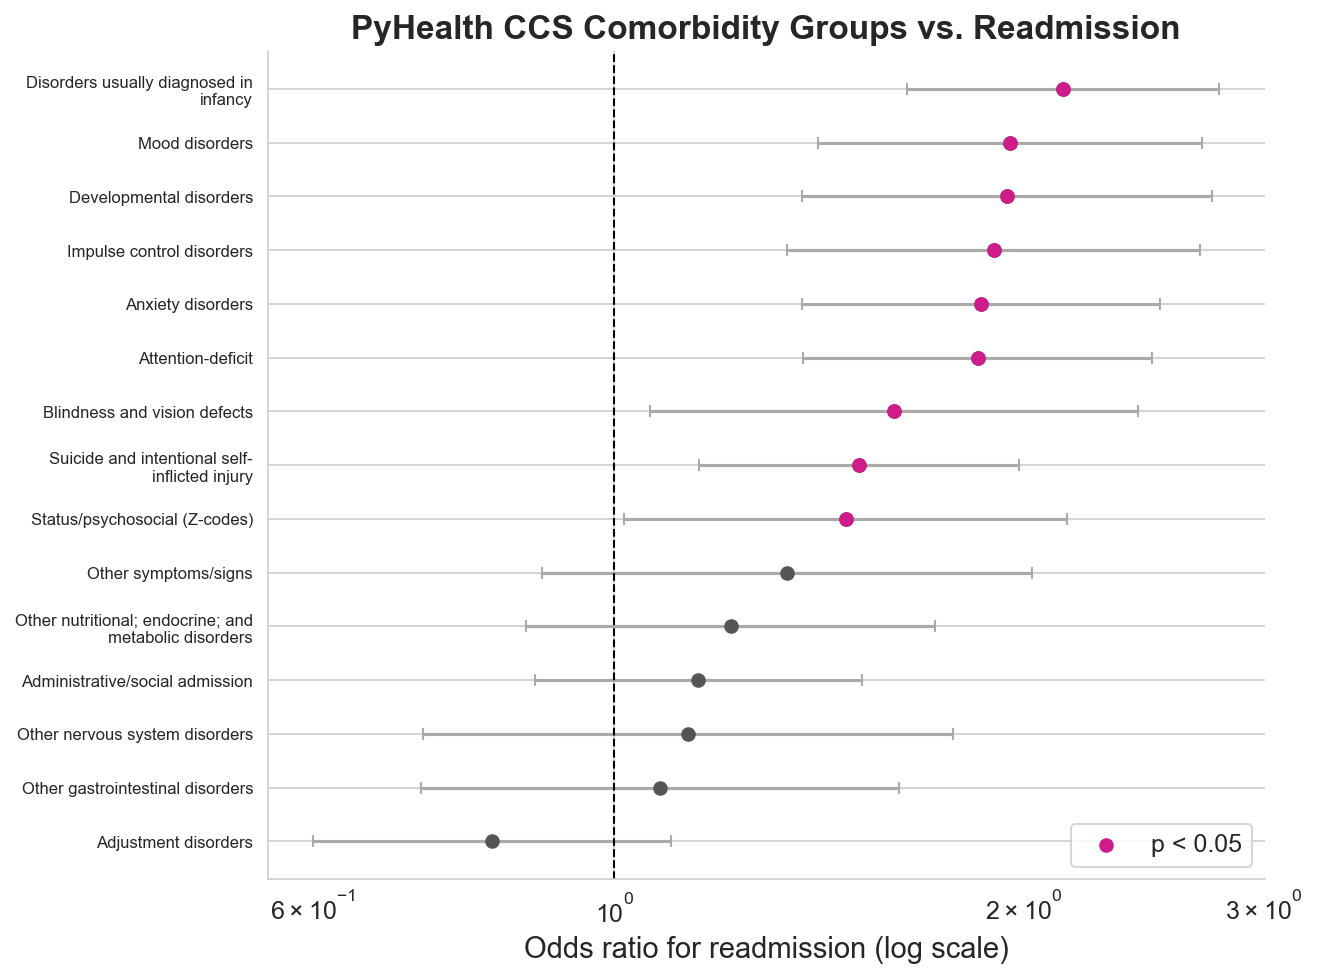


Incremental predictive value (OOF logistic AUC):
  Base (demographic + clinical)      AUC = 0.548
  Base + regex DSM-5 flags           AUC = 0.660
  Base + PyHealth CCS features       AUC = 0.693
  Base + DSM-5 + CCS                 AUC = 0.697
✓ Saved → figures/PyHealth_CCS_forest.png, figures/PyHealth_CCS_associations.csv


In [44]:
# ── B4: CCS readmission associations + comparison vs regex DSM-5 flags ────────
if ccs_features is not None and len(ccs_feature_cols):
    from statsmodels.stats.contingency_tables import Table2x2
    from sklearn.linear_model import LogisticRegression
    from sklearn.model_selection import cross_val_predict

    y_b = ccs_features['readmitted'].values

    rows = []
    for cat, col in zip(top_ccs, ccs_feature_cols):
        x = ccs_features[col].values
        a = int(((x == 1) & (y_b == 1)).sum()); b = int(((x == 1) & (y_b == 0)).sum())
        c = int(((x == 0) & (y_b == 1)).sum()); d = int(((x == 0) & (y_b == 0)).sum())
        tbl = Table2x2(np.array([[a + 0.5, b + 0.5], [c + 0.5, d + 0.5]]))  # Haldane
        rows.append({'CCS category': str(cat).strip('\'"').strip(), 'N exposed': a + b,
                     'OR': tbl.oddsratio, 'OR_lo': tbl.oddsratio_confint()[0],
                     'OR_hi': tbl.oddsratio_confint()[1], 'p': tbl.oddsratio_pvalue()})
    ccs_assoc = pd.DataFrame(rows).sort_values('OR', ascending=False).reset_index(drop=True)
    ccs_assoc.to_csv('figures/PyHealth_CCS_associations.csv', index=False)
    print('Univariate readmission association by CCS category (Haldane-corrected ORs):')
    print(ccs_assoc.round(3).to_string(index=False))

    fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(ccs_assoc))))
    ypos = np.arange(len(ccs_assoc))[::-1]
    sig = ccs_assoc['p'] < 0.05
    ax.errorbar(ccs_assoc['OR'], ypos,
                xerr=[ccs_assoc['OR'] - ccs_assoc['OR_lo'], ccs_assoc['OR_hi'] - ccs_assoc['OR']],
                fmt='o', color='#555', ecolor='#aaa', capsize=3, zorder=2)
    ax.scatter(ccs_assoc.loc[sig, 'OR'], ypos[sig.values], color='#d01c8b', zorder=3, label='p < 0.05')
    ax.axvline(1.0, color='k', ls='--', lw=1)
    ax.set_yticks(ypos); ax.set_yticklabels([__import__('textwrap').fill(str(_l), 34) for _l in ccs_assoc['CCS category']], fontsize=8)  # noqa: E702
    ax.set_xscale('log'); ax.set_xlabel('Odds ratio for readmission (log scale)')  # noqa: E702
    ax.set_title('PyHealth CCS Comorbidity Groups vs. Readmission', fontweight='bold')
    ax.legend(loc='lower right')
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
    plt.tight_layout(); plt.savefig('figures/PyHealth_CCS_forest.png'); plt.show()  # noqa: E702

    # Incremental value: regex DSM-5 flags vs standardized CCS encoding (OOF logistic AUC)
    base_cols = ['age', 'gender_male', 'insurance_public', 'ace_score', 'had_restraints',
                 'csrss_any', 'los_days']
    dsm5_cols = list(CATEGORY_FLAGS)
    base_df = df.copy()
    base_df['ace_score'] = base_df['ace_score'].fillna(base_df['ace_score'].median())
    base_df['los_days']  = base_df['los_days'].fillna(base_df['los_days'].median())

    def oof_auc(frame):
        Xv = frame.values.astype(float)
        lr = LogisticRegression(max_iter=2000, class_weight='balanced')
        p = cross_val_predict(lr, Xv, y_b, cv=cv, method='predict_proba')[:, 1]
        return roc_auc_score(y_b, p)

    feature_sets = {
        'Base (demographic + clinical)': base_df[base_cols],
        'Base + regex DSM-5 flags':      pd.concat([base_df[base_cols], base_df[dsm5_cols]], axis=1),
        'Base + PyHealth CCS features':  pd.concat([base_df[base_cols].reset_index(drop=True),
                                                    ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
        'Base + DSM-5 + CCS':            pd.concat([base_df[base_cols].reset_index(drop=True),
                                                    base_df[dsm5_cols].reset_index(drop=True),
                                                    ccs_features[['n_ccs_categories'] + ccs_feature_cols]], axis=1),
    }
    print('\nIncremental predictive value (OOF logistic AUC):')
    for name, frame in feature_sets.items():
        print(f"  {name:<34} AUC = {oof_auc(frame):.3f}")
    print('✓ Saved → figures/PyHealth_CCS_forest.png, figures/PyHealth_CCS_associations.csv')
else:
    print('⚠ CCS association analysis skipped (no CCS features available).')

## Supplement — Advanced statistical validation

Ported from `Readmission_PyHealth_Advanced.ipynb` (C1–C4): bootstrap confidence intervals for
discrimination, calibration metrics with Platt/isotonic recalibration, formal fairness/equity
metrics, and optimism-corrected validation. All operate on the cross-validated out-of-fold model
predictions already computed above (`lr_probs`, `rf_probs`, `cat_probs`).

In [45]:
# ── Advanced-stats setup: registry of OOF predictions + shared constants ─────
from sklearn.metrics import brier_score_loss, average_precision_score
from sklearn.calibration import calibration_curve

RNG_SEED = 42
MODELS = {'Logistic Regression': lr_probs, 'Random Forest': rf_probs, 'CatBoost': cat_probs}
MODEL_COLORS = {'Logistic Regression': '#2166ac', 'Random Forest': '#4dac26', 'CatBoost': '#d01c8b'}
print("Advanced-stats registry ready:", ", ".join(MODELS))
for name, p in MODELS.items():
    print(f"  {name:<22} AUC={roc_auc_score(y_ml, p):.3f}  AP={average_precision_score(y_ml, p):.3f}")

Advanced-stats registry ready: Logistic Regression, Random Forest, CatBoost
  Logistic Regression    AUC=0.693  AP=0.178
  Random Forest          AUC=0.697  AP=0.178
  CatBoost               AUC=0.665  AP=0.173


Bootstrap 95% CIs (B=2,000, stratified):
                     AUC-ROC  ROC 2.5%  ROC 97.5%  AUC-PR  PR 2.5%  PR 97.5%
Model                                                                       
Logistic Regression    0.693     0.660      0.727   0.178    0.156     0.210
Random Forest          0.697     0.663      0.730   0.178    0.156     0.215
CatBoost               0.665     0.628      0.702   0.173    0.148     0.210


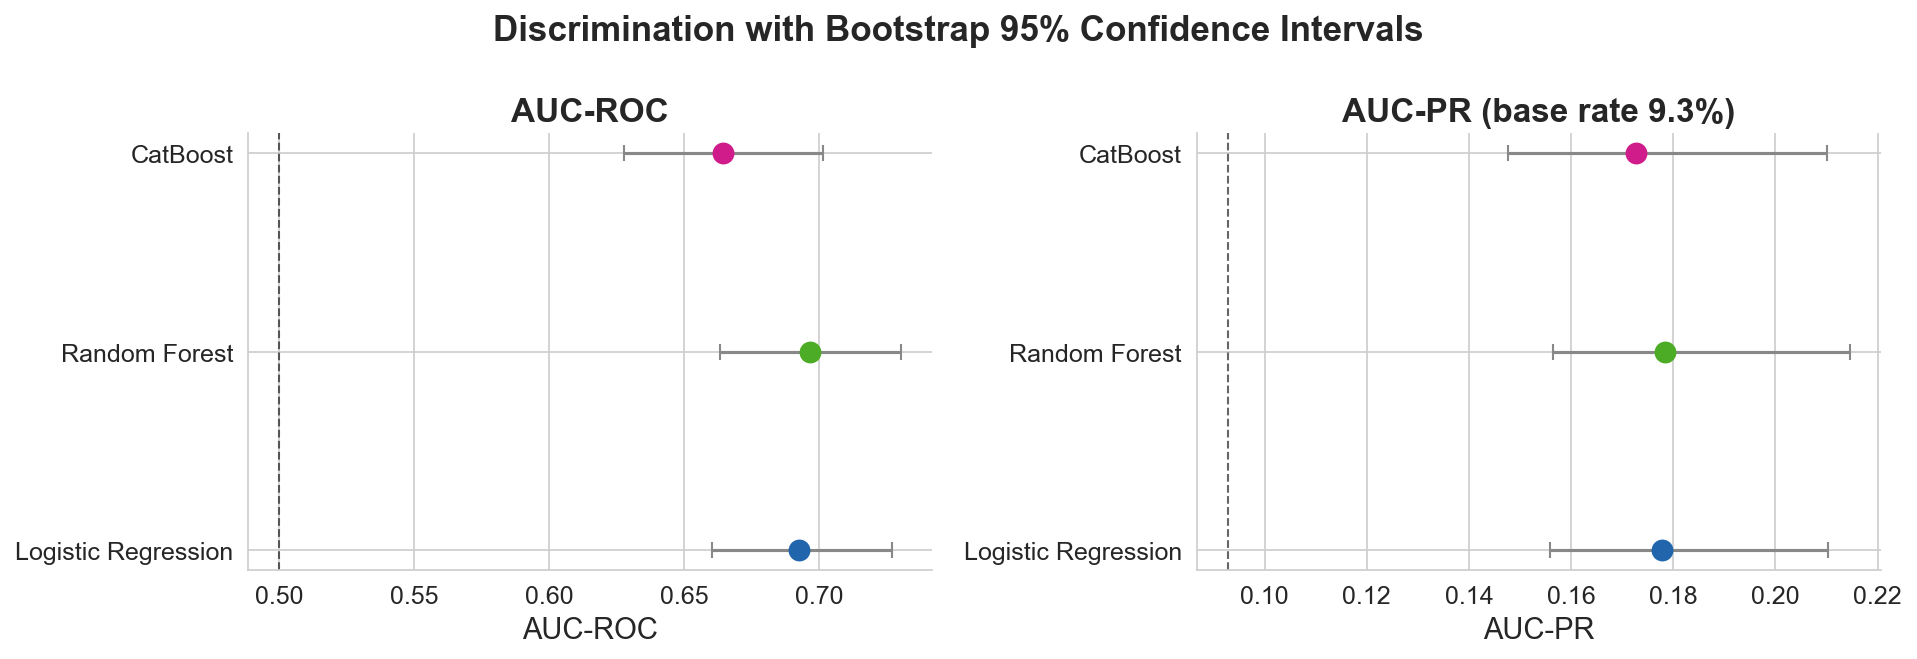

✓ Saved → figures/AdvStats_bootstrap_CIs.png


In [46]:
# ── C1: Bootstrap 95% CIs for AUC-ROC and AUC-PR ──────────────────────────────
def stratified_bootstrap_ci(y_true, y_prob, metric_fn, B=2000, seed=RNG_SEED):
    """Stratified (by class) bootstrap percentile CI for a probability metric."""
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    idx_pos = np.where(y_true == 1)[0]; idx_neg = np.where(y_true == 0)[0]
    brng = np.random.default_rng(seed)
    stats_b = np.empty(B)
    for b in range(B):
        sp = brng.choice(idx_pos, size=len(idx_pos), replace=True)
        sn = brng.choice(idx_neg, size=len(idx_neg), replace=True)
        s = np.concatenate([sp, sn])
        stats_b[b] = metric_fn(y_true[s], y_prob[s])
    point = metric_fn(y_true, y_prob)
    lo, hi = np.percentile(stats_b, [2.5, 97.5])
    return point, lo, hi

ci_rows = []
for name, probs in MODELS.items():
    auc, auc_lo, auc_hi = stratified_bootstrap_ci(y_ml, probs, roc_auc_score)
    ap,  ap_lo,  ap_hi  = stratified_bootstrap_ci(y_ml, probs, average_precision_score)
    ci_rows.append({'Model': name, 'AUC-ROC': auc, 'ROC 2.5%': auc_lo, 'ROC 97.5%': auc_hi,
                    'AUC-PR': ap, 'PR 2.5%': ap_lo, 'PR 97.5%': ap_hi})
ci_df = pd.DataFrame(ci_rows).set_index('Model')
ci_df.to_csv('figures/AdvStats_bootstrap_CIs.csv')
print('Bootstrap 95% CIs (B=2,000, stratified):')
print(ci_df.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for ax, (metric, lo, hi, title) in zip(
        axes, [('AUC-ROC', 'ROC 2.5%', 'ROC 97.5%', 'AUC-ROC'),
               ('AUC-PR', 'PR 2.5%', 'PR 97.5%', 'AUC-PR (base rate 9.3%)')]):
    ypos = np.arange(len(ci_df)); pts = ci_df[metric].values
    err = np.vstack([pts - ci_df[lo].values, ci_df[hi].values - pts])
    ax.errorbar(pts, ypos, xerr=err, fmt='o', capsize=4, color='#444', ecolor='#888')
    for yp, p, m in zip(ypos, pts, ci_df.index):
        ax.scatter([p], [yp], color=MODEL_COLORS[m], s=90, zorder=3)
    ax.set_yticks(ypos); ax.set_yticklabels(ci_df.index)
    ax.set_xlabel(metric); ax.set_title(title, fontweight='bold')
    ax.axvline(0.5 if metric == 'AUC-ROC' else y_ml.mean(), color='k', ls='--', lw=1, alpha=0.6)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
plt.suptitle('Discrimination with Bootstrap 95% Confidence Intervals', fontweight='bold')
plt.tight_layout(); plt.savefig('figures/AdvStats_bootstrap_CIs.png'); plt.show()
print('✓ Saved → figures/AdvStats_bootstrap_CIs.png')

Calibration metrics (lower Brier/ECE = better; HL_p > 0.05 = adequate fit):
              Model Calibration  Brier    ECE   HL_chi2   HL_p    AUC
Logistic Regression         Raw 0.0816 0.0088   16.1467 0.0403 0.6928
Logistic Regression       Platt 0.0812 0.0127    8.7924 0.3601 0.6856
Logistic Regression    Isotonic 0.0813 0.0088   17.7406 0.0233 0.6718
      Random Forest         Raw 0.1732 0.2960 1066.5641 0.0000 0.6968
      Random Forest       Platt 0.0811 0.0039    4.5953 0.7998 0.6907
      Random Forest    Isotonic 0.0816 0.0052   19.8290 0.0110 0.6782
           CatBoost         Raw 0.1456 0.1855  799.5320 0.0000 0.6646
           CatBoost       Platt 0.0818 0.0026    5.8092 0.6686 0.6586
           CatBoost    Isotonic 0.0825 0.0065   21.1623 0.0067 0.6393


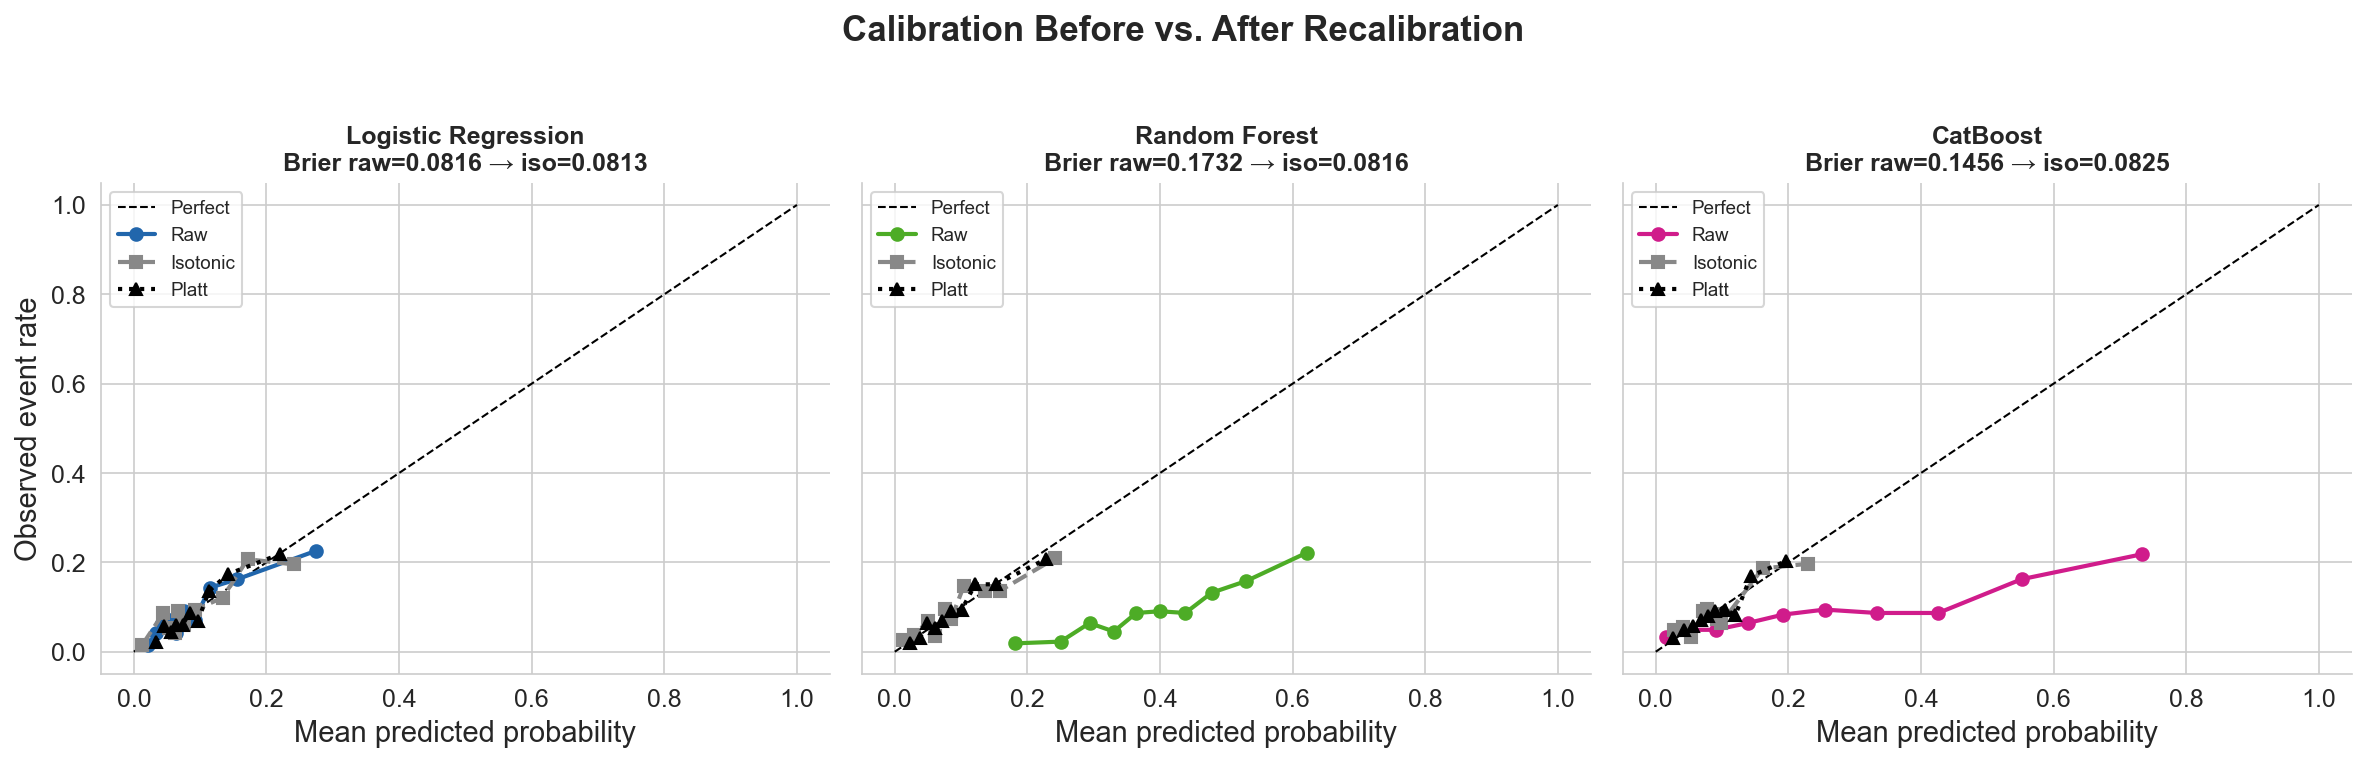

✓ Saved → figures/AdvStats_recalibration.png


In [47]:
# ── C2: Calibration metrics + Platt/isotonic recalibration ────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.isotonic import IsotonicRegression
from sklearn.model_selection import KFold

def expected_calibration_error(y_true, y_prob, n_bins=10):
    bins = np.linspace(0, 1, n_bins + 1)
    idx = np.digitize(y_prob, bins[1:-1])
    ece = 0.0
    for b in range(n_bins):
        m = idx == b
        if m.sum() == 0:
            continue
        ece += (m.mean()) * abs(y_true[m].mean() - y_prob[m].mean())
    return ece

def hosmer_lemeshow(y_true, y_prob, g=10):
    order = np.argsort(y_prob)
    yt = np.asarray(y_true)[order]; yp = np.asarray(y_prob)[order]
    groups = np.array_split(np.arange(len(yp)), g)
    hl = 0.0
    for grp in groups:
        if len(grp) == 0:
            continue
        obs = yt[grp].sum(); exp = yp[grp].sum(); n = len(grp)
        if 0 < exp < n:
            hl += (obs - exp) ** 2 / (exp * (1 - exp / n))
    p = 1 - stats.chi2.cdf(hl, g - 2)
    return hl, p

def recalibrate(y_true, y_prob, method, n_splits=5, seed=RNG_SEED):
    y_true = np.asarray(y_true); y_prob = np.asarray(y_prob)
    out = np.zeros_like(y_prob, dtype=float)
    kf = KFold(n_splits=n_splits, shuffle=True, random_state=seed)
    eps = 1e-6
    for tr, te in kf.split(y_prob):
        if method == 'platt':
            z_tr = np.log(np.clip(y_prob[tr], eps, 1 - eps) / (1 - np.clip(y_prob[tr], eps, 1 - eps)))
            z_te = np.log(np.clip(y_prob[te], eps, 1 - eps) / (1 - np.clip(y_prob[te], eps, 1 - eps)))
            lr = LogisticRegression().fit(z_tr.reshape(-1, 1), y_true[tr])
            out[te] = lr.predict_proba(z_te.reshape(-1, 1))[:, 1]
        else:
            ir = IsotonicRegression(out_of_bounds='clip').fit(y_prob[tr], y_true[tr])
            out[te] = ir.predict(y_prob[te])
    return out

cal_rows = []; recal_store = {}
for name, probs in MODELS.items():
    for label, p in [('Raw', probs), ('Platt', recalibrate(y_ml, probs, 'platt')),
                     ('Isotonic', recalibrate(y_ml, probs, 'isotonic'))]:
        hl, hl_p = hosmer_lemeshow(y_ml, p)
        cal_rows.append({'Model': name, 'Calibration': label,
                         'Brier': brier_score_loss(y_ml, p),
                         'ECE': expected_calibration_error(y_ml, p),
                         'HL_chi2': hl, 'HL_p': hl_p, 'AUC': roc_auc_score(y_ml, p)})
        recal_store[(name, label)] = p
cal_df = pd.DataFrame(cal_rows)
cal_df.to_csv('figures/AdvStats_calibration_metrics.csv', index=False)
print('Calibration metrics (lower Brier/ECE = better; HL_p > 0.05 = adequate fit):')
print(cal_df.round(4).to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
for ax, (name, probs) in zip(axes, MODELS.items()):
    ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect')
    for label, style in [('Raw', dict(marker='o', ls='-', color=MODEL_COLORS[name])),
                         ('Isotonic', dict(marker='s', ls='--', color='#888')),
                         ('Platt', dict(marker='^', ls=':', color='#000'))]:
        p = recal_store[(name, label)]
        frac, mean_pred = calibration_curve(y_ml, p, n_bins=10, strategy='quantile')
        ax.plot(mean_pred, frac, lw=2, markersize=6, label=label, **style)
    b_raw = brier_score_loss(y_ml, recal_store[(name, 'Raw')])
    b_iso = brier_score_loss(y_ml, recal_store[(name, 'Isotonic')])
    ax.set_title(f'{name}\nBrier raw={b_raw:.4f} → iso={b_iso:.4f}', fontweight='bold', fontsize=12)
    ax.set_xlabel('Mean predicted probability'); ax.legend(fontsize=9)
    for sp in ('top', 'right'):
        ax.spines[sp].set_visible(False)
axes[0].set_ylabel('Observed event rate')
plt.suptitle('Calibration Before vs. After Recalibration', fontweight='bold', y=1.02)
plt.tight_layout(); plt.savefig('figures/AdvStats_recalibration.png'); plt.show()
print('✓ Saved → figures/AdvStats_recalibration.png')

Primary fairness model: Random Forest | global threshold (Youden J) = 0.444

Equity panel — Random Forest @ threshold 0.444:
                          N  Events  Event rate  Mean pred    AUC  AUC_lo  AUC_hi    TPR    FPR    FNR    PPV  Alert rate  Calib ratio
Male                 1369.0   134.0       0.098      0.395  0.715   0.673   0.760  0.642  0.317  0.358  0.180       0.349        4.031
Female               1283.0   112.0       0.087      0.383  0.674   0.621   0.723  0.580  0.294  0.420  0.159       0.319        4.383
Public insurance     1589.0   155.0       0.098      0.393  0.696   0.655   0.736  0.606  0.306  0.394  0.176       0.335        4.027
Private insurance    1063.0    91.0       0.086      0.383  0.697   0.643   0.747  0.626  0.306  0.374  0.161       0.333        4.471
Age <=9              1089.0   118.0       0.108      0.411  0.720   0.671   0.765  0.729  0.364  0.271  0.196       0.403        3.794
Age >=10             1563.0   128.0       0.082      0.373  0.665

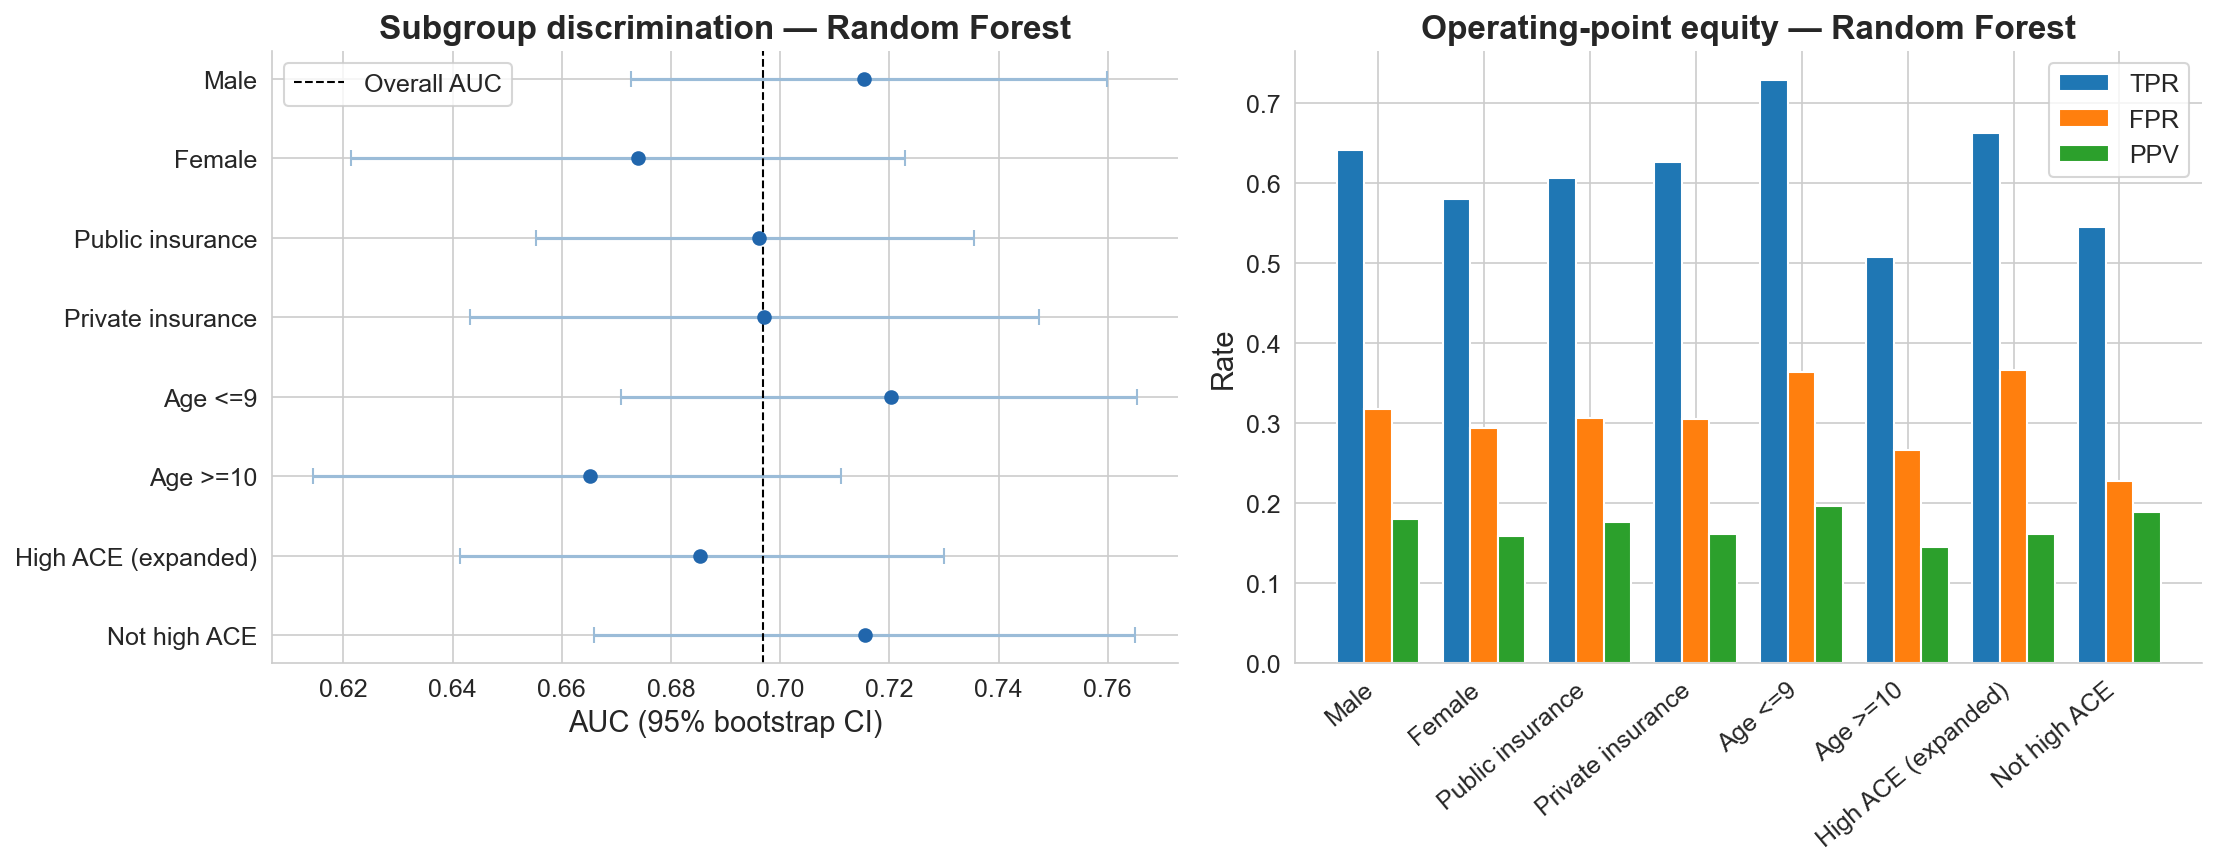

✓ Saved → figures/AdvStats_fairness.png


In [48]:
# ── C3: Fairness / equity metrics across protected subgroups ──────────────────
best_name = max(MODELS, key=lambda n: roc_auc_score(y_ml, MODELS[n]))
best_probs = MODELS[best_name]
fpr_g, tpr_g, thr_g = roc_curve(y_ml, best_probs)
thr_opt = thr_g[np.argmax(tpr_g - fpr_g)]   # Youden's J
print(f"Primary fairness model: {best_name} | global threshold (Youden J) = {thr_opt:.3f}")

mu = model_df_unscaled
_hiace = ((mu['ace_score']>=4) | (mu['ace_score'].between(1,3) & (mu['has_ace_condition']==1))).values
subgroups = {
    'Male': mu['gender_male'].values == 1,           'Female': mu['gender_male'].values == 0,
    'Public insurance': mu['insurance_public'].values == 1,
    'Private insurance': mu['insurance_public'].values == 0,
    'Age <=9': mu['age'].values <= 9,                'Age >=10': mu['age'].values >= 10,
    'High ACE (expanded)': _hiace,          'Not high ACE': ~_hiace,
}

def subgroup_panel(mask, probs, thr):
    yt = y_ml[mask]; pp = probs[mask]; pred = (pp >= thr).astype(int)
    out = {'N': int(mask.sum()), 'Events': int(yt.sum()),
           'Event rate': yt.mean(), 'Mean pred': pp.mean()}
    if yt.sum() >= 5 and (yt == 0).sum() >= 5:
        auc, lo, hi = stratified_bootstrap_ci(yt, pp, roc_auc_score, B=1000)
        out.update({'AUC': auc, 'AUC_lo': lo, 'AUC_hi': hi})
    else:
        out.update({'AUC': np.nan, 'AUC_lo': np.nan, 'AUC_hi': np.nan})
    tn, fp, fn, tp = confusion_matrix(yt, pred, labels=[0, 1]).ravel()
    out['TPR'] = tp / (tp + fn) if (tp + fn) else np.nan
    out['FPR'] = fp / (fp + tn) if (fp + tn) else np.nan
    out['FNR'] = fn / (fn + tp) if (fn + tp) else np.nan
    out['PPV'] = tp / (tp + fp) if (tp + fp) else np.nan
    out['Alert rate'] = pred.mean()
    out['Calib ratio'] = (pp.mean() / yt.mean()) if yt.mean() else np.nan
    return out

fair_df = pd.DataFrame({sg: subgroup_panel(m, best_probs, thr_opt)
                        for sg, m in subgroups.items()}).T
fair_df.to_csv('figures/AdvStats_fairness_subgroups.csv')
print(f"\nEquity panel — {best_name} @ threshold {thr_opt:.3f}:")
print(fair_df.round(3).to_string())

pairings = {'Sex (M vs F)': ('Male', 'Female'),
            'Insurance (Public vs Private)': ('Public insurance', 'Private insurance'),
            'Age (<=9 vs >=10)': ('Age <=9', 'Age >=10'),
            'ACE (>=4 vs <4)': ('High ACE (expanded)', 'Not high ACE')}
disp_rows = []
for label, (a, b) in pairings.items():
    ra, rb = fair_df.loc[a], fair_df.loc[b]
    disp_rows.append({'Pairing': label, 'AUC gap': abs(ra['AUC'] - rb['AUC']),
        'Equalized-odds gap (max|dTPR|,|dFPR|)': max(abs(ra['TPR'] - rb['TPR']), abs(ra['FPR'] - rb['FPR'])),
        'Demographic-parity diff (|d alert|)': abs(ra['Alert rate'] - rb['Alert rate']),
        'FNR gap': abs(ra['FNR'] - rb['FNR'])})
disp_df = pd.DataFrame(disp_rows).set_index('Pairing')
disp_df.to_csv('figures/AdvStats_fairness_disparities.csv')
print('\nDisparity summary (0 = parity; larger = more inequitable):')
print(disp_df.round(3).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
order = list(subgroups.keys()); ypos = np.arange(len(order))[::-1]
auc_pt = fair_df.loc[order, 'AUC'].values.astype(float)
err = np.vstack([auc_pt - fair_df.loc[order, 'AUC_lo'].values.astype(float),
                 fair_df.loc[order, 'AUC_hi'].values.astype(float) - auc_pt])
axes[0].errorbar(auc_pt, ypos, xerr=err, fmt='o', capsize=4, color='#2166ac', ecolor='#9bbcd8')
axes[0].axvline(roc_auc_score(y_ml, best_probs), color='k', ls='--', lw=1, label='Overall AUC')
axes[0].set_yticks(ypos); axes[0].set_yticklabels(order)
axes[0].set_xlabel('AUC (95% bootstrap CI)')
axes[0].set_title(f'Subgroup discrimination — {best_name}', fontweight='bold'); axes[0].legend()
for sp in ('top', 'right'):
    axes[0].spines[sp].set_visible(False)
metrics_bar = ['TPR', 'FPR', 'PPV']; xb = np.arange(len(order)); w = 0.26
for k, met in enumerate(metrics_bar):
    axes[1].bar(xb + (k - 1) * w, fair_df.loc[order, met].values.astype(float), w, label=met)
axes[1].set_xticks(xb); axes[1].set_xticklabels(order, rotation=40, ha='right')
axes[1].set_ylabel('Rate'); axes[1].set_title(f'Operating-point equity — {best_name}', fontweight='bold')
axes[1].legend()
for sp in ('top', 'right'):
    axes[1].spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_fairness.png'); plt.show()
print('✓ Saved → figures/AdvStats_fairness.png')

Logistic Regression    apparent=0.735  optimism=0.026  corrected=0.709
Random Forest          apparent=0.862  optimism=0.099  corrected=0.763
CatBoost               apparent=0.907  optimism=0.112  corrected=0.795

Nested-CV AUC — Random Forest: 0.684 | CatBoost: 0.699

Validation summary:
                     Apparent AUC  Optimism  Bootstrap-corrected AUC  10-fold OOF AUC  Nested-CV AUC
Model                                                                                               
Logistic Regression         0.735     0.026                    0.709            0.693            NaN
Random Forest               0.862     0.099                    0.763            0.697          0.684
CatBoost                    0.907     0.112                    0.795            0.665          0.699


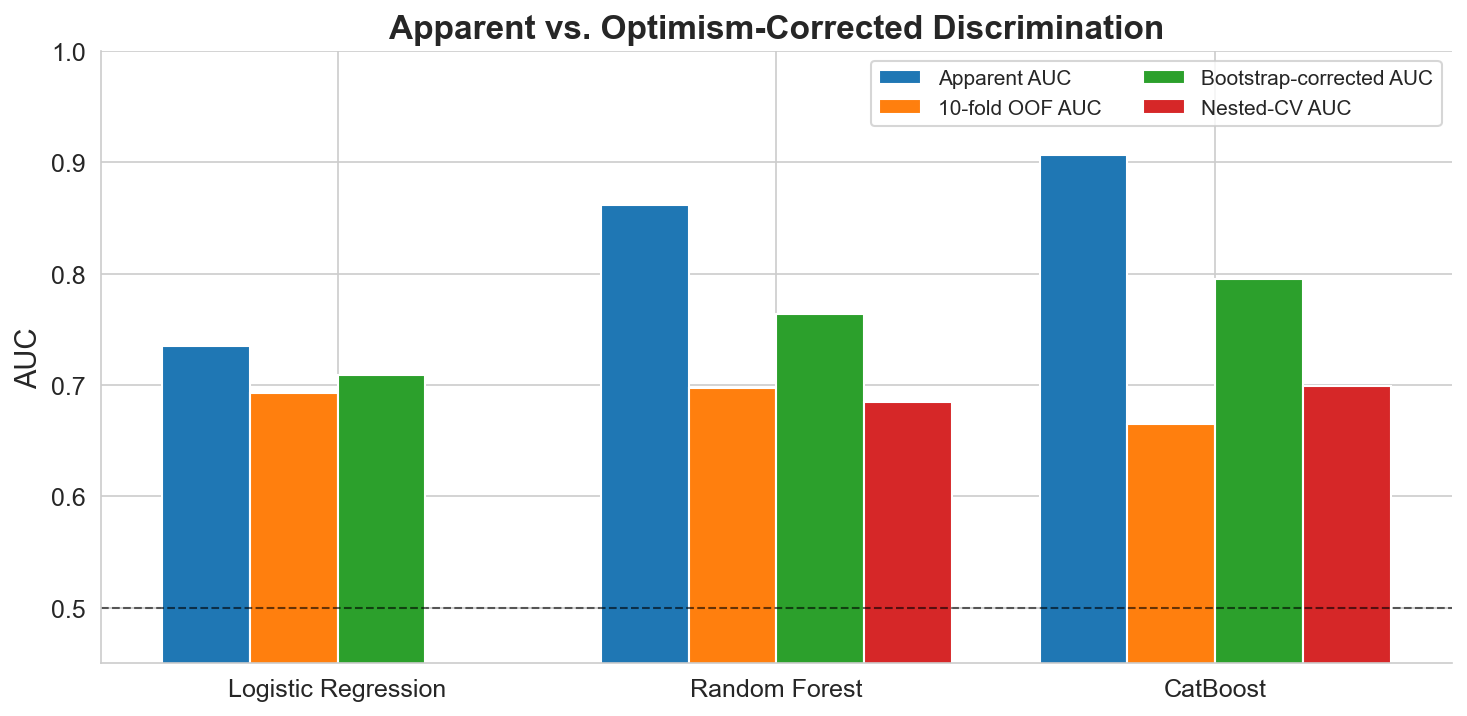

✓ Saved → figures/AdvStats_optimism_validation.png


In [49]:
# ── C4: Optimism-corrected validation (bootstrap + nested CV) ─────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, cross_val_score

def fit_lr(Xtr, ytr):
    return LogisticRegression(max_iter=2000, class_weight='balanced').fit(Xtr, ytr)
def fit_rf(Xtr, ytr):
    return RandomForestClassifier(n_estimators=400, max_depth=6, min_samples_leaf=10,
                                  class_weight='balanced', random_state=RNG_SEED, n_jobs=-1).fit(Xtr, ytr)
def fit_cb(Xtr, ytr):
    m = CatBoostClassifier(iterations=250, depth=4, learning_rate=0.05,
                           auto_class_weights='Balanced', random_seed=RNG_SEED, verbose=0)
    return m.fit(Xtr, ytr)

FITTERS = {'Logistic Regression': fit_lr, 'Random Forest': fit_rf, 'CatBoost': fit_cb}
B_OPT = {'Logistic Regression': 200, 'Random Forest': 150, 'CatBoost': 100}

def bootstrap_optimism(fitter, X, y, B, seed=RNG_SEED):
    """Harrell-Steyerberg optimism correction for AUC."""
    full = fitter(X, y)
    apparent = roc_auc_score(y, full.predict_proba(X)[:, 1])
    brng = np.random.default_rng(seed)
    n = len(y); opt = []
    for _ in range(B):
        idx = brng.integers(0, n, n)
        if y[idx].sum() < 2 or (y[idx] == 0).sum() < 2:
            continue
        mb = fitter(X[idx], y[idx])
        opt.append(roc_auc_score(y[idx], mb.predict_proba(X[idx])[:, 1]) -
                   roc_auc_score(y, mb.predict_proba(X)[:, 1]))
    optimism = float(np.mean(opt))
    return apparent, optimism, apparent - optimism

opt_rows = []
for name, fitter in FITTERS.items():
    app, optimism, corrected = bootstrap_optimism(fitter, X_ml, y_ml, B_OPT[name])
    opt_rows.append({'Model': name, 'Apparent AUC': app, 'Optimism': optimism,
                     'Bootstrap-corrected AUC': corrected,
                     '10-fold OOF AUC': roc_auc_score(y_ml, MODELS[name])})
    print(f"{name:<22} apparent={app:.3f}  optimism={optimism:.3f}  corrected={corrected:.3f}")

nested = {}
rf_grid = {'max_depth': [4, 6], 'min_samples_leaf': [10, 20]}
cb_grid = {'depth': [3, 4], 'learning_rate': [0.03, 0.05]}
nested['Random Forest'] = cross_val_score(
    GridSearchCV(RandomForestClassifier(n_estimators=300, class_weight='balanced',
                                         random_state=RNG_SEED, n_jobs=-1),
                 rf_grid, cv=3, scoring='roc_auc'), X_ml, y_ml, cv=5, scoring='roc_auc').mean()
nested['CatBoost'] = cross_val_score(
    GridSearchCV(CatBoostClassifier(iterations=200, auto_class_weights='Balanced',
                                    random_seed=RNG_SEED, verbose=0),
                 cb_grid, cv=3, scoring='roc_auc'), X_ml, y_ml, cv=5, scoring='roc_auc').mean()
print(f"\nNested-CV AUC — Random Forest: {nested['Random Forest']:.3f} | CatBoost: {nested['CatBoost']:.3f}")

opt_df = pd.DataFrame(opt_rows).set_index('Model')
opt_df['Nested-CV AUC'] = pd.Series(nested)
opt_df.to_csv('figures/AdvStats_optimism_validation.csv')
print('\nValidation summary:')
print(opt_df.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 5))
cols_plot = ['Apparent AUC', '10-fold OOF AUC', 'Bootstrap-corrected AUC', 'Nested-CV AUC']
xb = np.arange(len(opt_df)); w = 0.2
for k, col in enumerate(cols_plot):
    ax.bar(xb + (k - 1.5) * w, opt_df[col].values.astype(float), w, label=col)
ax.axhline(0.5, color='k', ls='--', lw=1, alpha=0.6)
ax.set_xticks(xb); ax.set_xticklabels(opt_df.index)
ax.set_ylabel('AUC'); ax.set_ylim(0.45, 1.0)
ax.set_title('Apparent vs. Optimism-Corrected Discrimination', fontweight='bold')
ax.legend(fontsize=10, ncol=2)
for sp in ('top', 'right'):
    ax.spines[sp].set_visible(False)
plt.tight_layout(); plt.savefig('figures/AdvStats_optimism_validation.png'); plt.show()
print('✓ Saved → figures/AdvStats_optimism_validation.png')